# PJT07 pipeline: from the data split to the inputs for RQ7.3

**COS 801 · Group 6 · Lightweight crop disease diagnosis for deployment on low-cost devices**

One notebook for the whole study up to the end of RQ7.2. It merges `COS801_Compression_Final.ipynb`, `export_benchmarks.ipynb` and
`rq72_v3.ipynb` without changing their methods, and writes to the same folders, so every result already on the
shared drive is picked up and skipped rather than recomputed.

| Part | What it does | From | Writes (under the shared drive) |
|---|---|---|---|
| 0 Setup | installs, Drive, settings | | |
| 1 Shared code | data handling, augmentation arms, model, metrics, training loop, analysis | rq72_v3 §1–10 | nothing (definitions) |
| 2 Data | checks the two split files, builds the image cache, previews the arms | rq72_v3 §3, subsample.py | `data/data_split_resolved.csv` only if it is missing |
| 3 Baselines | scores the two group baselines on lab and field | rq72_v3 §9 | `results/rq72_aligned/B*__seed0/` |
| 4 RQ7.1 compression | pruning, distillation, PTQ and QAT of both baselines | COS801_Compression_Final | `results/aligned_compression_partial/`, `models/aligned_compression_partial/` |
| 5 RQ7.2 | 5 augmentation arms × 3 seeds; the gap and what reduces it | rq72_v3 §6–11 | `results/rq72_aligned/` |
| 6 RQ7.1 × RQ7.2 | compressed models scored lab vs field; augment, then compress | rq72_v3 §12 | `results/rq72_compressed/` |
| 7 Export | ONNX / TFLite files, their size, CPU latency and accuracy | export_benchmarks | `results/rq71_exports_<machine>/` |
| 8 RQ7.3 inputs | logits on lab_val / lab_test / field_test, a preprocessing helper, the handoff file | new | `results/rq73_inputs/` |

**Inputs, made elsewhere:** the split CSV (the data pipeline) and the two baseline checkpoints (their training
notebooks). **Not here:** RQ7.3 itself; Part 8 ends where it begins.

**Run it top to bottom.** Every heavy step saves to the drive as it goes and skips what is already done, so after
a Colab disconnect you mount Drive and run from the top again. 

## Part 0 · Setup

**Colab:** Runtime → Change runtime type → T4 GPU, then run 0.1–0.6. **Locally:** set `PIPELINE["local_root"]`
(or the `RQ72_ROOT` environment variable) to the shared drive folder; Google Drive for desktop on a Mac is found
automatically.

In [2]:
# 0.1 Install. Colab already has torch, torchvision, numpy, pandas, pillow and matplotlib; these lines then only add
#     what is missing. Locally, run once in your environment and restart the kernel afterwards.
DO_TFLITE = True   # Part 7 also converts to TFLite: needs TensorFlow and onnx2tf (a large install)

%pip install -q numpy pandas pillow matplotlib scikit-learn tqdm psutil torch torchvision onnx onnxruntime onnxscript
if DO_TFLITE:
    %pip install -q tensorflow tf-keras onnx2tf onnx-graphsurgeon sng4onnx onnxsim simple-onnx-processing-tools flatbuffers h5py ml-dtypes ai-edge-litert


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
# 0.2 Colab only: mount Google Drive. The shared drive holds the data, the baseline models and every result.
import os
if "COLAB_RELEASE_TAG" in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
    !nvidia-smi --query-gpu=name,memory.total --format=csv

In [4]:
from __future__ import annotations

import argparse
import ast
import copy
import hashlib
import io
import json
import math
import os
import random
import shutil
import sys
import time
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFilter

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision
import torchvision.transforms as T

# used by Part 4 (compression) and Part 7 (export)
import gc
import gzip
import platform
import re
import subprocess
import urllib.parse
import warnings
from datetime import datetime

import matplotlib.pyplot as plt
import torch.nn.functional as F
import torch.nn.utils.prune as prune
import torch.optim as optim
from IPython.display import display
from PIL import UnidentifiedImageError
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.ao.quantization import (FakeQuantize, HistogramObserver, MinMaxObserver, MovingAverageMinMaxObserver,
                                   MovingAveragePerChannelMinMaxObserver, PerChannelMinMaxObserver, QConfig,
                                   QConfigMapping, disable_observer)
from torch.ao.quantization.quantize_fx import convert_fx, prepare_fx, prepare_qat_fx
from torchvision import transforms
from torchvision.models import efficientnet_b0, mobilenet_v3_small
from tqdm.auto import tqdm

/Users/shreyabharat/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# 0.4 Pipeline settings: the cell to edit. Paths are relative to the shared drive root.
PIPELINE = {
    # Local runs only: the shared drive folder. None = $RQ72_ROOT, then Google Drive for desktop, then this folder.
    "local_root": None,
    # The group's split, in two files with the same rows (Part 2 checks this):
    "full_manifest": "data/old_split_files/data_split_resolved.csv", # all 25,108 lab_train images: RQ7.2, Parts 7-8
    "subset_manifest": "data/data_split_resolved.csv", # + use_50pct: RQ7.1 training and Part 6 fine-tunes
    # The baselines, trained in their own notebooks. Their outputs are scored here, not retrained.
    "baselines": {
        "mobilenet_v3_small": "models/mobilenetv3_baseline_best.pth",
        "efficientnet_b0": "models/effnetb0_baseline_best.pth",
    },
    "rq72_time_budget_h": 4,   # the RQ7.2 sweep starts no run it cannot finish in time; rerun to continue
    "rq72_lab_cap": None,      # e.g. 400 lab_train images per class for a quick sweep (written to its own folder)
}

# Heavy steps. Everything resumes and skips finished work, so leaving a step on is safe; switch it off to save the
# time spent checking (and loading data for) a step you do not need in this session.
STAGES = {
    "rq71_compression": True, # Part 4: pruning, KD, PTQ and QAT (skips every model already in its CSVs)
    "rq71_ensembles": False, # Part 4: exploratory stacking of compressed EfficientNets (slow; results not saved)
    "rq72_smoke": False, # Part 5: a 2-minute plumbing test of the training loop
    "rq72_sweep": True, # Part 5: 5 augmentation arms x 3 seeds
    "joint_a": True, # Part 6A: every compressed model scored lab vs field (minutes)
    "joint_b": True, # Part 6B: augment, then compress (about 2 h on a T4)
    "joint_c": False, # Part 6C: compress, then augment (exploratory, about 12 h)
    "export": True, # Part 7: ONNX / TFLite export and CPU benchmark
    "rq73_inputs": True, # Part 8: logits and the handoff file for RQ7.3
}

### 0.5 RQ7.2 configuration: the group baseline recipe

**A0 is the group baseline.** The settings below copy the two baseline notebooks
(`COS801_mobilenetv3_baselinemodel` and `EfficientNetB0_Baseline_Training`):
the same split CSV, class order, ImageNet-pretrained backbone, 224 px input,
training augmentation, AdamW at 1e-3 with weight decay 1e-4 and a cosine schedule,
batch 32, uniform shuffling, full precision, deterministic cuDNN, seed 42, and the
best epoch chosen on validation accuracy. Epochs depend on the backbone
(`BASELINE_RECIPES`: 10 for MobileNetV3-Small, 5 for EfficientNet-B0).

In [ ]:
# 0.5 RQ7.2 configuration (the training recipe; paths come from 0.4)
CONFIG = {
    # where things live
    "colab_root": "/content/drive/Shareddrives/COS 801 Group 6",
    "local_root": os.environ.get("RQ72_ROOT", str(Path.cwd())),
    "manifest": None, # split CSV, relative to root. None = auto-find under <root>/data
    "results_dir": "results/rq72_aligned",  # relative to root, so on Colab it is on Drive and survives disconnects
    "cache_dir": None, # None = /content/rq72_cache_v2 on Colab, <root>/cache/rq72_v2 locally
    "cache_images": True, # downsized local copies; Drive reads are far too slow to train from
    "cache_max_side": 320, # only ever downscales; every arm and both test sets see the same cache
    "cache_archive": True, # Colab only: keep a zip of the cache on Drive and unzip it each session

    # manifest columns. None = auto-detect, and `check` prints what it found
    "path_col": "path",
    "label_col": None,
    "split_col": None,
    "domain_col": None,
    "group_col": None, # near-duplicate group id, if the manifest has one

    # THE GROUP'S BASELINE RECIPE (COS801_mobilenetv3_baselinemodel / EfficientNetB0_Baseline_Training)
    # A0 is trained exactly this way, so it is the group baseline; the arms change the augmentation only.
    "backbone": "mobilenet_v3_small",  # copied from the teammate's checkpoint in the notebook
    "pretrained": True, # ImageNet weights, as in both baseline notebooks
    "pretrained_path": None, # local ImageNet .pth, if downloading weights fails; see section 9
    "img_size": 224,
    "epochs": 10, # MobileNetV3-Small baseline: 10; EfficientNet-B0 baseline: 5 (BASELINE_RECIPES)
    "batch_size": 32,
    "lr": 1e-3, # AdamW, cosine schedule over all epochs
    "weight_decay": 1e-4,
    "label_smoothing": 0.0,
    "balanced_sampling": False, # baselines shuffle uniformly; True draws classes equally instead
    "a0_rotation": 10, # baselines: Resize, RandomHorizontalFlip, RandomRotation(10) with black fill
    "select_metric": "accuracy",  # baselines keep the epoch with the best validation accuracy
    "deterministic": True, # baselines set cudnn.deterministic=True, benchmark=False
    "class_order": [ # the group's canonical label order (shared_class_labels.py, SHARED_CLASSES)
        "apple_scab", "apple_rust", "apple_healthy", "blueberry_healthy", "cherry_healthy",
        "corn_gray_spot", "corn_rust", "corn_blight", "grape_black_rot", "grape_healthy",
        "peach_healthy", "pepper_healthy", "potato_early_blight", "potato_late_blight",
        "raspberry_healthy", "soybean_healthy", "squash_mildew", "strawberry_healthy",
        "tomato_bacterial_spot", "tomato_early_blight", "tomato_late_blight", "tomato_leaf_mold",
        "tomato_septoria", "tomato_yellow_virus", "tomato_mosaic_virus", "tomato_healthy"],

    # the experiment
    "arms": ["A0_none", "A1_geometric", "A2_photometric", "A3_degradation", "A4_combined"],
    "seeds": [42, 43, 44], # 42 is the baselines' seed
    "max_lab_train_per_class": None,  # e.g. 400 to shorten runs; applied identically to every arm
    "time_budget_h": None, # stop starting new runs once the next one would overrun this; rerun to continue
    "drop_field_conflicts": False, # True removes the 11 PlantDoc images filed under two diseases (see section 3).
                                   # False keeps the group's 2,499-image field test set.
    "num_workers": None, # None = chosen per platform
    "use_amp": False, # the baselines train in full precision

    # analysis
    "n_boot": 2000,
    "ece_bins": 15,
    "smoke": False,
}

# Per-backbone settings from the two baseline notebooks; everything else is shared and lives in CONFIG.
BASELINE_RECIPES = {
    "mobilenet_v3_small": {"epochs": 10},
    "efficientnet_b0": {"epochs": 5},
}

SMOKE_OVERRIDES = {
    "arms": ["A0_none", "A4_combined"],
    "seeds": [42],
    "epochs": 1,
    "max_lab_train_per_class": 16,
    "max_eval_per_split": 200,
    "results_dir": "results/rq72_smoke_aligned",
    "n_boot": 200,
    "smoke": True,
}


def make_config(smoke: bool = False, **overrides) -> dict:
    cfg = copy.deepcopy(CONFIG)
    if smoke:
        cfg.update(SMOKE_OVERRIDES)
    cfg.update(overrides)
    return cfg

In [ ]:
# 0.6 Environment: Colab or local, device, and the shared drive root
def _in_notebook() -> bool:
    return "ipykernel" in sys.modules


IN_COLAB = "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules
IN_NOTEBOOK = _in_notebook()


def get_root(cfg: dict) -> Path:
    if IN_COLAB:
        root = Path(cfg["colab_root"])
        if not root.exists():
            if IN_NOTEBOOK:
                from google.colab import drive  # type: ignore
                drive.mount("/content/drive")
            if not root.exists():
                raise FileNotFoundError(
                    f"{root} not found. Mount Drive in a notebook cell first:\n"
                    "    from google.colab import drive; drive.mount('/content/drive')\n"
                    "and check that the shared drive is named exactly 'COS 801 Group 6'.")
        return root
    return Path(cfg["local_root"]).expanduser().resolve()


def get_device() -> torch.device:
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


def default_workers(cfg: dict) -> int:
    if cfg.get("num_workers") is not None:
        return int(cfg["num_workers"])
    if sys.platform == "darwin" and IN_NOTEBOOK:
        return 0  
    if IN_COLAB:
        return min(8, os.cpu_count() or 2)  
    return min(8, max(0, (os.cpu_count() or 2) - 1))


def seed_everything(seed: int, deterministic: bool = False) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if deterministic:  # as in the baseline notebooks
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def _worker_init(worker_id: int) -> None:
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)


# ---- the shared drive root, used by every part
def _local_root() -> Path:
    if PIPELINE.get("local_root"):
        return Path(PIPELINE["local_root"]).expanduser()
    if os.environ.get("RQ72_ROOT"):
        return Path(os.environ["RQ72_ROOT"]).expanduser()
    hits = sorted((Path.home() / "Library" / "CloudStorage").glob("GoogleDrive-*/Shared drives/COS 801 Group 6"))
    return hits[0] if hits else Path.cwd()


CONFIG["local_root"] = str(_local_root())
CONFIG["manifest"] = PIPELINE["full_manifest"]
ROOT = get_root(CONFIG)
print(f"shared drive root: {ROOT}")
print(f"device:            {get_device()}   (Colab: {IN_COLAB})")
for label, rel in [("full manifest", PIPELINE["full_manifest"]), ("50% manifest", PIPELINE["subset_manifest"]),
                   *[(f"baseline {a}", p) for a, p in PIPELINE["baselines"].items()]]:
    print(f"  {'ok     ' if (ROOT / rel).exists() else 'MISSING'}  {label:28s} {rel}")

shared drive root: /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6
device:            mps   (Colab: False)
  ok       full manifest                data/old_split_files/data_split_resolved.csv
  ok       50% manifest                 data/data_split_resolved.csv
  ok       baseline mobilenet_v3_small  models/mobilenetv3_baseline_best.pth
  ok       baseline efficientnet_b0     models/effnetb0_baseline_best.pth


## Part 1 · Shared code

### 1.1 Data: read the group's split CSV and assign each image a role

Every image gets exactly one role:
`lab_train`, `lab_val`, `lab_test`, `field_test`, or `field_unused`.
The PlantDoc train split is `field_unused`.

In [8]:
# 1.1 Data: read the split CSV, assign roles, cache the images
LABEL_CANDIDATES = ["label", "canonical", "canonical_class", "class", "class_name", "target"]
SPLIT_CANDIDATES = ["split", "subset", "partition", "set", "role"]
DOMAIN_CANDIDATES = ["domain", "source", "dataset", "origin"]
GROUP_CANDIDATES = ["group", "group_id", "dup_group", "dedup_group"]


def _pick(df: pd.DataFrame, wanted, candidates, what: str, required=True):
    if wanted:
        if wanted not in df.columns:
            raise KeyError(f"{what} column '{wanted}' not in manifest. Columns: {list(df.columns)}")
        return wanted
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(f"Could not find a {what} column. Columns: {list(df.columns)}. "
                       f"Set CONFIG['{what}_col'].")
    return None


def find_manifest(cfg: dict, root: Path) -> Path:
    if cfg.get("manifest"):
        p = Path(cfg["manifest"])
        p = p if p.is_absolute() else root / p
        if not p.exists():
            raise FileNotFoundError(p)
        return p
    found = []
    for base in [root / "data", root]:
        if base.is_dir():
            # shallow search only: a recursive glob would walk every image folder on Drive
            for f in sorted(list(base.glob("*.csv")) + list(base.glob("*/*.csv"))):
                if "results" in f.parts or "cache" in f.parts or f.name == "path_diagnosis.csv":
                    continue
                try:
                    cols = pd.read_csv(f, nrows=2).columns
                except Exception:
                    continue
                if cfg["path_col"] in cols:
                    found.append(f)
        if found:
            break
    if len(found) == 1:
        return found[0]
    resolved = [f for f in found if f.name.endswith("_resolved.csv")]
    if len(resolved) == 1:  # written by diagnose_paths.py: same rows and splits, corrected file names
        return resolved[0]
    preferred = [f for f in found if any(k in f.name.lower() for k in ("manifest", "split"))]
    if len(preferred) == 1:
        return preferred[0]
    if not found:
        raise FileNotFoundError(
            f"No CSV with a '{cfg['path_col']}' column under {root}/data. Set CONFIG['manifest'].")
    raise RuntimeError("Several candidate manifests found; set CONFIG['manifest'] to one of:\n  "
                       + "\n  ".join(str(f) for f in found))


def _domain(value: str) -> str | None:
    v = str(value).lower().replace(" ", "").replace("-", "").replace("_", "")
    if "plantdoc" in v or v == "field":
        return "field"
    if "plantvillage" in v or "village" in v or v == "lab":
        return "lab"
    return None


def _split(value: str) -> str | None:
    v = str(value).lower().strip()
    for prefix in ("lab_", "field_"):
        if v.startswith(prefix):
            v = v[len(prefix):]
    if v in {"train", "training", "tr"}:
        return "train"
    if v in {"val", "valid", "validation", "dev"}:
        return "val"
    if v in {"test", "testing", "te", "holdout"}:
        return "test"
    if v in {"unlabelled", "unlabeled", "unused"}:
        return "train"
    return None


def assign_roles(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    df = df.copy()
    pcol = cfg["path_col"]
    lcol = _pick(df, cfg["label_col"], LABEL_CANDIDATES, "label")
    scol = _pick(df, cfg["split_col"], SPLIT_CANDIDATES, "split")
    dcol = _pick(df, cfg["domain_col"], DOMAIN_CANDIDATES, "domain", required=False)
    gcol = _pick(df, cfg["group_col"], GROUP_CANDIDATES, "group", required=False)

    dom = df[dcol].map(_domain) if dcol else pd.Series([None] * len(df), index=df.index)
    # fall back to the split value ("lab_train") and then to the path ("raw/plantdoc/...")
    dom = dom.fillna(df[scol].map(lambda s: _domain(str(s).split("_")[0])))
    dom = dom.fillna(df[pcol].map(lambda p: next((d for d in map(_domain, Path(str(p)).parts) if d), None)))
    if dom.isna().any():
        bad = df.loc[dom.isna(), pcol].head(5).tolist()
        raise ValueError(f"{int(dom.isna().sum())} rows have no recognisable domain, e.g. {bad}. "
                         "Set CONFIG['domain_col'].")
    spl = df[scol].map(_split)
    if spl.isna().any():
        raise ValueError(f"Unrecognised split values: {sorted(df.loc[spl.isna(), scol].astype(str).unique())[:10]}")

    role = np.where(dom == "lab", "lab_" + spl, np.where(spl == "test", "field_test", "field_unused"))
    df["role"] = role
    df["label"] = df[lcol].astype(str).str.strip()
    df["group"] = df[gcol].astype(str) if gcol else df[pcol].astype(str)
    df.attrs["columns_used"] = {"path": pcol, "label": lcol, "split": scol, "domain": dcol, "group": gcol}

    if not (df.role == "lab_val").any():
        # carve a validation set from lab_train, whole duplicate groups at a time
        rng = np.random.default_rng(0)
        tr = df.index[df.role == "lab_train"]
        for _, sub in df.loc[tr].groupby("label"):
            groups = np.array(sub.group.unique())
            rng.shuffle(groups)
            take = set(groups[: max(1, int(round(0.1 * len(groups))))])
            df.loc[sub.index[sub.group.isin(take)], "role"] = "lab_val"
        df.attrs["carved_val"] = True
    return df


def resolve_paths(df: pd.DataFrame, cfg: dict, root: Path) -> tuple[pd.DataFrame, Path]:
    """CSV paths may be relative to the group root or to <root>/data. Try both."""
    pcol = cfg["path_col"]
    sample = df[pcol].astype(str).sample(min(60, len(df)), random_state=0)
    best, best_hits = None, -1
    for base in [root, root / "data", root.parent, Path("/")]:
        hits = sum((base / p).exists() for p in sample)
        if hits > best_hits:
            best, best_hits = base, hits
    if best_hits == 0:
        raise FileNotFoundError(f"None of the sampled image paths exist, e.g. {root / sample.iloc[0]}")
    df = df.copy()
    rel = df[pcol].astype(str)
    if "resolved_path" in df.columns:  # from diagnose_paths.py: where the file actually is
        rel = df["resolved_path"].where(df["resolved_path"].notna(), rel).astype(str)
    df["src"] = [str(best / p) for p in rel]
    return df, best


def _cache_name(rel: str) -> str:
    return hashlib.sha1(rel.encode()).hexdigest()[:20] + ".jpg"


def _cache_one(args):
    src, dst, max_side = args
    if os.path.exists(dst):
        return True
    try:
        tmp = dst + ".tmp"
        with Image.open(src) as im:
            fmt = im.format
            im.load()  # full decode, so a damaged file fails here rather than mid-training
            if max(im.size) <= max_side and fmt == "JPEG":
                # Small JPEG (all of PlantVillage is 256 px): keep the original bytes, so the pixels are
                # exactly what the baseline notebooks read from Drive.
                shutil.copyfile(src, tmp)
            else:
                im = im.convert("RGB")
                if max(im.size) > max_side:
                    im.thumbnail((max_side, max_side), Image.BILINEAR)
                im.save(tmp, "JPEG", quality=95)
        os.replace(tmp, dst)
        return True
    except Exception:
        return False


def build_cache(df: pd.DataFrame, cfg: dict, root: Path) -> pd.DataFrame:
    df = df.copy()
    if not cfg["cache_images"]:
        df["file"] = df["src"]
        return df
    # v2: PlantVillage originals copied byte for byte (v1 re-encoded them); never mix the two caches.
    cache = Path(cfg["cache_dir"] or ("/content/rq72_cache_v2" if IN_COLAB else root / "cache" / "rq72_v2"))
    cache.mkdir(parents=True, exist_ok=True)
    archive = root / "cache" / f"rq72_cache_v2_{cfg['cache_max_side']}.zip"
    use_archive = IN_COLAB and cfg["cache_archive"]
    if use_archive and archive.exists() and not any(cache.iterdir()):
        print(f"Unpacking image cache from {archive} ...")
        with zipfile.ZipFile(archive) as z:
            z.extractall(cache)

    df["file"] = [str(cache / _cache_name(r)) for r in df[cfg["path_col"]].astype(str)]
    todo = [(s, f, cfg["cache_max_side"]) for s, f in zip(df.src, df.file) if not os.path.exists(f)]
    if todo:
        # Check the sources exist before spending 20+ minutes caching: one listing per folder, fast on Drive.
        listing = {}
        missing = []
        for src, _, _ in todo:
            d, name = os.path.split(src)
            if d not in listing:
                try:
                    listing[d] = set(os.listdir(d))
                except OSError:
                    listing[d] = set()
            if name not in listing[d]:
                missing.append(src)
        if len(missing) / max(1, len(df)) > 0.02:
            by_folder = pd.Series([str(Path(m).parent.relative_to(root)) if str(m).startswith(str(root)) else
                                   str(Path(m).parent) for m in missing]).value_counts()
            raise RuntimeError(
                f"{len(missing)} of {len(df)} images are not on the drive ({100 * len(missing) / len(df):.0f}%), "
                "so training now would use a different split from the CSV. Most affected folders:\n"
                + by_folder.head(8).to_string()
                + "\nFinish the upload (run diagnose_paths.py to see exactly what is missing), then rerun.")
    if todo:
        print(f"Caching {len(todo)} images to {cache} (once per machine; Colab: once per session"
              f"{' unless the zip exists' if use_archive else ''}) ...")
        t0, ok = time.time(), []
        with ThreadPoolExecutor(16) as ex:
            for i, r in enumerate(ex.map(_cache_one, todo), 1):
                ok.append(r)
                if i % 2000 == 0:
                    print(f"  {i}/{len(todo)}  {time.time() - t0:.0f}s")
        failed = len(ok) - sum(ok)
        if failed / max(1, len(df)) > 0.02:
            raise RuntimeError(f"{failed} images failed to read. Above 2% this is a path or upload "
                               "problem, not bad data; fix it before training.")
        if use_archive:
            archive.parent.mkdir(parents=True, exist_ok=True)
            print(f"Writing cache archive to {archive} for later sessions ...")
            tmp = archive.with_suffix(".zip.tmp")
            with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as z:
                for f in cache.glob("*.jpg"):
                    z.write(f, f.name)
            os.replace(tmp, archive)
    missing = ~df.file.map(os.path.exists)
    if missing.any():
        print(f"WARNING: dropping {int(missing.sum())} unreadable images: "
              f"{df.loc[missing, cfg['path_col']].head(3).tolist()}")
        df = df[~missing]
    return df


def _drop_field_conflicts(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """PlantDoc contains some identical images filed under two different diseases. In the test set they
    guarantee an error whatever the model does, so they are removed. Identical copies with the same label
    are reduced to one. Same filename is only a candidate; identical bytes decide."""
    field = df[df.role.isin(["field_test", "field_unused"])]
    base = field[cfg["path_col"]].astype(str).str.split("/").str[-1]
    cand = field[base.duplicated(keep=False)]
    if cand.empty:
        return df
    digests = {}
    for i, src in zip(cand.index, cand.src):
        try:
            with open(src, "rb") as fh:
                digests[i] = hashlib.md5(fh.read()).hexdigest()
        except OSError:
            pass
    groups = pd.Series(digests).groupby(lambda i: digests[i])
    drop, conflicts, repeats = [], 0, 0
    for _, g in groups:
        idx = list(g.index)
        if len(idx) < 2:
            continue
        if df.loc[idx, "label"].nunique() > 1:
            drop += idx
            conflicts += 1
        else:
            drop += idx[1:]
            repeats += 1
    if drop:
        print(f"Field set: removed {len(drop)} rows: {conflicts} images filed under two different diseases "
              f"(all copies dropped) and {repeats} images listed twice with the same label (one copy kept).")
    return df.drop(index=drop)


def prepare_data(cfg: dict, verbose: bool = True) -> dict:
    root = get_root(cfg)
    mpath = find_manifest(cfg, root)
    raw = pd.read_csv(mpath)
    df = assign_roles(raw, cfg)
    meta = dict(df.attrs)
    df, base = resolve_paths(df, cfg, root)

    present = set(df.loc[df.role == "lab_train", "label"].unique())
    order = cfg.get("class_order")
    if order and present <= set(order):
        classes = [c for c in order if c in present]  # the group's canonical order: indices match the baselines
    else:
        if order:
            print(f"NOTE: labels not in CONFIG['class_order'] ({sorted(present - set(order))[:5]}); using sorted order.")
        classes = sorted(present)
    cidx = {c: i for i, c in enumerate(classes)}
    out_of_space = (df.role != "field_unused") & ~df.label.isin(cidx)
    dropped = df.loc[out_of_space].groupby(["role", "label"]).size()
    df = df[~out_of_space].copy()
    df["y"] = df.label.map(cidx).fillna(-1).astype(int)  # -1 only for field_unused, dropped below

    if cfg.get("drop_field_conflicts", True):
        df = _drop_field_conflicts(df, cfg)

    if (df.role == "field_test").sum() == 0:
        raise ValueError("No field_test images share a label with lab_train. The two datasets must be "
                         "mapped onto the same canonical class names before RQ7.2 can be measured.")

    cap = cfg.get("max_lab_train_per_class")
    if cap:
        keep = []
        rng = np.random.default_rng(0)
        for _, sub in df[df.role == "lab_train"].groupby("y"):
            idx = sub.index.to_numpy().copy()
            rng.shuffle(idx)
            keep.extend(idx[:cap])
        df = df[(df.role != "lab_train") | df.index.isin(keep)]
    ecap = cfg.get("max_eval_per_split")
    if ecap:
        for r in ("lab_val", "lab_test", "field_test"):
            idx = df.index[df.role == r]
            if len(idx) > ecap:
                df = df.drop(idx[ecap:])

    df = build_cache(df[df.role != "field_unused"], cfg, root)
    df = df.sort_values(["role", cfg["path_col"]]).reset_index(drop=True)

    counts = df.groupby(["label", "role"]).size().unstack(fill_value=0)
    # Folder names -> CSV class, so a checkpoint whose classes are folder names maps exactly, not by guesswork.
    parent = df[cfg["path_col"]].astype(str).map(lambda s: Path(s).parent.name)
    pairs = pd.DataFrame({"folder": parent, "label": df.label}).drop_duplicates()
    unique = pairs.groupby("folder").label.nunique() == 1
    folder_map = {_norm_name(f): l for f, l in zip(pairs.folder, pairs.label) if unique[f]}
    lab_rows = df[df.role.str.startswith("lab_")]
    label_folder = dict(zip(lab_rows.label, lab_rows[cfg["path_col"]].astype(str).map(lambda s: Path(s).parent.name)))
    lab_dirs = None
    try:  # every class folder next to the lab ones: what torchvision ImageFolder would have seen
        top = Path(lab_rows.src.iloc[0]).parent.parent
        lab_dirs = sorted(e.name for e in os.scandir(top) if e.is_dir())
    except (OSError, IndexError, AttributeError):
        pass
    data = {"df": df, "classes": classes, "root": root, "manifest": mpath, "counts": counts, "meta": meta,
            "folder_map": folder_map, "label_folder": label_folder, "lab_dirs": lab_dirs}
    if verbose:
        _print_check(data, raw, base, dropped)
    return data


def _print_check(data, raw, base, dropped):
    df = data["df"]
    print(f"Manifest:      {data['manifest']}  ({len(raw)} rows)")
    print(f"Columns used:  {data['meta'].get('columns_used')}")
    print(f"Images under:  {base}")
    print(f"Device:        {get_device()}   Colab: {IN_COLAB}   notebook: {IN_NOTEBOOK}")
    if data["meta"].get("carved_val"):
        print("NOTE: the manifest has no lab validation split; 10% of lab_train was carved off "
              "by duplicate group. Better: ask for the frozen val split used by the baseline.")
    print("\nImages per role:")
    print(df.role.value_counts().to_string())
    print(f"\n{len(data['classes'])} classes in the shared label space.")
    c = data["counts"]
    thin = c[c.get("field_test", 0) < 15].index.tolist() if "field_test" in c else []
    if thin:
        print(f"Classes with <15 field_test images (per-class F1 is noisy): {thin}")
    empty = [r for r in ("lab_val", "lab_test", "field_test") if r in c and (c[r] == 0).any()]
    for r in empty:
        print(f"WARNING: classes with no {r} images: {c.index[c[r] == 0].tolist()}")
    if len(dropped):
        print("\nDropped (label not in lab_train):")
        print(dropped.to_string())
    print("\nPer-class counts:")
    print(c.to_string())

### 1.2 The augmentation arms: the independent variable

Each arm is a claim about which nuisance factor differs between lab and field.
A4 is exactly A1 + A2 + A3, so it answers whether the factors add up.

**A0 is the baselines' training transform, verbatim:** resize, horizontal flip and a
rotation of up to 10 degrees with black fill. A2 and A3 each add one factor on top of A0.
A1 replaces A0's small rotation with stronger geometry.

Evaluation uses one fixed transform for every arm and every split, and no
test-time augmentation.

In [9]:
# 1.2 The augmentation arms
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
GREY = (128, 128, 128)

ARM_HYPOTHESES = {
    "A0_none": "Control: the group baseline's augmentation (resize, horizontal flip, rotation up to 10 degrees).",
    "A1_geometric": "Field photos differ in framing, scale, angle and leaf orientation.",
    "A2_photometric": "Field photos differ in illumination: colour cast, tone curve and canopy shadow.",
    "A3_degradation": "Phone cameras lose lesion detail: fewer pixels, blur, JPEG artefacts and sensor noise.",
    "A4_combined": "The factors are complementary: A1 + A2 + A3 together.",
}


class RandomGamma:
    def __init__(self, p=0.5, lo=0.6, hi=1.6):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        g = math.exp(random.uniform(math.log(self.lo), math.log(self.hi)))
        lut = [min(255, int(255 * (i / 255) ** g + 0.5)) for i in range(256)]
        return img.point(lut * len(img.getbands()))


class RandomShadow:
    """A soft dark polygon: canopy leaves shading each other."""

    def __init__(self, p=0.4, strength=(0.45, 0.8)):
        self.p, self.strength = p, strength

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        cx, cy = random.uniform(0, w), random.uniform(0, h)
        r = random.uniform(0.25, 0.6) * max(w, h)
        pts = [(cx + r * random.uniform(0.5, 1.0) * math.cos(a), cy + r * random.uniform(0.5, 1.0) * math.sin(a))
               for a in sorted(random.uniform(0, 2 * math.pi) for _ in range(random.randint(4, 7)))]
        mask = Image.new("L", (w, h), 0)
        ImageDraw.Draw(mask).polygon(pts, fill=255)
        mask = mask.filter(ImageFilter.GaussianBlur(max(1, 0.03 * max(w, h))))
        k = random.uniform(*self.strength)
        dark = img.point(lambda v: int(v * k))
        return Image.composite(dark, img, mask)


class RandomDownscale:
    def __init__(self, p=0.5, lo=0.25, hi=0.7):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        f = random.uniform(self.lo, self.hi)
        return img.resize((max(8, int(w * f)), max(8, int(h * f))), Image.BILINEAR).resize((w, h), Image.BILINEAR)


class RandomJPEG:
    def __init__(self, p=0.5, lo=25, hi=85):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=random.randint(self.lo, self.hi))
        buf.seek(0)
        return Image.open(buf).convert("RGB")


class GaussianNoise:
    """On a [0, 1] tensor, before normalisation."""

    def __init__(self, p=0.5, lo=0.01, hi=0.05):
        self.p, self.lo, self.hi = p, lo, hi

    def __call__(self, x):
        if random.random() > self.p:
            return x
        return (x + torch.randn_like(x) * random.uniform(self.lo, self.hi)).clamp(0, 1)


class RotateShearBorderFill:
    """Rotation + shear filled with the image's own border colour (median of the edge pixels),
    so the exposed corners match the PlantVillage sheet instead of forming a visible wedge."""

    def __init__(self, degrees=30, shear=10):
        self.degrees, self.shear = degrees, shear

    def __call__(self, img):
        a = np.asarray(img)
        edge = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
        fill = tuple(int(v) for v in np.median(edge, 0))
        return T.RandomAffine(self.degrees, shear=self.shear, fill=fill)(img)


def _geometric(size):
    return [RotateShearBorderFill(),
            T.RandomResizedCrop(size, scale=(0.35, 0.95)),
            T.RandomHorizontalFlip(), T.RandomVerticalFlip()]


def _photometric():
    return [T.ColorJitter(0.4, 0.4, 0.4, 0.05), RandomGamma(), RandomShadow()]


def _degradation():
    return [RandomDownscale(), T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 2.0))], p=0.3), RandomJPEG()]


def build_train_transform(arm: str, size: int, normalise: bool = True, a0_rotation: float = 10):
    # A0 is the group baseline's training transform, verbatim: Resize, RandomHorizontalFlip,
    # RandomRotation(10) with its default black fill. A2 and A3 add one factor on top of it;
    # A1 replaces its small rotation with stronger geometry (border-coloured fill, then crops).
    base = [T.Resize((size, size)), T.RandomHorizontalFlip()] + ([T.RandomRotation(a0_rotation)] if a0_rotation else [])
    pil, noise = {
        "A0_none": (base, False),
        "A1_geometric": (_geometric(size), False),
        "A2_photometric": (base + _photometric(), False),
        "A3_degradation": (base + _degradation(), True),
        "A4_combined": (_geometric(size) + _photometric() + _degradation(), True),
    }[arm]
    tail = [T.ToTensor()] + ([GaussianNoise()] if noise else []) + ([T.Normalize(MEAN, STD)] if normalise else [])
    return T.Compose(pil + tail)


def build_eval_transform(size: int):
    return T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(MEAN, STD)])

In [10]:
# 1.3 Dataset, loader and model
class LeafDataset(Dataset):
    def __init__(self, files, labels, transform):
        self.files, self.labels, self.transform = list(files), list(labels), transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        with Image.open(self.files[i]) as im:
            img = im.convert("RGB")
        return self.transform(img), self.labels[i]


def make_loader(df, transform, cfg, device, train=False, seed=0):
    ds = LeafDataset(df.file, df.y, transform)
    workers = default_workers(cfg)
    g = torch.Generator().manual_seed(seed)
    sampler = None
    if train and cfg["balanced_sampling"]:
        counts = np.bincount(df.y, minlength=df.y.max() + 1)
        w = 1.0 / counts[df.y.to_numpy()]
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double), len(w), generator=g)
    return DataLoader(ds, batch_size=cfg["batch_size"], shuffle=train and sampler is None, sampler=sampler,
                      num_workers=workers, pin_memory=device.type == "cuda", generator=g,
                      worker_init_fn=_worker_init, persistent_workers=workers > 0, drop_last=False)


def build_model(name: str, n_classes: int, pretrained: bool, pretrained_path=None) -> nn.Module:
    if pretrained_path:
        info = inspect_checkpoint(pretrained_path, verbose=False)
        if info["kind"] != "imagenet":
            raise ValueError(f"pretrained_path has a {info['n_out']}-way head, so it is a trained classifier, "
                             "not ImageNet weights. Starting the arms from it would carry its training into every "
                             "arm. Use evaluate_checkpoint() for it instead.")
        if info["arch"] != name:
            raise ValueError(f"pretrained_path holds {info['arch']} weights but backbone is {name}")
        m = info["model"]
    else:
        m = getattr(torchvision.models, name)(weights="DEFAULT" if pretrained else None)
    if hasattr(m, "classifier"):
        last = m.classifier[-1]
        m.classifier[-1] = nn.Linear(last.in_features, n_classes)
    elif hasattr(m, "fc"):
        m.fc = nn.Linear(m.fc.in_features, n_classes)
    else:
        raise ValueError(f"Don't know how to replace the head of {name}")
    return m

### 1.4 Metrics

Macro-F1 is the headline: the lab and field sets are imbalanced *differently*,
so accuracy would move partly because the class mix moved. Macro-F1 averages
over classes **present in the test labels**, so a class missing from the field
set does not drag its score to zero.

In [11]:
# 1.4 Metrics
def per_class_f1(y_true, y_pred, n_classes):
    cm = np.bincount(np.asarray(y_true) * n_classes + np.asarray(y_pred), minlength=n_classes ** 2)
    cm = cm.reshape(n_classes, n_classes)
    tp = np.diag(cm).astype(float)
    denom = 2 * tp + (cm.sum(0) - tp) + (cm.sum(1) - tp)
    return np.divide(2 * tp, denom, out=np.zeros_like(tp), where=denom > 0)


def macro_f1(y_true, y_pred, n_classes):
    present = np.unique(y_true)
    return float(per_class_f1(y_true, y_pred, n_classes)[present].mean())


def ece(probs, y_true, n_bins=15):
    conf = probs.max(1)
    correct = probs.argmax(1) == y_true
    bins = np.minimum((conf * n_bins).astype(int), n_bins - 1)
    total = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(total)


def score(probs, y_true, n_classes, n_bins=15):
    pred = probs.argmax(1)
    return {"macro_f1": macro_f1(y_true, pred, n_classes),
            "accuracy": float((pred == y_true).mean()),
            "ece": ece(probs, y_true, n_bins),
            "n": int(len(y_true)),
            "n_pred_classes": int(len(np.unique(pred)))}


@torch.no_grad()
def predict_probs(model, loader, device):
    model.eval()
    out = []
    for x, _ in loader:
        out.append(torch.softmax(model(x.to(device, non_blocking=True)).float(), 1).cpu())
    return torch.cat(out).numpy()

### 1.5 One training run, with checkpoint and resume

Every epoch writes `last.pt` (model, optimiser, scheduler, scaler, random-number state and history) to Drive, so a
disconnect costs at most one epoch. The best epoch is chosen on lab_val accuracy, as in the baseline notebooks
(`CONFIG["select_metric"]`). PlantDoc is never used for selection.

In [12]:
# 1.5 Training run and sweep
def _save_atomic(obj, path: Path):
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def train_run(arm: str, seed: int, data: dict, cfg: dict, run_dir: Path) -> dict | None:
    if (run_dir / "metrics.json").exists():
        print(f"[skip] {run_dir.name} already done")
        return json.loads((run_dir / "metrics.json").read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    device = get_device()
    df, classes = data["df"], data["classes"]
    n = len(classes)
    amp = cfg["use_amp"] and device.type == "cuda"

    seed_everything(seed, cfg.get("deterministic", False))
    train_dl = make_loader(df[df.role == "lab_train"],
                           build_train_transform(arm, cfg["img_size"], a0_rotation=cfg.get("a0_rotation", 10)),
                           cfg, device, train=True, seed=seed)
    ev = build_eval_transform(cfg["img_size"])
    val_df = df[df.role == "lab_val"]
    val_dl = make_loader(val_df, ev, cfg, device)

    model = build_model(cfg["backbone"], n, cfg["pretrained"], cfg.get("pretrained_path")).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])

    start, best, history = 0, -1.0, []
    last = run_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
        random.setstate(ck["py_rng"]); np.random.set_state(ck["np_rng"]); torch.set_rng_state(ck["torch_rng"].cpu().to(torch.uint8))
        print(f"[resume] {run_dir.name} from epoch {start + 1}")

    for epoch in range(start, cfg["epochs"]):
        model.train()
        t0, tot, seen = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            tot += loss.item() * len(y)
            seen += len(y)
        sched.step()
        vp = predict_probs(model, val_dl, device)
        vy = val_df.y.to_numpy()
        vf1 = macro_f1(vy, vp.argmax(1), n)
        vacc = float((vp.argmax(1) == vy).mean())
        history.append({"epoch": epoch + 1, "train_loss": tot / max(1, seen), "val_macro_f1": vf1,
                        "val_acc": vacc, "seconds": time.time() - t0})
        sel = vacc if cfg.get("select_metric", "macro_f1") == "accuracy" else vf1
        flag = ""
        if sel > best:
            best = sel
            # Same checkpoint format as the baseline notebooks, so teammates' code (e.g. RQ7.1) loads it as is.
            _save_atomic({"model_state_dict": model.state_dict(),
                          "class_to_idx": {c: i for i, c in enumerate(classes)}, "num_classes": n,
                          "validation_accuracy": vacc, "validation_macro_f1": vf1, "epoch": epoch + 1,
                          "architecture": cfg["backbone"], "image_size": cfg["img_size"],
                          "rq72_arm": arm, "seed": seed}, run_dir / "best.pt")
            flag = " *"
        print(f"  {run_dir.name}  epoch {epoch + 1}/{cfg['epochs']}  loss {tot / max(1, seen):.3f}  "
              f"val acc {vacc:.3f}  val macro-F1 {vf1:.3f}{flag}  ({time.time() - t0:.0f}s)")
        _save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                      "scaler": scaler.state_dict(), "epoch": epoch, "best": best, "history": history,
                      "py_rng": random.getstate(), "np_rng": np.random.get_state(),
                      "torch_rng": torch.get_rng_state()}, last)

    best_ck = torch.load(run_dir / "best.pt", map_location=device, weights_only=True)
    model.load_state_dict(best_ck["model_state_dict"] if "model_state_dict" in best_ck else best_ck)
    preds, metrics = {}, {}
    for split in ("lab_test", "field_test"):
        sdf = df[df.role == split]
        p = predict_probs(model, make_loader(sdf, ev, cfg, device), device)
        preds[f"{split.split('_')[0]}_probs"] = p.astype(np.float32)
        preds[f"{split.split('_')[0]}_true"] = sdf.y.to_numpy()
        preds[f"{split.split('_')[0]}_paths"] = sdf[cfg["path_col"]].astype(str).to_numpy()
        metrics[split] = score(p, sdf.y.to_numpy(), n, cfg["ece_bins"])
    np.savez_compressed(run_dir / "predictions.npz", classes=np.array(classes), **preds)

    lab, field = metrics["lab_test"], metrics["field_test"]
    degenerate = min(lab["n_pred_classes"], field["n_pred_classes"]) <= 2 or lab["macro_f1"] < 2.0 / n
    out = {"arm": arm, "seed": seed, "lab_test": lab, "field_test": field,
           "gap_macro_f1": lab["macro_f1"] - field["macro_f1"],
           "best_val": best, "select_metric": cfg.get("select_metric", "macro_f1"),
           "degenerate": bool(degenerate), "history": history,
           "config": {k: cfg.get(k) for k in ("backbone", "pretrained", "pretrained_path", "img_size", "epochs", "batch_size", "lr",
                                          "weight_decay", "label_smoothing", "balanced_sampling",
                                          "max_lab_train_per_class", "a0_rotation", "select_metric",
                                          "deterministic", "use_amp", "drop_field_conflicts")},
           "classes": list(classes),
           "device": str(device), "torch": torch.__version__, "n_classes": n}
    (run_dir / "metrics.json").write_text(json.dumps(out, indent=2))
    last.unlink(missing_ok=True)  # best.pt is kept: RQ7.1's joint analysis needs it
    print(f"[done] {run_dir.name}: lab {lab['macro_f1']:.3f}  field {field['macro_f1']:.3f}  "
          f"gap {out['gap_macro_f1']:.3f}" + ("   [DEGENERATE - do not report]" if degenerate else ""))
    if degenerate and cfg.get("smoke"):
        print("  (Expected in a smoke run: one epoch on a handful of images. Smoke checks plumbing, not accuracy.)")
    elif degenerate:
        print("  The model predicts almost one class. Usual causes: lr far too high, labels shuffled "
              "relative to images, or a broken path so every image is the same placeholder.")
    return out


def results_root(cfg: dict, data: dict) -> Path:
    p = Path(cfg["results_dir"])
    return p if p.is_absolute() else data["root"] / p


def run_sweep(cfg: dict, data: dict) -> None:
    """Seeds are the outer loop, so every arm gets one seed before any arm gets a second.
    If time runs out you still have a complete (if noisier) comparison."""
    out = results_root(cfg, data)
    out.mkdir(parents=True, exist_ok=True)
    # Every run in one results folder must share these, or the arms are not comparable.
    fixed = ("backbone", "pretrained", "pretrained_path", "img_size", "epochs", "batch_size", "lr",
             "weight_decay", "label_smoothing", "balanced_sampling", "max_lab_train_per_class", "smoke",
             "a0_rotation", "select_metric", "deterministic", "use_amp", "class_order", "drop_field_conflicts")
    sc = out / "sweep_config.json"
    if sc.exists() and any((out / d).is_dir() for d in os.listdir(out) if "__seed" in d and not d.endswith("__seed0")):
        old = json.loads(sc.read_text())
        diff = {k: (old.get(k), cfg.get(k)) for k in fixed if str(old.get(k)) != str(cfg.get(k))}
        if diff:
            raise RuntimeError("These settings differ from the runs already in " + str(out) + ":\n  "
                               + "\n  ".join(f"{k}: was {o!r}, now {n!r}" for k, (o, n) in diff.items())
                               + "\nMixing them would make the arms incomparable. Restore the old settings, "
                                 "or set a new results_dir for the new settings.")
    sc.write_text(json.dumps({k: v for k, v in cfg.items()}, indent=2, default=str))
    plan = [(seed, arm) for seed in cfg["seeds"] for arm in cfg["arms"]]
    total, t_start, durations = len(plan), time.time(), []
    budget = cfg.get("time_budget_h")
    for k, (seed, arm) in enumerate(plan, 1):
        run_dir = out / f"{arm}__seed{seed}"
        already = (run_dir / "metrics.json").exists()
        if not already and budget and durations:
            avg = float(np.mean(durations))
            if (time.time() - t_start + avg) / 3600 > budget:
                left = sum(not (out / f"{a}__seed{s}" / "metrics.json").exists() for s, a in plan)
                print(f"\nTime budget of {budget} h reached: stopping before {arm}, seed {seed}. {left} runs left "
                      f"(about {left * avg / 3600:.1f} h). Rerun this cell later to continue where it stopped.")
                return
        print(f"\n=== run {k}/{total}: {arm}, seed {seed} ===")
        t0 = time.time()
        train_run(arm, seed, data, cfg, run_dir)
        if not already:
            durations.append(time.time() - t0)
            left = sum(not (out / f"{a}__seed{s}" / "metrics.json").exists() for s, a in plan)
            avg = float(np.mean(durations))
            print(f"    this run {durations[-1] / 60:.0f} min | {left} runs left, about {left * avg / 3600:.1f} h "
                  f"more at this pace | elapsed {(time.time() - t_start) / 3600:.1f} h")
    print(f"\nSweep finished. Results in {out}")

In [13]:
# 1.6 Augmentation preview (fig0)
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#9a9893", "#e6e5e1"
LAB_C, FIELD_C = "#2a78d6", "#eb6834"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]


def _mpl():
    import matplotlib
    if not IN_NOTEBOOK:
        matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                         "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                         "grid.linewidth": 0.6, "axes.axisbelow": True, "pdf.fonttype": 42,
                         "savefig.bbox": "tight", "savefig.dpi": 200, "legend.frameon": False})
    return plt


def preview_augmentations(cfg: dict, data: dict, n_images: int = 6, seed: int = 0):
    plt = _mpl()
    df = data["df"]
    rows = df[df.role == "lab_train"].sample(n_images, random_state=seed)
    fig, axes = plt.subplots(len(cfg["arms"]) + 1, n_images, figsize=(1.5 * n_images, 1.55 * (len(cfg["arms"]) + 1)))
    random.seed(seed); torch.manual_seed(seed)
    for j, f in enumerate(rows.file):
        with Image.open(f) as im:
            img = im.convert("RGB")
        axes[0, j].imshow(img.resize((cfg["img_size"], cfg["img_size"])))
        for i, arm in enumerate(cfg["arms"], 1):
            x = build_train_transform(arm, cfg["img_size"], normalise=False,
                                      a0_rotation=cfg.get("a0_rotation", 10))(img)
            axes[i, j].imshow(x.permute(1, 2, 0).numpy())
    for i, name in enumerate(["original"] + cfg["arms"]):
        axes[i, 0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8, color=INK)
        for ax in axes[i]:
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            for s in ax.spines.values():
                s.set_visible(False)
    fig.suptitle("Training augmentation per arm (same source images)", color=INK, fontsize=10, y=0.995)
    fig.subplots_adjust(top=0.95, hspace=0.06, wspace=0.04)
    out = results_root(cfg, data) / "figures"
    out.mkdir(parents=True, exist_ok=True)
    fig.savefig(out / "fig0_augmentation_examples.png")
    print(f"Saved {out / 'fig0_augmentation_examples.png'}")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)

### 1.7 Reading an existing .pth checkpoint

`inspect_checkpoint` works out what a `.pth` file holds: the architecture, the
size of its head, and the class names if they were saved with it.

* **1000-way head: ImageNet weights.** Set `CONFIG["pretrained_path"]` to the file,
  and every arm starts from it instead of downloading weights.
* **Any other head: a trained classifier,** e.g. the teammate's baseline.
  `evaluate_checkpoint` scores it on *our* `lab_test` and `field_test`, maps its
  outputs onto the shared label space, and saves it in the same format as a sweep
  run. `analyse` then reports it as a protocol check against our A0.

Two things the code cannot check for you:

1. **Leakage.** The lab score is only valid if the checkpoint never trained on our
   `lab_test` images. A model trained on a random split of all of PlantVillage has
   seen near-duplicates of most of them. That inflates the lab score, and so the gap.
2. **Preprocessing.** Evaluation here resizes to `img_size` and applies ImageNet
   normalisation. If the baseline was evaluated differently (e.g. Resize 256 and
   CenterCrop 224), expect a small difference.

In [14]:
# 1.7 Checkpoint inspection and scoring
HEAD_KEYS = ("classifier", "fc", "head")
KNOWN_ARCHS = ("mobilenet_v3_large", "mobilenet_v3_small", "efficientnet_b0", "resnet50", "resnet18")


def _norm_name(s) -> str:
    return " ".join("".join(ch if ch.isalnum() else " " for ch in str(s).lower()).split())


def _load_any(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except Exception:
        # A whole pickled model (torch.save(model)). Only load files you trust.
        return torch.load(path, map_location="cpu", weights_only=False)


def _class_names_from(meta):
    if not isinstance(meta, dict):
        return None
    for k in ("classes", "class_names", "labels", "idx_to_class"):
        v = meta.get(k)
        if isinstance(v, (list, tuple)):
            return [str(x) for x in v]
        if isinstance(v, dict):
            return [str(v[i]) for i in sorted(v, key=int)]
    v = meta.get("class_to_idx")
    if isinstance(v, dict):
        return [k for k, _ in sorted(v.items(), key=lambda kv: int(kv[1]))]
    return None


def _unwrap(obj):
    """Return (state_dict, metadata) from the common ways people save a model."""
    if isinstance(obj, nn.Module):
        return obj.state_dict(), {}
    if not isinstance(obj, dict):
        raise ValueError(f"Unrecognised checkpoint type {type(obj).__name__}")
    if obj and all(torch.is_tensor(v) for v in obj.values()):
        return obj, {}
    for k in ("state_dict", "model_state_dict", "model", "net", "weights", "ema"):
        v = obj.get(k)
        if isinstance(v, nn.Module):
            return v.state_dict(), obj
        if isinstance(v, dict) and v and all(torch.is_tensor(t) for t in v.values()):
            return v, obj
    raise ValueError(f"No weights found in the checkpoint. Top-level keys: {list(obj)[:15]}")


def _strip_prefixes(sd):
    changed = True
    while changed:
        changed = False
        for pre in ("module.", "_orig_mod.", "model."):
            if sd and all(k.startswith(pre) for k in sd):
                sd = {k[len(pre):]: v for k, v in sd.items()}
                changed = True
    return sd


def _head_layout(sd):
    for h in HEAD_KEYS:
        if f"{h}.weight" in sd and sd[f"{h}.weight"].ndim == 2:
            return h, None
        idx = sorted({int(k.split(".")[1]) for k in sd
                      if k.startswith(h + ".") and k.count(".") == 2 and k.split(".")[1].isdigit()
                      and k.endswith(".weight") and sd[k].ndim == 2})
        if idx:
            return h, idx
    raise ValueError("Could not find a linear classifier head (classifier.*, fc.* or head.*) in the checkpoint")


def _fit_head(m, sd, h, lin):
    """Rebuild the model's head so its shapes match the checkpoint's."""
    def linear(prefix):
        w = sd[f"{prefix}.weight"]
        return nn.Linear(w.shape[1], w.shape[0], bias=f"{prefix}.bias" in sd)

    if lin is None:
        setattr(m, h, linear(h))
        return
    cur = getattr(m, h)
    std = [i for i, layer in enumerate(cur) if isinstance(layer, nn.Linear)] if isinstance(cur, nn.Sequential) else []
    if lin == std:  # torchvision's own layout, possibly with a different class count
        for i in lin:
            cur[i] = linear(f"{h}.{i}")
    elif len(lin) == 1:  # a single Linear behind dropout-style layers (identity at eval time)
        setattr(m, h, nn.Sequential(*[nn.Identity() for _ in range(lin[0])], linear(f"{h}.{lin[0]}")))
    else:
        raise ValueError(f"Custom head with linear layers at {h}.{lin}. Ask how the head was defined.")


def inspect_checkpoint(path, verbose: bool = True) -> dict:
    path = Path(path)
    sd, meta = _unwrap(_load_any(path))
    sd = _strip_prefixes(sd)
    h, lin = _head_layout(sd)
    n_out = int(sd[f"{h}.weight" if lin is None else f"{h}.{lin[-1]}.weight"].shape[0])
    model, arch, errors = None, None, {}
    for name in KNOWN_ARCHS:
        m = getattr(torchvision.models, name)(weights=None)
        if not hasattr(m, h):
            continue
        try:
            _fit_head(m, sd, h, lin)
            m.load_state_dict(sd, strict=True)
            model, arch = m.eval(), name
            break
        except Exception as e:
            errors[name] = str(e).strip().splitlines()[0][:160]
    if model is None:
        raise ValueError("The weights match none of " + ", ".join(KNOWN_ARCHS) + ":\n  "
                         + "\n  ".join(f"{k}: {v}" for k, v in errors.items()))
    names = _class_names_from(meta)
    info = {"path": str(path), "arch": arch, "n_out": n_out, "model": model, "class_names": names,
            "kind": "imagenet" if n_out == 1000 else "classifier",
            "params_m": sum(p.numel() for p in model.parameters()) / 1e6,
            "size_mb": path.stat().st_size / 2**20}
    if verbose:
        print(f"Checkpoint:   {path.name}  ({info['size_mb']:.1f} MB on disk)")
        print(f"Architecture: {arch}   ({info['params_m']:.2f} M parameters)")
        print(f"Head:         {n_out} outputs")
        extras = {k: v for k, v in (meta or {}).items()
                  if isinstance(v, (int, float, str, bool)) or (isinstance(v, dict) and len(v) <= 40
                     and all(isinstance(x, (int, float, str, bool, type(None))) for x in v.values())
                     and k not in ("class_to_idx", "idx_to_class"))}
        if extras:
            print("Saved with:   " + "; ".join(f"{k}={v}" for k, v in list(extras.items())[:12])
                  + "\n              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)")
        if info["kind"] == "imagenet":
            print("Kind:         ImageNet weights. To start every arm from this file, set\n"
                  f"                CONFIG['pretrained_path'] = {str(path)!r}\n"
                  f"                CONFIG['backbone'] = {arch!r}")
        else:
            print("Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().")
            print(f"Class names:  {('saved, e.g. ' + ', '.join(names[:3]) + ' ...') if names else 'NOT saved in the file'}")
            print(f"For A0 to be a like-for-like control, set CONFIG['backbone'] = {arch!r}.")
    return info


def _read_list_or_map(path):
    if path is None or isinstance(path, (list, tuple, dict)):
        return path
    text = Path(path).read_text()
    try:
        return json.loads(text)
    except json.JSONDecodeError:
        return [ln.strip() for ln in text.splitlines() if ln.strip()]


def _map_outputs(names, n_out, ours, class_map, folder_map=None):
    """For each of our shared classes, the index of the checkpoint output that predicts it."""
    if names is None:
        if n_out == len(ours):
            return list(range(n_out)), ("ASSUMED: output i is sorted(shared classes)[i]. "
                                        "The order check below tests this.")
        raise ValueError(
            f"The checkpoint has {n_out} outputs but no saved class names, and the shared label space has "
            f"{len(ours)} classes. Pass class_names: the teammate's class list in output order "
            "(for torchvision ImageFolder that is the sorted folder names).")
    if len(names) != n_out:
        raise ValueError(f"{len(names)} class names given but the head has {n_out} outputs")
    lookup = {_norm_name(c): i for i, c in enumerate(names)}
    for i, c in enumerate(names):  # e.g. "Corn_(maize)___Common_rust_" -> corn_rust, via the CSV's own folders
        label = (folder_map or {}).get(_norm_name(c))
        if label is not None:
            lookup.setdefault(_norm_name(label), i)
    for ck, our in (class_map or {}).items():
        if _norm_name(ck) not in lookup:
            raise KeyError(f"class_map key {ck!r} is not one of the checkpoint's classes")
        lookup[_norm_name(our)] = lookup[_norm_name(ck)]
    cols, missing = [], []
    for c in ours:
        i = lookup.get(_norm_name(c))
        cols.append(i)
        if i is None:
            missing.append(c)
    if missing:
        import difflib
        used = {lookup[_norm_name(c)] for c in ours if _norm_name(c) in lookup}
        free = {_norm_name(names[i]): names[i] for i in range(n_out) if i not in used}
        guess = {}
        for c in missing:
            hit = difflib.get_close_matches(_norm_name(c), list(free), n=1, cutoff=0.3)
            if hit:
                guess[free.pop(hit[0])] = c
        msg = ("These shared classes have no checkpoint output with the same name:\n  " + "\n  ".join(missing)
               + "\n\nCheckpoint classes:\n  " + "\n  ".join(names))
        if guess:
            msg += ("\n\nSuggested class_map. CHECK every line before using it, then save it as a .json file "
                    "and pass --class-map:\n" + json.dumps(guess, indent=2))
        raise ValueError(msg)
    if len(set(cols)) != len(cols):
        raise ValueError("Two shared classes map to the same checkpoint output; check class_map.")
    extra = n_out - len(cols)
    return cols, ("matched by name" + (f"; {extra} checkpoint classes outside the shared label space are "
                                       "excluded (argmax over shared classes only)" if extra else ""))


@torch.no_grad()
def _predict_restricted(model, loader, device, cols):
    model.eval()
    idx = torch.as_tensor(cols, device=device)
    probs, outside = [], 0
    for x, _ in loader:
        logits = model(x.to(device, non_blocking=True)).float()
        outside += int((~torch.isin(logits.argmax(1), idx)).sum())
        probs.append(torch.softmax(logits[:, idx], 1).cpu())
    return torch.cat(probs).numpy(), outside


def _candidate_orders(n_out, data):
    """Plausible output orders when the checkpoint does not say which class each output is."""
    ours, cands = list(data["classes"]), []
    if n_out == len(ours):
        cands.append(("sorted CSV class names", ours))
        lf = data.get("label_folder") or {}
        if all(c in lf for c in ours):
            folders = sorted(lf[c] for c in ours)
            if [data["folder_map"].get(_norm_name(f)) for f in folders] != ours:
                cands.append(("sorted PlantVillage folder names of the shared classes", folders))
    dirs = data.get("lab_dirs")
    if dirs and len(dirs) == n_out:
        cands.append((f"all {len(dirs)} PlantVillage folders in sorted order (torchvision ImageFolder)", dirs))
    return cands


@torch.no_grad()
def _logits(model, loader, device):
    model.eval()
    return torch.cat([model(x.to(device, non_blocking=True)).float().cpu() for x, _ in loader]).numpy()


def _choose_class_order(info, data, cfg, model, device, ev, class_names, class_map):
    """Pick the output order that fits on lab_val (never the test sets), and say how it was chosen."""
    n_out, ours = info["n_out"], data["classes"]
    if class_names or info["class_names"]:
        src = "class_names you passed" if class_names else "class names saved in the checkpoint"
        cands = [(src, class_names or info["class_names"])]
    else:
        cands = _candidate_orders(n_out, data)
        if not cands:
            raise ValueError(
                f"The checkpoint has {n_out} outputs and no saved class names, and no known class order has "
                f"{n_out} entries (the CSV has {len(ours)} classes; the PlantVillage folder on the drive has "
                f"{len(data.get('lab_dirs') or [])}). Ask your teammate for the class list in output order "
                "and pass it as class_names.")
    val = data["df"][data["df"].role == "lab_val"]
    y = val.y.to_numpy()
    logits = _logits(model, make_loader(val, ev, cfg, device), device)
    scored, errors = [], []
    for desc, names in cands:
        try:
            cols, how = _map_outputs(names, n_out, ours, class_map, data.get("folder_map"))
        except (ValueError, KeyError) as e:
            errors.append((desc, str(e)))
            continue
        acc = float((logits[:, cols].argmax(1) == y).mean())
        scored.append((acc, desc, cols, how))
    if not scored:
        raise ValueError("\n\n".join(f"[{d}]\n{e}" for d, e in errors))
    scored.sort(key=lambda t: -t[0])
    if len(scored) > 1 or not (class_names or info["class_names"]):
        print("\nClass order: the checkpoint does not say which output is which class, so each plausible "
              f"order was scored on lab_val ({len(y)} images, not the test sets):")
        for acc, desc, _, _ in scored:
            print(f"  {acc:6.3f}  {desc}")
    acc, desc, cols, how = scored[0]
    if len(scored) > 1 and acc - scored[1][0] < 0.2:
        print("WARNING: no order is clearly better than the others. Ask your teammate for the class list.")
    return cols, f"{desc} ({how}; lab_val accuracy {acc:.3f})"


def _order_check(y, pred, n):
    cm = np.bincount(y * n + pred, minlength=n * n).reshape(n, n)
    ident = np.trace(cm) / cm.sum()
    try:
        from scipy.optimize import linear_sum_assignment
    except ImportError:
        return ident, None, None
    r, c = linear_sum_assignment(-cm)
    return ident, cm[r, c].sum() / cm.sum(), dict(zip(r.tolist(), c.tolist()))


def evaluate_checkpoint(path, cfg: dict, data: dict, name: str = "B0_teammate",
                        class_names=None, class_map=None, reference: bool = False) -> dict:
    """reference=True: a checkpoint of another architecture, scored for comparison only."""
    info = inspect_checkpoint(path)
    if info["kind"] == "imagenet":
        raise ValueError("This is an ImageNet checkpoint (1000-way head), not a trained baseline. "
                         "Set CONFIG['pretrained_path'] to it instead.")
    if info["arch"] != cfg["backbone"] and not reference:
        print(f"\nNOTE: the checkpoint is {info['arch']} but CONFIG['backbone'] is {cfg['backbone']}. "
              f"Set backbone={info['arch']!r} before training, so A0 is a like-for-like control.")
    df, ours = data["df"], data["classes"]
    n = len(ours)
    device = get_device()
    model = info["model"].to(device)
    ev = build_eval_transform(cfg["img_size"])
    cols, how = _choose_class_order(info, data, cfg, model, device, ev,
                                    _read_list_or_map(class_names), _read_list_or_map(class_map))
    print(f"\nClass mapping: {how}")
    preds, metrics, outside = {}, {}, {}
    for split in ("lab_test", "field_test"):
        sdf = df[df.role == split]
        p, out_n = _predict_restricted(model, make_loader(sdf, ev, cfg, device), device, cols)
        key = split.split("_")[0]
        preds.update({f"{key}_probs": p.astype(np.float32), f"{key}_true": sdf.y.to_numpy(),
                      f"{key}_paths": sdf[cfg["path_col"]].astype(str).to_numpy()})
        metrics[split] = score(p, sdf.y.to_numpy(), n, cfg["ece_bins"])
        outside[split] = out_n / max(1, len(sdf))

    ident, best_acc, perm = _order_check(preds["lab_true"], preds["lab_probs"].argmax(1), n)
    order_suspect = best_acc is not None and best_acc - ident > 0.15
    if order_suspect:
        swaps = [(ours[i], ours[j]) for i, j in perm.items() if i != j][:6]
        print(f"\nWARNING: CLASS ORDER LOOKS WRONG. Lab accuracy is {ident:.3f} with this mapping but "
              f"{best_acc:.3f} if the outputs are re-ordered. Classes are being predicted as other classes, e.g.\n  "
              + "\n  ".join(f"{a}  ->  {b}" for a, b in swaps)
              + "\nGet the teammate's class list in output order and pass it as class_names. "
                "This run is flagged and excluded from the analysis.")

    lab, field = metrics["lab_test"], metrics["field_test"]
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    lt, ft = preds["lab_true"], preds["field_true"]
    li = rng.integers(0, len(lt), (B, len(lt)))
    fi = rng.integers(0, len(ft), (B, len(ft)))
    gap_b = (_boot_mean_f1(lt, [preds["lab_probs"].argmax(1)], li, n)
             - _boot_mean_f1(ft, [preds["field_probs"].argmax(1)], fi, n))

    run_dir = results_root(cfg, data) / f"{name}__seed0"
    run_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(run_dir / "predictions.npz", classes=np.array(ours), **preds)
    degenerate = min(lab["n_pred_classes"], field["n_pred_classes"]) <= 2 or lab["macro_f1"] < 2.0 / n
    out = {"arm": name, "seed": 0, "external": True, "source": str(path), "arch": info["arch"],
           "hypothesis": f"Existing {info['arch']} checkpoint ({Path(path).name}), evaluated on the same "
                         "splits: a protocol check, not an augmentation arm.",
           "class_mapping": how, "order_suspect": bool(order_suspect),
           "lab_test": lab, "field_test": field, "gap_macro_f1": lab["macro_f1"] - field["macro_f1"],
           "gap_ci": [float(np.percentile(gap_b, 2.5)), float(np.percentile(gap_b, 97.5))],
           "predicted_outside_shared_space": outside, "degenerate": bool(degenerate or order_suspect),
           "history": [], "config": {"img_size": cfg["img_size"]}, "device": str(device),
           "torch": torch.__version__, "n_classes": n}
    (run_dir / "metrics.json").write_text(json.dumps(out, indent=2))

    print(f"\n{name}  ({info['arch']}, {len(lt)} lab_test and {len(ft)} field_test images, {n} shared classes)")
    print(f"  lab   macro-F1 {lab['macro_f1']:.3f}   accuracy {lab['accuracy']:.3f}   ECE {lab['ece']:.3f}")
    print(f"  field macro-F1 {field['macro_f1']:.3f}   accuracy {field['accuracy']:.3f}   ECE {field['ece']:.3f}")
    print(f"  gap   {out['gap_macro_f1']:.3f}  (95% CI {out['gap_ci'][0]:.3f} to {out['gap_ci'][1]:.3f}), "
          f"a {100 * out['gap_macro_f1'] / max(lab['macro_f1'], 1e-9):.0f}% relative drop")
    if info["n_out"] > n:
        print(f"  With its full {info['n_out']}-way head, {100 * outside['field_test']:.0f}% of field images "
              f"(and {100 * outside['lab_test']:.0f}% of lab images) would be assigned a class outside the shared space.")
    if degenerate and not order_suspect:
        print("  [DEGENERATE] It predicts almost one class, so it is excluded from the analysis. Usual causes: wrong "
              "preprocessing (img_size or normalisation), a wrong class list, or a checkpoint that was never trained.")
    print("  Valid only if this model never trained on our lab_test images (see the leakage note above).")
    print(f"Saved to {run_dir}. `analyse` will compare it with A0 once A0 has been trained.")
    return out

### 1.8 Analysis code (report §5)

Three kinds of uncertainty, deliberately kept separate:

| Quantity | Interval from |
|---|---|
| The A0 gap (Claim 1) | bootstrap resampling both test sets, averaged over seeds |
| Arm vs A0 on the field (Claim 2) | **paired** bootstrap: the same resampled field images for both arms |
| Training-run variability | standard deviation across seeds, reported separately |

This works entirely from the saved `predictions.npz` files, so rerunning it is
cheap and never retrains anything.

In [15]:
# 1.8 Analysis
def load_runs(out: Path) -> pd.DataFrame:
    rows = []
    for m in sorted(out.glob("*__seed*/metrics.json")):
        j = json.loads(m.read_text())
        p = np.load(m.parent / "predictions.npz", allow_pickle=True)
        rows.append({"arm": j["arm"], "seed": j["seed"], "degenerate": j["degenerate"], "metrics": j,
                     "lab_true": p["lab_true"], "lab_pred": p["lab_probs"].argmax(1), "lab_probs": p["lab_probs"],
                     "field_true": p["field_true"], "field_pred": p["field_probs"].argmax(1),
                     "field_probs": p["field_probs"], "field_paths": p["field_paths"],
                     "lab_paths": p["lab_paths"], "classes": p["classes"]})
    return pd.DataFrame(rows)


def _boot_mean_f1(true, preds, idx, n):
    return np.array([np.mean([macro_f1(true[i], p[i], n) for p in preds]) for i in idx])


def analyse(cfg: dict, data: dict | None = None) -> pd.DataFrame:
    out = results_root(cfg, data) if data else (get_root(cfg) / cfg["results_dir"])
    runs = load_runs(out)
    if runs.empty:
        raise FileNotFoundError(f"No finished runs in {out}")
    bad = runs[runs.degenerate]
    if len(bad) and cfg.get("smoke"):
        print(f"Smoke run: keeping degenerate runs {list(zip(bad.arm, bad.seed))} to exercise the analysis. "
              "These numbers mean nothing.")
    elif len(bad):
        print(f"Excluding degenerate runs: {list(zip(bad.arm, bad.seed))}")
        runs = runs[~runs.degenerate]
    if "A0_none" not in set(runs.arm):
        raise RuntimeError("A0_none (the control) has no usable run, so neither claim can be computed. "
                           "Train it first, or check why it collapsed. (An evaluated checkpoint already "
                           "printed its own gap; A0 is still needed to compare augmentation arms.)")
    ref_classes = list(runs.iloc[0].classes)
    if not all(list(c) == ref_classes for c in runs.classes):
        raise RuntimeError("Runs in this folder use different class orders (made before and after the alignment "
                           "with the baselines). Analyse each results folder separately.")
    for col in ("field_paths", "lab_paths"):
        ref = runs.iloc[0][col]
        if not all(np.array_equal(ref, r) for r in runs[col]):
            raise RuntimeError(f"{col} differ between runs: the manifest changed mid-sweep. "
                               "Results from different manifests cannot be compared.")
    classes = list(runs.iloc[0].classes)
    n = len(classes)
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    lab_true, field_true = runs.iloc[0].lab_true, runs.iloc[0].field_true
    li = rng.integers(0, len(lab_true), (B, len(lab_true)))
    fi = rng.integers(0, len(field_true), (B, len(field_true)))

    arms = [a for a in cfg["arms"] if a in set(runs.arm)] + sorted(set(runs.arm) - set(cfg["arms"]))
    by_arm = {a: runs[runs.arm == a] for a in arms}
    external = {a for a, r in by_arm.items() if r.metrics.iloc[0].get("external")}
    boot_field = {a: _boot_mean_f1(field_true, list(r.field_pred), fi, n) for a, r in by_arm.items()}
    boot_lab = {a: _boot_mean_f1(lab_true, list(r.lab_pred), li, n) for a, r in by_arm.items()}

    rows = []
    for a, r in by_arm.items():
        lf = np.array([m["lab_test"]["macro_f1"] for m in r.metrics])
        ff = np.array([m["field_test"]["macro_f1"] for m in r.metrics])
        fe = np.array([m["field_test"]["ece"] for m in r.metrics])
        le = np.array([m["lab_test"]["ece"] for m in r.metrics])
        gap_b = boot_lab[a] - boot_field[a]
        d_field = boot_field[a] - boot_field["A0_none"]
        d_lab = boot_lab[a] - boot_lab["A0_none"]
        sd = lambda v: float(v.std(ddof=1)) if len(v) > 1 else float("nan")
        p = float(min(1.0, 2 * min((d_field <= 0).mean(), (d_field >= 0).mean()))) if a != "A0_none" else float("nan")
        rows.append({
            "arm": a, "n_seeds": len(r),
            "hypothesis": ARM_HYPOTHESES.get(a, r.metrics.iloc[0].get("hypothesis", "")),
            "lab_f1": lf.mean(), "lab_f1_sd": sd(lf), "field_f1": ff.mean(), "field_f1_sd": sd(ff),
            "gap": (lf - ff).mean(), "gap_sd": sd(lf - ff),
            "gap_ci_lo": np.percentile(gap_b, 2.5), "gap_ci_hi": np.percentile(gap_b, 97.5),
            "rel_drop": ((lf - ff) / lf).mean(),
            "field_gain": ff.mean() - by_arm["A0_none"].metrics.map(lambda m: m["field_test"]["macro_f1"]).mean(),
            "field_gain_ci_lo": np.percentile(d_field, 2.5), "field_gain_ci_hi": np.percentile(d_field, 97.5),
            "field_gain_p": p,
            "lab_cost_ci_lo": np.percentile(d_lab, 2.5), "lab_cost_ci_hi": np.percentile(d_lab, 97.5),
            "lab_ece": le.mean(), "field_ece": fe.mean(),
            "lab_acc": np.mean([m["lab_test"]["accuracy"] for m in r.metrics]),
            "field_acc": np.mean([m["field_test"]["accuracy"] for m in r.metrics]),
        })
    table = pd.DataFrame(rows)
    a0_gap = table.set_index("arm").loc["A0_none", "gap"]
    table["gap_closed"] = table.field_gain / a0_gap if a0_gap > 0 else np.nan

    tdir, fdir = out / "tables", out / "figures"
    tdir.mkdir(exist_ok=True); fdir.mkdir(exist_ok=True)
    table.to_csv(tdir / "per_arm.csv", index=False)
    _write_latex(table, tdir / "per_arm.tex")

    cands = table[~table.arm.isin(external | {"A0_none"})]
    best = cands.sort_values("field_gain", ascending=False).arm.iloc[0] if len(cands) else "A0_none"

    pc = pd.DataFrame({"class": classes,
                       "field_n": np.bincount(field_true, minlength=n),
                       "A0_none": np.mean([per_class_f1(field_true, p, n) for p in by_arm["A0_none"].field_pred], 0)})
    if best != "A0_none":
        pc[best] = np.mean([per_class_f1(field_true, p, n) for p in by_arm[best].field_pred], 0)
    pc = pc[pc.field_n > 0].sort_values("A0_none")
    pc.to_csv(tdir / "per_class_field_f1.csv", index=False)

    _confident_mistakes(by_arm["A0_none"].iloc[0], classes, tdir / "confident_mistakes_A0.csv")
    headline = _headline(table, best)
    (tdir / "headline.txt").write_text(headline + "\n")

    plt = _mpl()
    _fig_dumbbell(plt, table, fdir / "fig1_gap_dumbbell.pdf")
    if len(cands):
        _fig_forest(plt, table[~table.arm.isin(external)], fdir / "fig2_improvement_forest.pdf")
    _fig_reliability(plt, by_arm, best, cfg["ece_bins"], fdir / "fig3_reliability.pdf")
    _fig_per_class(plt, pc, best, fdir / "fig4_per_class_field_f1.pdf")
    _fig_curves(plt, by_arm, fdir / "fig5_training_curves.pdf")

    show = table[["arm", "n_seeds", "lab_f1", "field_f1", "gap", "field_gain", "field_gain_ci_lo",
                  "field_gain_ci_hi", "field_gain_p", "gap_closed", "field_ece"]]
    print(show.round(3).to_string(index=False))
    print("\n" + headline)
    a0_arch = by_arm["A0_none"].metrics.iloc[0].get("config", {}).get("backbone")
    for a in sorted(external):
        e_arch = by_arm[a].metrics.iloc[0].get("arch")
        if a0_arch and e_arch and e_arch != a0_arch:
            e = table.set_index("arm").loc[a]
            print(f"\nReference, {a} ({e_arch}; A0 is {a0_arch}): lab macro-F1 {e.lab_f1:.3f}, field {e.field_f1:.3f}, "
                  f"gap {e.gap:.3f}. A different architecture, so not a protocol check.")
            continue
        # Two runs of the same recipe differ through training noise alone (data order, GPU arithmetic), and a
        # paired bootstrap only covers test-set noise. So the baseline is judged against the spread of the
        # A0 seeds: consistent if it is within two seed standard deviations of the A0 mean in both domains,
        # or statistically indistinguishable from one A0 seed on the same test images.
        e_f = by_arm[a].iloc[0].field_pred
        e_l = by_arm[a].iloc[0].lab_pred
        b_lab, b_field = macro_f1(lab_true, e_l, n), macro_f1(field_true, e_f, n)
        lines, paired_ok = [], False
        for _, r0 in by_arm["A0_none"].iterrows():
            df_ = _boot_mean_f1(field_true, [e_f], fi, n) - _boot_mean_f1(field_true, [r0.field_pred], fi, n)
            dl_ = _boot_mean_f1(lab_true, [e_l], li, n) - _boot_mean_f1(lab_true, [r0.lab_pred], li, n)
            cf, cl = np.percentile(df_, [2.5, 97.5]), np.percentile(dl_, [2.5, 97.5])
            same = cf[0] <= 0 <= cf[1] and cl[0] <= 0 <= cl[1]
            paired_ok |= same
            lines.append(f"  vs A0 seed {r0.seed}: field {b_field - macro_f1(field_true, r0.field_pred, n):+.3f} "
                         f"[{cf[0]:+.3f}, {cf[1]:+.3f}], lab [{cl[0]:+.3f}, {cl[1]:+.3f}]"
                         + ("  indistinguishable" if same else ""))
        a0_lab = np.array([macro_f1(lab_true, pr, n) for pr in by_arm["A0_none"].lab_pred])
        a0_field = np.array([macro_f1(field_true, pr, n) for pr in by_arm["A0_none"].field_pred])
        print(f"\nProtocol check, {a}: does A0 reproduce this baseline?")
        print(f"  {a}: lab macro-F1 {b_lab:.3f}, field {b_field:.3f}")
        print(f"  A0 seeds: lab {', '.join(f'{v:.3f}' for v in a0_lab)}; field {', '.join(f'{v:.3f}' for v in a0_field)}")
        print("  Paired 95% CI against each A0 seed (same test images):")
        print("\n".join(lines))
        if len(a0_lab) >= 2:
            z = [abs(bv - v.mean()) / max(v.std(ddof=1), 1e-9) for bv, v in ((b_lab, a0_lab), (b_field, a0_field))]
            within = max(z) <= 2
            print(f"  Distance from the A0 mean in seed standard deviations: lab {z[0]:.1f}, field {z[1]:.1f}")
            print("  Consistent: A0 reproduces this baseline within run-to-run variation." if within or paired_ok else
                  "  NOT consistent: further from A0 than run-to-run variation explains. Compare training settings, "
                  "splits and preprocessing before reporting either.")
        elif paired_ok:
            print("  Consistent: indistinguishable from the A0 run on the same test images.")
        else:
            print("  Inconclusive with one A0 seed: two runs of the same recipe differ by training noise alone, which "
                  "this test cannot see. Analyse again once a second A0 seed has finished.")
    print(f"\nTables in {tdir}\nFigures in {fdir}")
    return table


def _headline(t: pd.DataFrame, best: str) -> str:
    a0 = t.set_index("arm").loc["A0_none"]
    s = (f"Trained on laboratory images alone, macro-F1 falls from {a0.lab_f1:.3f} on held-out PlantVillage "
         f"to {a0.field_f1:.3f} on PlantDoc: a gap of {a0.gap:.3f} (95% CI {a0.gap_ci_lo:.3f} to "
         f"{a0.gap_ci_hi:.3f}), a {100 * a0.rel_drop:.0f}% relative drop.")
    if best == "A0_none":
        return s
    b = t.set_index("arm").loc[best]
    ci = f"paired 95% CI {b.field_gain_ci_lo:+.3f} to {b.field_gain_ci_hi:+.3f}"
    if b.field_gain <= 0:
        s += (f" None of the strategies tested improved field macro-F1 over the control; the best, {best}, "
              f"changed it by {b.field_gain:+.3f} ({ci}).")
    else:
        s += (f" Of the strategies tested, {best} raises field macro-F1 most, to {b.field_f1:.3f} "
              f"({b.field_gain:+.3f}, {ci}, closing {100 * b.gap_closed:.0f}% of the gap)")
        s += "." if b.field_gain_ci_lo > 0 else \
            ", but the interval includes zero, so it is not distinguishable from the control."
    lab_ci = f"lab difference CI {b.lab_cost_ci_lo:+.3f} to {b.lab_cost_ci_hi:+.3f}"
    if b.lab_cost_ci_lo > -0.01:
        s += f" In-domain performance is preserved ({lab_ci})."
    elif b.lab_cost_ci_hi < 0:
        s += f" It costs in-domain performance ({lab_ci})."
    else:
        s += f" A small in-domain cost cannot be ruled out ({lab_ci})."
    s += f" Based on {int(b.n_seeds)} seed(s) per arm."
    return s


def _write_latex(t: pd.DataFrame, path: Path):
    def pm(m, s):
        return f"{m:.3f}" if np.isnan(s) else f"{m:.3f} $\\pm$ {s:.3f}"
    lines = [r"\begin{tabular}{lcccccc}", r"\toprule",
             r"Arm & Lab macro-F1 & Field macro-F1 & Gap & $\Delta$ field vs A0 [95\% CI] & Field acc. & Field ECE \\",
             r"\midrule"]
    for _, r in t.iterrows():
        delta = "--" if r.arm == "A0_none" else f"{r.field_gain:+.3f} [{r.field_gain_ci_lo:+.3f}, {r.field_gain_ci_hi:+.3f}]"
        lines.append(f"{r.arm.replace('_', ' ')} & {pm(r.lab_f1, r.lab_f1_sd)} & {pm(r.field_f1, r.field_f1_sd)} & "
                     f"{pm(r.gap, r.gap_sd)} & {delta} & {r.field_acc:.3f} & {r.field_ece:.3f} \\\\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    path.write_text("\n".join(lines) + "\n")


def _confident_mistakes(run, classes, path, k=25):
    p, y = run.field_probs, run.field_true
    pred, conf = p.argmax(1), p.max(1)
    wrong = np.where(pred != y)[0]
    order = wrong[np.argsort(-conf[wrong])][:k]
    pd.DataFrame({"path": run.field_paths[order], "true": [classes[i] for i in y[order]],
                  "predicted": [classes[i] for i in pred[order]], "confidence": conf[order].round(3)}
                 ).to_csv(path, index=False)


def _save(plt, fig, path):
    fig.savefig(path)
    fig.savefig(path.with_suffix(".png"))
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def _fig_dumbbell(plt, t, path):
    """The gap is a difference, so it is drawn as a length, not as two bars to subtract by eye."""
    fig, ax = plt.subplots(figsize=(6.2, 0.5 * len(t) + 1.0))
    y = np.arange(len(t))[::-1]
    for yi, (_, r) in zip(y, t.iterrows()):
        ax.plot([r.field_f1, r.lab_f1], [yi, yi], color=MUTED, lw=2, solid_capstyle="round", zorder=1)
        for v, s, c in ((r.lab_f1, r.lab_f1_sd, LAB_C), (r.field_f1, r.field_f1_sd, FIELD_C)):
            if not np.isnan(s):
                ax.plot([v - s, v + s], [yi, yi], color=c, lw=1, alpha=0.6, zorder=2)
        ax.scatter([r.lab_f1], [yi], s=60, color=LAB_C, edgecolor="white", linewidth=2, zorder=3)
        ax.scatter([r.field_f1], [yi], s=60, color=FIELD_C, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f"Δ {r.gap:.3f}", (r.lab_f1, yi), xytext=(10, 0), textcoords="offset points",
                    va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, t.arm)
    ax.set_xlabel("Macro-F1 (mean over seeds; whiskers ±1 sd)")
    ax.grid(axis="y", visible=False)
    ax.scatter([], [], s=60, color=LAB_C, label="Lab test (PlantVillage)")
    ax.scatter([], [], s=60, color=FIELD_C, label="Field test (PlantDoc)")
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    lo = max(0, t.field_f1.min() - 0.08)
    ax.set_xlim(lo, min(1.07, t.lab_f1.max() + 0.12))
    ax.set_xticks([v for v in ax.get_xticks() if lo <= v <= 1.0])
    _save(plt, fig, path)


def _fig_forest(plt, t, path):
    """An arm whose interval crosses zero has not been shown to help, however good its mean looks."""
    c = t[t.arm != "A0_none"].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(6.2, 0.5 * len(c) + 1.0))
    y = np.arange(len(c))[::-1]
    ax.axvline(0, color=INK2, lw=1)
    for yi, (_, r) in zip(y, c.iterrows()):
        better, worse = r.field_gain_ci_lo > 0, r.field_gain_ci_hi < 0
        col = SERIES[0] if better else SERIES[1] if worse else MUTED
        tag = "  (better)" if better else "  (worse)" if worse else "  (n.s.)"
        ax.plot([r.field_gain_ci_lo, r.field_gain_ci_hi], [yi, yi], color=col, lw=2, solid_capstyle="round")
        ax.scatter([r.field_gain], [yi], s=60, color=col, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f"{r.field_gain:+.3f}{tag}", (r.field_gain_ci_hi, yi),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y, c.arm)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Change in field macro-F1 vs A0 (paired bootstrap 95% CI)")
    lo, hi = min(c.field_gain_ci_lo.min(), 0), max(c.field_gain_ci_hi.max(), 0)
    pad = 0.25 * (hi - lo + 1e-6)
    ax.set_xlim(lo - 0.1 * pad, hi + pad)
    _save(plt, fig, path)


def _reliability(probs, y, bins):
    conf, correct = probs.max(1), probs.argmax(1) == y
    b = np.minimum((conf * bins).astype(int), bins - 1)
    xs, ys = [], []
    for k in range(bins):
        m = b == k
        if m.sum() >= 5:
            xs.append(conf[m].mean()); ys.append(correct[m].mean())
    return np.array(xs), np.array(ys)


def _fig_reliability(plt, by_arm, best, bins, path):
    arms = ["A0_none"] + ([best] if best != "A0_none" else [])
    fig, axes = plt.subplots(1, len(arms), figsize=(3.2 * len(arms), 3.3), squeeze=False)
    for ax, a in zip(axes[0], arms):
        r = by_arm[a]
        ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
        for dom, c, lab in (("lab", LAB_C, "Lab"), ("field", FIELD_C, "Field")):
            P = np.concatenate(list(r[f"{dom}_probs"]))
            Y = np.concatenate(list(r[f"{dom}_true"]))
            x, yv = _reliability(P, Y, bins)
            ax.plot(x, yv, color=c, lw=2, marker="o", ms=4, label=f"{lab} (ECE {ece(P, Y, bins):.3f})")
        ax.set_title(a, fontsize=9, color=INK)
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel("Confidence"); ax.set_ylabel("Accuracy")
        ax.legend(fontsize=7, loc="upper left")
    fig.tight_layout()
    _save(plt, fig, path)


def _fig_per_class(plt, pc, best, path):
    fig, ax = plt.subplots(figsize=(6.2, 0.26 * len(pc) + 1.0))
    y = np.arange(len(pc))
    if best in pc:
        for yi, (a, b) in enumerate(zip(pc.A0_none, pc[best])):
            ax.plot([a, b], [yi, yi], color=MUTED, lw=1.5, zorder=1)
        ax.scatter(pc[best], y, s=30, color=SERIES[1], zorder=3, label=best, edgecolor="white", linewidth=1)
    ax.scatter(pc.A0_none, y, s=30, color=SERIES[0], zorder=3, label="A0_none", edgecolor="white", linewidth=1)
    ax.set_yticks(y, [f"{c}  (n={n})" for c, n in zip(pc["class"], pc.field_n)], fontsize=7)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Field F1 per class (mean over seeds)")
    ax.set_xlim(-0.02, 1.02)
    h, lab = ax.get_legend_handles_labels()
    order = sorted(range(len(lab)), key=lambda i: lab[i] != "A0_none")  # control first
    ax.legend([h[i] for i in order], [lab[i] for i in order],
              loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, fontsize=8)
    _save(plt, fig, path)


def _fig_curves(plt, by_arm, path):
    """An arm that has not converged within the epoch budget is under-trained, not measured."""
    fig, ax = plt.subplots(figsize=(6.2, 3.2))
    for i, (a, r) in enumerate(by_arm.items()):
        h = [pd.DataFrame(m["history"]).set_index("epoch").val_macro_f1 for m in r.metrics if m["history"]]
        if not h:
            continue  # an evaluated checkpoint has no training history
        mean = pd.concat(h, axis=1).mean(axis=1)
        ax.plot(mean.index, mean.values, color=SERIES[i % len(SERIES)], lw=2, label=a)
    ax.set_xlabel("Epoch"); ax.set_ylabel("Lab validation macro-F1")
    ax.legend(fontsize=8, ncol=min(5, len(by_arm)), loc="lower center", bbox_to_anchor=(0.5, 1.0))
    _save(plt, fig, path)

## Part 2 · Data

In [16]:
# 2.1 The two split files: same images, same splits; the 50% file adds the use_50pct flag
def add_use_50pct(df: pd.DataFrame, frac: float = 0.5, seed: int = 42) -> pd.DataFrame:
    """Class-stratified, group-aware subsample of lab_train (subsample.py). Whole near-duplicate groups are kept or
    dropped together. True for kept train rows and for every val / test / field_test row."""
    df = df.copy()
    rng = np.random.default_rng(seed)
    is_train = (df.domain == "lab") & (df.split == "train")
    keep = pd.Series(False, index=df.index)
    for _, sub in df[is_train].groupby("class", sort=True):
        target = math.ceil(frac * len(sub))
        sizes = sub.groupby("group").size()
        groups = sizes.index.to_numpy()
        rng.shuffle(groups)
        taken, n = [], 0
        for g in groups:
            if n >= target:
                break
            taken.append(g)
            n += sizes[g]
        keep[sub.index[sub.group.isin(taken)]] = True
    df["use_50pct"] = ~is_train | keep
    return df


def check_manifests(root: Path, full_rel: str, subset_rel: str) -> pd.DataFrame:
    full_p, sub_p = root / full_rel, root / subset_rel
    if not full_p.exists():
        raise FileNotFoundError(f"{full_p}: the group's split CSV (made by the data pipeline) is an input here.")
    full = pd.read_csv(full_p)
    if not sub_p.exists():
        print(f"{subset_rel} not found: writing it as {full_rel} plus a use_50pct column (seed 42).")
        sub_p.parent.mkdir(parents=True, exist_ok=True)
        add_use_50pct(full).to_csv(sub_p, index=False)
    sub = pd.read_csv(sub_p)
    if "use_50pct" not in sub.columns:
        print(f"{subset_rel} has no use_50pct column: adding it (seed 42); the other columns are kept.")
        sub = add_use_50pct(sub)
        sub.to_csv(sub_p, index=False)
    key = ["path", "split", "class"]
    a, b = set(map(tuple, full[key].astype(str).to_numpy())), set(map(tuple, sub[key].astype(str).to_numpy()))
    if a != b:
        raise RuntimeError(f"The two split files differ: {len(a - b)} rows only in {full_rel}, {len(b - a)} only in "
                           f"{subset_rel}. RQ7.1 and RQ7.2 would then be scored on different images.")
    t = (sub.groupby(["domain", "split"])
            .agg(images=("class", "size"), in_50pct_subset=("use_50pct", "sum"), classes=("class", "nunique")))
    print(f"Both split files list the same {len(full):,} images in {full['class'].nunique()} classes.")
    print("lab train / val / test come from PlantVillage, field_test from PlantDoc. Only lab images are trained on.")
    display(t)
    return sub


SPLIT_50 = check_manifests(ROOT, PIPELINE["full_manifest"], PIPELINE["subset_manifest"])

Both split files list the same 38,368 images in 26 classes.
lab train / val / test come from PlantVillage, field_test from PlantDoc. Only lab images are trained on.


images  in_50pct_subset  classes
domain split                                       
field  field_test    2499             2499       26
lab    test          5376             5376       26
       train        25108            12624       26
       val           5385             5385       26

In [17]:
# 2.2 The MobileNetV3 baseline sets the backbone and recipe that A0 reproduces
CKPT = ROOT / PIPELINE["baselines"]["mobilenet_v3_small"]
info = inspect_checkpoint(CKPT)
BACKBONE = info["arch"]
EXTRA = {"pretrained_path": str(CKPT)} if info["kind"] == "imagenet" else {}

Checkpoint:   mobilenetv3_baseline_best.pth  (6.0 MB on disk)
Architecture: mobilenet_v3_small   (1.54 M parameters)
Head:         26 outputs
Saved with:   num_classes=26; validation_accuracy=0.9964716805942433; epoch=10; architecture=mobilenet_v3_small; image_size=224
              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)
Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().
Class names:  saved, e.g. apple_scab, apple_rust, apple_healthy ...
For A0 to be a like-for-like control, set CONFIG['backbone'] = 'mobilenet_v3_small'.


In [18]:
# 2.3 Configuration and data. The first time in a session this caches every image locally (20-30 min from Drive).
LAB_CAP = PIPELINE["rq72_lab_cap"]
cfg = make_config(
    backbone=BACKBONE,
    **BASELINE_RECIPES.get(BACKBONE, {}),
    time_budget_h=PIPELINE["rq72_time_budget_h"],
    max_lab_train_per_class=LAB_CAP,
    results_dir="results/rq72_aligned" if LAB_CAP is None else f"results/rq72_aligned_cap{LAB_CAP}",
    manifest=PIPELINE["full_manifest"],
    **EXTRA,
)
data = prepare_data(cfg)

Caching 38368 images to /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/cache/rq72_v2 (once per machine; Colab: once per session) ...
  2000/38368  1s
  4000/38368  1s
  6000/38368  2s
  8000/38368  2s
  10000/38368  3s
  12000/38368  3s
  14000/38368  4s
  16000/38368  4s
  18000/38368  5s
  20000/38368  6s
  22000/38368  6s
  24000/38368  7s
  26000/38368  7s
  28000/38368  8s
  30000/38368  8s
  32000/38368  9s
  34000/38368  9s
  36000/38368  10s
  38000/38368  14s
Manifest:      /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/data/old_split_files/data_split_resolved.csv  (38368 rows)
Columns used:  {'path': 'path', 'label': 'class', 'split': 'split', 'domain': 'domain', 'group': 'group'}
Images under:  /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6
Device:        mps   Colab: False   notebook: True

Images per role

### 2.4 Augmentation preview (fig0)

Look at this before spending GPU hours. Every arm should look different from A0,
A4 should look like a mix of the others. Thin black corners in A0, A2 and A3 come from the
baseline's 10-degree rotation; A1 and A4 should have **no black corners**.

Saved /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq72_aligned/figures/fig0_augmentation_examples.png


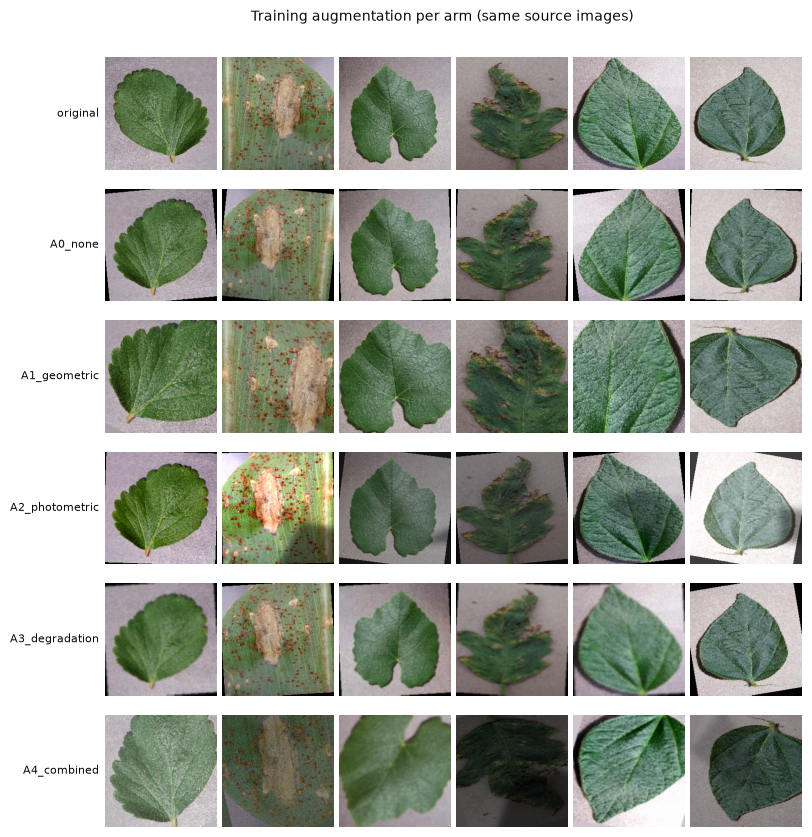

In [19]:
# 2.4 Augmentation preview (fig0): every arm should look different; only A0, A2 and A3 may show thin black corners
preview_augmentations(cfg, data)

## Part 3 · The group baselines

Trained in `COS801_mobilenetv3_baselinemodel` and `EfficientNetB0_Baseline_Training`; only their `.pth` files come
in. Each is scored on the shared `lab_test` and `field_test`, with its outputs matched to the shared class order by
the class names saved in the checkpoint. **The baselines' outputs are not in the shared order:** read in the shared
order, MobileNet's lab accuracy is 0.97, matched by name 0.995. Part 4 inherits that problem; Part 6 corrects it.

The MobileNetV3 baseline is the protocol check for A0 (Part 5): A0 must reproduce it within seed-to-seed variation.

In [20]:
# 3.1 Score the group baselines on the shared lab and field test sets
CLASS_NAMES = None   # only if the class order cannot be worked out from the checkpoint
CLASS_MAP = None     # {"checkpoint class": "our class"}, if the names differ
EFFNET_CKPT = ROOT / PIPELINE["baselines"]["efficientnet_b0"]

if info["kind"] == "classifier":
    evaluate_checkpoint(CKPT, cfg, data, name="B0_mobilenetv3", class_names=CLASS_NAMES, class_map=CLASS_MAP)
if EFFNET_CKPT.exists():
    print("\n" + "=" * 70)
    evaluate_checkpoint(EFFNET_CKPT, cfg, data, name="B1_effnetb0", reference=True)

Checkpoint:   mobilenetv3_baseline_best.pth  (6.0 MB on disk)
Architecture: mobilenet_v3_small   (1.54 M parameters)
Head:         26 outputs
Saved with:   num_classes=26; validation_accuracy=0.9964716805942433; epoch=10; architecture=mobilenet_v3_small; image_size=224
              (use any training settings here, e.g. epochs or lr, in make_config so A0 matches)
Kind:         a trained classifier, e.g. a baseline. Use evaluate_checkpoint().
Class names:  saved, e.g. apple_scab, apple_rust, apple_healthy ...
For A0 to be a like-for-like control, set CONFIG['backbone'] = 'mobilenet_v3_small'.

Class mapping: class names saved in the checkpoint (matched by name; lab_val accuracy 0.996)

B0_mobilenetv3  (mobilenet_v3_small, 5376 lab_test and 2499 field_test images, 26 shared classes)
  lab   macro-F1 0.995   accuracy 0.996   ECE 0.002
  field macro-F1 0.099   accuracy 0.135   ECE 0.694
  gap   0.896  (95% CI 0.884 to 0.908), a 90% relative drop
  Valid only if this model never trained on 

## Part 4 · RQ7.1 compression

*How much accuracy is lost when the network is compressed by pruning, quantisation and knowledge distillation?*

`COS801_Compression_Final.ipynb`, in its order, on the 50% training subset. Both baselines are pruned three ways
(layer-wise, global magnitude, structured channels) at 20, 40 and 60%, with no recovery or a fine-tune; the five
best fine-tunes are recovered again by distillation from the unpruned teacher; and both are quantised to int8 with
four post-training recipes and QAT. Every model is scored on the same test sets, with size and single-thread CPU
latency. Results are kept in CSVs on Drive, so a model already in them is skipped.

In [21]:
# 4.1 Seed, device and paths. Same as COS801_Compression_Final, with the drive root taken from Part 0.
SEED=42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True
    torch.backends.cudnn.benchmark=False
set_seed()
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',device,'PyTorch:',torch.__version__)

PROJECT_DIR=ROOT
IMG_BASE_DIR=PROJECT_DIR/'data'/'raw'
SPLIT_CSV=PROJECT_DIR/PIPELINE['subset_manifest']          # the file with use_50pct
MODEL_DIR=PROJECT_DIR/'models'
RESULTS_DIR=PROJECT_DIR/'results'/'aligned_compression_partial'
OUTPUT_MODEL_DIR=MODEL_DIR/'aligned_compression_partial'
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
OUTPUT_MODEL_DIR.mkdir(parents=True,exist_ok=True)

Device: cpu PyTorch: 2.14.1


In [22]:
# 4.2 One shared class mapping and split definition (training rows: the use_50pct half of lab train)
SHARED_CLASSES={
'apple_scab':('Apple___Apple_scab','Apple Scab Leaf'),'apple_rust':('Apple___Cedar_apple_rust','Apple rust leaf'),
'apple_healthy':('Apple___healthy','Apple leaf'),'blueberry_healthy':('Blueberry___healthy','Blueberry leaf'),
'cherry_healthy':('Cherry_(including_sour)___healthy','Cherry leaf'),
'corn_gray_spot':('Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot','Corn Gray leaf spot'),
'corn_rust':('Corn_(maize)___Common_rust_','Corn rust leaf'),'corn_blight':('Corn_(maize)___Northern_Leaf_Blight','Corn leaf blight'),
'grape_black_rot':('Grape___Black_rot','grape leaf black rot'),
'grape_healthy':('Grape___healthy','grape leaf'),'peach_healthy':('Peach___healthy','Peach leaf'),
'pepper_healthy':('Pepper,_bell___healthy','Bell_pepper leaf'),
'potato_early_blight':('Potato___Early_blight','Potato leaf early blight'),
'potato_late_blight':('Potato___Late_blight','Potato leaf late blight'),
'raspberry_healthy':('Raspberry___healthy','Raspberry leaf'),'soybean_healthy':('Soybean___healthy','Soyabean leaf'),
'squash_mildew':('Squash___Powdery_mildew','Squash Powdery mildew leaf'),
'strawberry_healthy':('Strawberry___healthy','Strawberry leaf'),
'tomato_bacterial_spot':('Tomato___Bacterial_spot','Tomato leaf bacterial spot'),
'tomato_early_blight':('Tomato___Early_blight','Tomato Early blight leaf'),
'tomato_late_blight':('Tomato___Late_blight','Tomato leaf late blight'),'tomato_leaf_mold':('Tomato___Leaf_Mold','Tomato mold leaf'),
'tomato_septoria':('Tomato___Septoria_leaf_spot','Tomato Septoria leaf spot'),
'tomato_yellow_virus':('Tomato___Tomato_Yellow_Leaf_Curl_Virus','Tomato leaf yellow virus'),
'tomato_mosaic_virus':('Tomato___Tomato_mosaic_virus','Tomato leaf mosaic virus'),'tomato_healthy':('Tomato___healthy','Tomato leaf')}
CLASS_NAMES_71=tuple(SHARED_CLASSES)
CLASS_TO_IDX_71={name:i for i,name in enumerate(CLASS_NAMES_71)}
N_CLASSES=len(CLASS_NAMES_71)

df=pd.read_csv(SPLIT_CSV)
PATH_COLUMN='path' if 'path' in df.columns else 'resolved_path'
required={'split','class',PATH_COLUMN}
if not required.issubset(df.columns): raise ValueError(f'Missing columns: {required-set(df.columns)}')
df=df[df['class'].isin(CLASS_NAMES_71)].copy()

# Limit the training set (PlantVillage) to only rows where use_50pct is True
if 'use_50pct' in df.columns:
    # Only apply the filter on the 'train' split which represents our PlantVillage training dataset
    train_mask = df.split.eq('train') & (df['use_50pct'] == True)
    non_train_mask = ~df.split.eq('train')
    df = df[train_mask | non_train_mask].reset_index(drop=True)
else:
    raise ValueError("The column 'use_50pct' was not found in the split CSV metadata.")

train_df=df[df.split.eq('train')].reset_index(drop=True)
val_df=df[df.split.eq('val')].reset_index(drop=True)
test_df=df[df.split.eq('test')].reset_index(drop=True)
field_df=df[df.split.eq('field_test')].reset_index(drop=True)
print({k:len(v) for k,v in [('train',train_df),('val',val_df),('test',test_df),('field_test',field_df)]})

assert list(CLASS_NAMES_71) == list(CONFIG['class_order']), 'RQ7.1 and RQ7.2 must use the same class order'

{'train': 12624, 'val': 5385, 'test': 5376, 'field_test': 2499}


In [23]:
# 4.3 Dataset and loaders. The augmentation code is Part 1's (identical to this notebook's copy). Loading is
# single-process (num_workers=0), as the compression notebook settled on to avoid Colab worker crashes.
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0

# Configuring the dataloader with the simple baseline strategy for this run: 'A0_none'
train_tf = build_train_transform("A0_none", IMG_SIZE)
eval_tf = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

def candidates(raw):
    p=str(raw).replace('\\','/').strip()
    if p.lower().startswith('data/raw/'): p=p[len('data/raw/'):]
    decoded=urllib.parse.unquote(p)
    return list(dict.fromkeys([p,decoded,decoded.replace('+',' ')]))

class PlantDataset(Dataset):
    def __init__(self,frame,transform): self.frame=frame; self.transform=transform
    def __len__(self): return len(self.frame)
    def __getitem__(self,i):
        row=self.frame.iloc[i]; found=None
        for rel in candidates(row[PATH_COLUMN]):
            p=IMG_BASE_DIR/rel
            if p.exists(): found=p; break
        if found is None: raise FileNotFoundError(row[PATH_COLUMN])
        try: image=Image.open(found).convert('RGB')
        except (UnidentifiedImageError,OSError) as e: raise RuntimeError(found) from e
        return self.transform(image),CLASS_TO_IDX_71[row['class']]

def make_loader_71(frame, transform, shuffle=False):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(PlantDataset(frame, transform), batch_size=BATCH_SIZE, shuffle=shuffle, generator=g,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(), persistent_workers=False)

train_loader = make_loader_71(train_df, train_tf, True)
val_loader = make_loader_71(val_df, eval_tf)
test_loader = make_loader_71(test_df, eval_tf)
field_loader = make_loader_71(field_df, eval_tf)
print('Loaders ready (A0 training augmentation, single-process loading).')

Loaders ready (A0 training augmentation, single-process loading).


In [24]:
# 4.4 Shared model-loading code
ARCHITECTURES=('efficientnet_b0','mobilenet_v3_small')
BASELINE_CHECKPOINTS={a: os.path.relpath(p, 'models') for a, p in PIPELINE['baselines'].items()}  # under models/, from 0.4

def build_model_71(arch):
    if arch=='efficientnet_b0':
        m=efficientnet_b0(weights=None); m.classifier[1]=nn.Linear(m.classifier[1].in_features,N_CLASSES); return m
    if arch=='mobilenet_v3_small':
        m=mobilenet_v3_small(weights=None); m.classifier[3]=nn.Linear(m.classifier[3].in_features,N_CLASSES); return m
    raise ValueError(arch)

def load_baseline(arch):
    path=MODEL_DIR/BASELINE_CHECKPOINTS[arch]
    checkpoint=torch.load(path,map_location='cpu')
    m=build_model_71(arch); m.load_state_dict(checkpoint.get('model_state_dict',checkpoint),strict=True)
    return m.eval(),path

### 4.5 The single evaluation contract used by every branch

Every model returns the same metrics, on the same examples and in the same class order. Timing always uses CPU, batch size 1, one thread, fixed warm-up and fixed measured sample count.

In [25]:
# 4.5 The evaluation contract
EVAL_CONTRACT={
 'seed':SEED,'image_size':IMG_SIZE,'normalization':'ImageNet mean/std','class_order':list(CLASS_NAMES_71),
 'test_rows':len(test_df),'field_rows':len(field_df),'latency_device':'cpu','latency_batch_size':1,
 'latency_warmup':20,'latency_samples':100}
(RESULTS_DIR/'evaluation_contract.json').write_text(json.dumps(EVAL_CONTRACT,indent=2))

def predict(model,loader,eval_device):
    model=model.to(eval_device).eval(); ys=[]; ps=[]; loss_sum=0.; n=0
    criterion=nn.CrossEntropyLoss()
    with torch.inference_mode():
        for x,y in tqdm(loader,leave=False):
            x,y=x.to(eval_device),y.to(eval_device); logits=model(x); bs=y.size(0)
            loss_sum += criterion(logits,y).item()*bs; n += bs
            ys.extend(y.cpu().tolist()); ps.extend(logits.argmax(1).cpu().tolist())
    return np.array(ys),np.array(ps),loss_sum/max(n,1)

def evaluate_split(model,loader,eval_device=torch.device('cpu')):
    if len(loader.dataset)==0: return {'loss':np.nan,'accuracy':np.nan,'macro_f1':np.nan,'weighted_f1':np.nan,'samples':0}
    y,p,loss=predict(model,loader,eval_device)
    return {'loss':loss,'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro',zero_division=0),
            'weighted_f1':f1_score(y,p,average='weighted',zero_division=0),'samples':len(y)}

def cpu_latency_ms(model,dataset,warmup=20,samples=100):
    old_threads=torch.get_num_threads(); torch.set_num_threads(1); model=model.cpu().eval()
    usable=min(len(dataset),samples); tensors=[dataset[i][0].unsqueeze(0) for i in range(usable)]
    with torch.inference_mode():
        for x in tensors[:min(warmup,usable)]: model(x)
        times=[]
        for x in tensors:
            start=time.perf_counter(); model(x); times.append((time.perf_counter()-start)*1000)
    torch.set_num_threads(old_threads)
    return float(np.mean(times)),float(np.std(times))

def save_size_mb(model,path):
    torch.save(model.state_dict(),path); return path.stat().st_size/(1024**2)

def evaluate_model(model,arch,method,variant,extra=None):
    test=evaluate_split(model,test_loader); field=evaluate_split(model,field_loader)
    lat_mean,lat_std=cpu_latency_ms(model,test_loader.dataset)
    safe=f'{arch}_{method}_{variant}'.lower().replace(' ','_').replace('/','_')
    path=OUTPUT_MODEL_DIR/f'{safe}.pth'; size=save_size_mb(model.cpu(),path)
    row={'architecture':arch,'method':method,'variant':variant,
         **{f'test_{k}':v for k,v in test.items()},**{f'field_{k}':v for k,v in field.items()},
         'model_size_mb':size,'cpu_latency_mean_ms':lat_mean,'cpu_latency_std_ms':lat_std,'saved_state':str(path)}
    if extra: row.update(extra)
    return row

### 4.6 Baseline parity gate

In [26]:
# 4.6 Baseline parity gate
baseline_rows = []
if 'BASELINES' not in globals() or not BASELINES:
    BASELINES = {}
    # Populate BASELINES dictionary by loading existing architecture baseline models
    for arch in ARCHITECTURES:
        try:
            model, path = load_baseline(arch)
            BASELINES[arch] = model
            print(f"Loaded baseline model for {arch} from: {path}")
        except FileNotFoundError as e:
            print(f"Skipping {arch}: {e}")
else:
    print("Baseline models are already loaded in memory.")

# Check if baseline evaluation results already exist on disk
baseline_csv_path = RESULTS_DIR / 'aligned_baselines.csv'
if baseline_csv_path.exists():
    print("Loading existing baseline evaluation records from aligned_baselines.csv...")
    baseline_df = pd.read_csv(baseline_csv_path)
else:
    print("Evaluating baselines (no saved records found)...")
    for arch, model in BASELINES.items():
        path = MODEL_DIR / BASELINE_CHECKPOINTS[arch]
        row = evaluate_model(copy.deepcopy(model), arch, 'baseline', 'fp32', {'checkpoint': str(path)})
        baseline_rows.append(row)
        print(pd.Series(row))
    baseline_df = pd.DataFrame(baseline_rows)
    baseline_df.to_csv(baseline_csv_path, index=False)

Loaded baseline model for efficientnet_b0 from: /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/models/effnetb0_baseline_best.pth
Loaded baseline model for mobilenet_v3_small from: /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/models/mobilenetv3_baseline_best.pth
Loading existing baseline evaluation records from aligned_baselines.csv...


In [27]:
# 4.7 Pruning and sparsity helpers
def modules_to_prune(model): return [(n,m) for n,m in model.named_modules() if isinstance(m,(nn.Conv2d,nn.Linear))]
def apply_pruning(model,kind,amount):
    model=copy.deepcopy(model)
    if kind=='unstructured_layerwise':
        for _,m in modules_to_prune(model): prune.l1_unstructured(m,'weight',amount)
    elif kind=='global_magnitude':
        prune.global_unstructured([(m,'weight') for _,m in modules_to_prune(model)],pruning_method=prune.L1Unstructured,amount=amount)
    elif kind=='structured_channels':
        for _,m in modules_to_prune(model):
            if isinstance(m,nn.Conv2d) and m.out_channels>1:
                prune.ln_structured(m,'weight',min(amount,(m.out_channels-1)/m.out_channels),n=2,dim=0)
    else: raise ValueError(kind)
    return model

def permanent(model):
    for _,m in modules_to_prune(model):
        if hasattr(m,'weight_orig'): prune.remove(m,'weight')
    return model

def sparsity(model):
    z=n=0
    for _,m in modules_to_prune(model):
        w=m.weight.detach(); z += int((w==0).sum()); n += w.numel()
    return z/max(n,1)

### 4.8 Knowledge distillation code


In [28]:
# 4.8 Knowledge distillation
KD_EPOCHS=1; KD_LR=1e-5; KD_ALPHA=0.5; KD_TEMPERATURE=3.0

def train_pruned_student(student,teacher=None,epochs=KD_EPOCHS,alpha=KD_ALPHA,T=KD_TEMPERATURE):
    student=student.to(device); teacher=teacher.to(device).eval() if teacher is not None else None
    if teacher is not None:
        for p in teacher.parameters(): p.requires_grad=False
    optimizer=optim.AdamW(student.parameters(),lr=KD_LR,weight_decay=1e-4)
    best=copy.deepcopy(student.state_dict()); best_score=-1; history=[]
    for epoch in range(epochs):
        student.train(); loss_sum=correct=n=0
        for x,y in tqdm(train_loader,desc=f'Train {epoch+1}/{epochs}',leave=False):
            x,y=x.to(device),y.to(device); optimizer.zero_grad(set_to_none=True)
            # Use Automatic Mixed Precision for faster training if CUDA is available
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                s=student(x)
                hard=F.cross_entropy(s,y)
                if teacher is None: loss=hard; soft=torch.tensor(0.,device=device)
                else:
                    with torch.no_grad(): t=teacher(x)
                    soft=F.kl_div(F.log_softmax(s/T,dim=1),F.softmax(t/T,dim=1),reduction='batchmean')*(T*T)
                    loss=alpha*hard+(1-alpha)*soft
            loss.backward(); optimizer.step(); bs=y.size(0)
            loss_sum += loss.item()*bs; correct += s.argmax(1).eq(y).sum().item(); n += bs
        val=evaluate_split(student,val_loader,device)
        history.append({'epoch':epoch+1,'train_loss':loss_sum/max(n,1),'train_accuracy':correct/max(n,1),**{f'val_{k}':v for k,v in val.items()}})
        if val['macro_f1']>best_score: best_score=val['macro_f1']; best=copy.deepcopy(student.state_dict())
    student.load_state_dict(best)
    return student.cpu().eval(),pd.DataFrame(history)

In [29]:
# 4.9 Run the pruning, fine-tune and KD experiments (resumes from aligned_pruning_results_partial.csv)
# ==================================================================
# --- Updated Pruning & Multi-Scenario KD Experiments Code ---
if not STAGES["rq71_compression"]:
    print("Skipped: STAGES[\"rq71_compression\"] is False (pruning results are read from the CSV).")
else:
    PRUNING_METHODS = ('unstructured_layerwise', 'global_magnitude', 'structured_channels')
    PRUNING_AMOUNTS = (0.20, 0.40, 0.60)
    pruning_rows = []

    # Ensure BASELINES is defined and loaded
    if 'BASELINES' not in globals() or not BASELINES:
        BASELINES = {}
        for arch in ARCHITECTURES:
            try:
                model, path = load_baseline(arch)
                BASELINES[arch] = model
                print(f"Loaded baseline model for {arch} from: {path}")
            except Exception as e:
                print(f"Error loading baseline for {arch}: {e}")

    # Try to load existing progress if it was partially completed and saved
    checkpoint_results_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
    if checkpoint_results_path.exists():
        try:
            pruning_rows = pd.read_csv(checkpoint_results_path).to_dict('records')
            print(f"Loaded {len(pruning_rows)} previously completed experiment records.")
        except Exception:
            pruning_rows = []

    def record_exists(arch, method, variant):
        return any(r['architecture'] == arch and r['method'] == method and r['variant'] == variant for r in pruning_rows)

    for arch, baseline in BASELINES.items():
        print(f"\n=== Starting/Resuming Experiments for Architecture: {arch} ===")

        # 1. Standard Pruning and Fine-tuning Loops
        for kind in PRUNING_METHODS:
            print(f"\n  >> Pruning Method: {kind}")
            for amount in PRUNING_AMOUNTS:
                print(f"     -> Sparsity level: {amount * 100:.0f}%")

                variant_no_rec = f'{kind}_{amount:.2f}_no_recovery_partial'
                variant_fine_tune = f'{kind}_{amount:.2f}_fine_tune_partial'

                # Apply pruning
                p = apply_pruning(baseline, kind, amount)
                p_permanent = permanent(p)

                # Evaluate no-recovery model
                if record_exists(arch, 'pruning', variant_no_rec):
                    print(f"        [1/2] Skipping evaluation for {variant_no_rec} (Record already exists).")
                else:
                    print(f"        [1/2] Evaluating {arch} ({kind} @ {amount:.2f}) with NO recovery...")
                    no_rec_row = evaluate_model(
                        copy.deepcopy(p_permanent),
                        arch,
                        'pruning',
                        variant_no_rec,
                        {'sparsity': sparsity(p_permanent)}
                    )
                    pruning_rows.append(no_rec_row)
                    pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                    print(f"              No-recovery Accuracy: {no_rec_row['test_accuracy']:.4f}")

                # Fine-tune student / recovery path
                history_file = RESULTS_DIR / f'{arch}_{kind}_{amount:.2f}_finetune_history_partial.csv'
                model_name = f'{arch}_pruning_{variant_fine_tune}.pth'.lower().replace(' ', '_').replace('/', '_')
                model_file = OUTPUT_MODEL_DIR / model_name

                if record_exists(arch, 'pruning', variant_fine_tune):
                    print(f"        [2/2] Skipping training/evaluation for {variant_fine_tune} (Record already exists).")
                elif model_file.exists():
                    print(f"        [2/2] Found existing trained model file at {model_file}. Loading and evaluating to rebuild metrics...")
                    tuned = build_model_71(arch)
                    tuned.load_state_dict(torch.load(model_file, map_location='cpu'))
                    tuned_row = evaluate_model(
                        copy.deepcopy(tuned),
                        arch,
                        'pruning',
                        variant_fine_tune,
                        {'sparsity': sparsity(tuned)}
                    )
                    pruning_rows.append(tuned_row)
                    pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                    print(f"              Loaded Model Accuracy: {tuned_row['test_accuracy']:.4f}")
                else:
                    print(f"        [2/2] Fine-tuning student model (3 epochs)... ")
                    tuned, h = train_pruned_student(copy.deepcopy(p_permanent), teacher=None)
                    h.to_csv(history_file, index=False)

                    # Evaluate newly fine-tuned model
                    tuned_row = evaluate_model(
                        copy.deepcopy(tuned),
                        arch,
                        'pruning',
                        variant_fine_tune,
                        {'sparsity': sparsity(tuned)}
                    )
                    pruning_rows = [r for r in pruning_rows if not (r['architecture'] == arch and r['method'] == 'pruning' and r['variant'] == variant_fine_tune)]
                    pruning_rows.append(tuned_row)
                    pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                    print(f"              Fine-tuned Accuracy : {tuned_row['test_accuracy']:.4f}")

        # 2. Dynamically Select and Apply KD to Top 5 Performing Pruned Scenarios
        print(f"\n  >> Selecting top performing pruned scenarios for KD target analysis...")
        arch_df = pd.DataFrame(pruning_rows)
        arch_df = arch_df[(arch_df['architecture'] == arch) & (arch_df['method'] == 'pruning') & (arch_df['variant'].str.contains('fine_tune'))]

        # Sort by test accuracy descending to find the top 5 scenarios
        top_5_scenarios = arch_df.sort_values(by='test_accuracy', ascending=False).head(5)

        for _, target in top_5_scenarios.iterrows():
            # Deconstruct method details from the variant name
            parts = target['variant'].split('_')
            kind = f"{parts[0]}_{parts[1]}"
            amount = float(parts[2])

            kd_variant = f"{kind}_{amount:.2f}_kd_partial"
            kd_history_file = RESULTS_DIR / f'{arch}_{kind}_{amount:.2f}_kd_history_partial.csv'
            kd_name = f'{arch}_knowledge_distillation_{kd_variant}.pth'.lower().replace(' ', '_').replace('/', '_')
            kd_model_file = OUTPUT_MODEL_DIR / kd_name

            print(f"\n     Checking KD Recovery for Scenario: {kind} @ {amount * 100:.0f}% Sparsity...")
            if record_exists(arch, 'knowledge_distillation', kd_variant):
                print(f"        Skipping KD recovery (Record already exists).")
            elif kd_model_file.exists():
                print(f"        Found existing trained KD model file at {kd_model_file}. Loading and evaluating...")
                kd = build_model_71(arch)
                kd.load_state_dict(torch.load(kd_model_file, map_location='cpu'))
                kd_row = evaluate_model(
                    copy.deepcopy(kd),
                    arch,
                    'knowledge_distillation',
                    kd_variant,
                    {'sparsity': sparsity(kd), 'kd_alpha': KD_ALPHA, 'temperature': KD_TEMPERATURE}
                )
                pruning_rows.append(kd_row)
                pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                print(f"        Loaded KD Model Accuracy: {kd_row['test_accuracy']:.4f}")
            else:
                p = apply_pruning(baseline, kind, amount)
                p_permanent = permanent(p)

                print(f"        Training student via KD with teacher guidance...")
                kd, h = train_pruned_student(copy.deepcopy(p_permanent), teacher=copy.deepcopy(baseline))
                h.to_csv(kd_history_file, index=False)

                kd_row = evaluate_model(
                    copy.deepcopy(kd),
                    arch,
                    'knowledge_distillation',
                    kd_variant,
                    {'sparsity': sparsity(kd), 'kd_alpha': KD_ALPHA, 'temperature': KD_TEMPERATURE}
                )
                pruning_rows = [r for r in pruning_rows if not (r['architecture'] == arch and r['method'] == 'knowledge_distillation' and r['variant'] == kd_variant)]
                pruning_rows.append(kd_row)
                pd.DataFrame(pruning_rows).to_csv(checkpoint_results_path, index=False)
                print(f"        KD Recovery Accuracy: {kd_row['test_accuracy']:.4f}")

    # 3. Save Final Results
    print("\n=== Saving all aligned pruning results... ===")
    pruning_df = pd.DataFrame(pruning_rows)
    pruning_df.to_csv(RESULTS_DIR / 'aligned_pruning_results_partial.csv', index=False)
    if checkpoint_results_path.exists() and (RESULTS_DIR / 'aligned_pruning_results_partial.csv') != checkpoint_results_path:
        checkpoint_results_path.unlink() # Clean up checkpoint file
    print("Done! Results successfully saved.")

Loaded 48 previously completed experiment records.

=== Starting/Resuming Experiments for Architecture: efficientnet_b0 ===

  >> Pruning Method: unstructured_layerwise
     -> Sparsity level: 20%
        [1/2] Skipping evaluation for unstructured_layerwise_0.20_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.20_fine_tune_partial (Record already exists).
     -> Sparsity level: 40%
        [1/2] Skipping evaluation for unstructured_layerwise_0.40_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.40_fine_tune_partial (Record already exists).
     -> Sparsity level: 60%
        [1/2] Skipping evaluation for unstructured_layerwise_0.60_no_recovery_partial (Record already exists).
        [2/2] Skipping training/evaluation for unstructured_layerwise_0.60_fine_tune_partial (Record already exists).

  >> Pruning Method: global_magnitude
     -> Sparsity leve

### 4.10 Quantisation configuration and fixed calibration loader

Calibration uses the non-augmented transform and a fixed, seeded subset of training rows. This prevents calibration strategy comparisons from using different images.

In [30]:
# 4.10 Quantisation configuration and fixed calibration loader
CALIBRATION_SAMPLES=min(1024,len(train_df)); rng=np.random.default_rng(SEED)
cal_idx=np.sort(rng.choice(len(train_df),size=CALIBRATION_SAMPLES,replace=False))
calibration_df=train_df.iloc[cal_idx].reset_index(drop=True)
calibration_loader=make_loader_71(calibration_df,eval_tf,False)
SUPPORTED=list(torch.backends.quantized.supported_engines)
QUANT_ENGINE='x86' if 'x86' in SUPPORTED else ('fbgemm' if 'fbgemm' in SUPPORTED else 'qnnpack')
torch.backends.quantized.engine=QUANT_ENGINE
example_inputs=(next(iter(calibration_loader))[0][:1].cpu(),)

def ptq_qconfig(observer='histogram',per_channel=True):
    act=(HistogramObserver if observer=='histogram' else MinMaxObserver).with_args(dtype=torch.quint8,qscheme=torch.per_tensor_affine,reduce_range=False)
    wt=(PerChannelMinMaxObserver.with_args(dtype=torch.qint8,qscheme=torch.per_channel_symmetric,ch_axis=0) if per_channel
        else MinMaxObserver.with_args(dtype=torch.qint8,qscheme=torch.per_tensor_symmetric))
    return QConfig(activation=act,weight=wt)

def quantize_ptq(model,observer='histogram',per_channel=True,mixed=False):
    checkpoint_file = RESULTS_DIR / f'interim_calib_progress_{observer}_{per_channel}_{mixed}.json'
    print(f"  [PTQ] Step 1/4: Initialising prepare_fx with engine: {QUANT_ENGINE} (observer={observer}, per_channel={per_channel}, mixed={mixed})")
    mapping=QConfigMapping().set_global(ptq_qconfig(observer,per_channel))
    if mixed: mapping=mapping.set_module_name('classifier',None)
    prepared=prepare_fx(copy.deepcopy(model).cpu().eval(),mapping,example_inputs)

    print("  [PTQ] Step 2/4: Running calibration batches on CPU...")
    with torch.inference_mode():
        total_batches = len(calibration_loader)
        for idx, (x, _) in enumerate(tqdm(calibration_loader, desc="PTQ Calibrating", leave=False)):
            prepared(x.cpu())
            # Save progress check every 10 steps to file
            if (idx + 1) % 10 == 0 or (idx + 1) == total_batches:
                print(f"    [Calibration Progress] Processed batch {idx + 1}/{total_batches}")
                progress_data = {"last_processed_batch": idx + 1, "total_batches": total_batches, "status": "calibrating"}
                try:
                    checkpoint_file.write_text(json.dumps(progress_data))
                except Exception:
                    pass

    print("  [PTQ] Step 3/4: Converting prepared model to quantised representation...")
    quantized_model = convert_fx(prepared).eval()

    # Update checkpoint file to reflect success
    try:
        checkpoint_file.write_text(json.dumps({"status": "completed"}))
    except Exception:
        pass

    print("  [PTQ] Step 4/4: Model quantisation completed successfully.")
    return quantized_model

In [31]:
# 4.11 Quantisation-aware training
QAT_EPOCHS=1; QAT_LR=1e-5

def qat_qconfig():
    return QConfig(
      activation=FakeQuantize.with_args(observer=MovingAverageMinMaxObserver,dtype=torch.quint8,qscheme=torch.per_tensor_affine,reduce_range=False),
      weight=FakeQuantize.with_args(observer=MovingAveragePerChannelMinMaxObserver,dtype=torch.qint8,qscheme=torch.per_channel_symmetric,ch_axis=0))

def quantize_qat(model):
    checkpoint_file = RESULTS_DIR / 'interim_qat_progress.json'
    print("  [QAT] Step 1/4: Initialising QAT configuration and preparing FX graph...")
    prepared=prepare_qat_fx(copy.deepcopy(model).cpu().train(),QConfigMapping().set_global(qat_qconfig()),example_inputs).to(device)

    print("  [QAT] Step 2/4: Optimising trainable parameters over training epochs...")
    trainable_params = [p for p in prepared.parameters() if p.requires_grad]
    opt=optim.AdamW(trainable_params,lr=QAT_LR,weight_decay=1e-4); best=copy.deepcopy(prepared.state_dict()); score=-1

    for epoch in range(QAT_EPOCHS):
        prepared.train()
        total_batches = len(train_loader)
        for idx, (x, y) in enumerate(tqdm(train_loader, desc=f'QAT {epoch+1}/{QAT_EPOCHS}', leave=False)):
            x,y=x.to(device),y.to(device); opt.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
                loss=F.cross_entropy(prepared(x),y)
            loss.backward(); opt.step()

            # Save intermediate training batch progress to local JSON
            if (idx + 1) % 50 == 0 or (idx + 1) == total_batches:
                print(f"    [QAT Progress] Epoch {epoch+1}/{QAT_EPOCHS} - Batch {idx+1}/{total_batches} - Loss: {loss.item():.4f}")
                progress_data = {"epoch": epoch + 1, "batch": idx + 1, "loss": loss.item(), "status": "training"}
                try:
                    checkpoint_file.write_text(json.dumps(progress_data))
                except Exception:
                    pass

        print("  [QAT] Step 3/4: Disabling observers and evaluating on validation split...")
        val=evaluate_split(prepared,val_loader,device)
        if val['macro_f1']>score:
            score=val['macro_f1']
            best=copy.deepcopy(prepared.state_dict())
        if epoch==QAT_EPOCHS-1:
            prepared.apply(disable_observer)

    prepared.load_state_dict(best)
    print("  [QAT] Step 4/4: Finalising conversion to fully-quantised representation...")
    quantized_model = convert_fx(prepared.cpu().eval()).eval()

    try:
        checkpoint_file.write_text(json.dumps({"status": "completed"}))
    except Exception:
        pass

    print("  [QAT] QAT execution completed successfully.")
    return quantized_model

In [32]:
# 4.12 Run the quantisation experiments (resumes from aligned_quantisation_results_partial.csv)
if not STAGES["rq71_compression"]:
    print("Skipped: STAGES[\"rq71_compression\"] is False (quantisation results are read from the CSV).")
else:
    import gc
    import os
    import pandas as pd
    from datetime import datetime

    quant_results_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

    # --- FORCE RESET CONTROL ---
    # Change this to True to archive existing CSV results and force a complete rerun
    FORCE_RERUN = False

    if FORCE_RERUN and quant_results_path.exists():
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        backup_path = quant_results_path.with_name(f"aligned_quantisation_results_partial_backup_{timestamp}.csv")
        quant_results_path.rename(backup_path)
        print(f"[Reset] Archived old results to: {backup_path.name}")

    # 1. Load existing progress if available
    if quant_results_path.exists():
        try:
            quant_rows = pd.read_csv(quant_results_path).to_dict('records')
            print(f"Loaded {len(quant_rows)} previously completed quantisation records.")
        except Exception:
            quant_rows = []
    else:
        quant_rows = []

    def quant_record_exists(arch, variant):
        return any(r['architecture'] == arch and r['variant'] == variant for r in quant_rows)

    for arch, baseline in BASELINES.items():
        print(f"\n=== Starting/Resuming Quantisation for {arch} ===")

        # 2. Post-Training Quantisation (PTQ) Specs
        specs = [
            ('ptq_minmax_per_channel_partial', 'minmax', True, False),
            ('ptq_histogram_per_channel_partial', 'histogram', True, False),
            ('ptq_histogram_per_tensor_partial', 'histogram', False, False),
            ('mixed_int8_fp32_partial', 'histogram', True, True)
        ]
        for name, obs, pc, mixed in specs:
            if quant_record_exists(arch, name):
                print(f"  [PTQ] Skipping {name} (record already exists in CSV).")
                continue

            q = quantize_ptq(baseline, obs, pc, mixed)
            row = evaluate_model(q, arch, 'quantisation', name, {'quant_engine': QUANT_ENGINE, 'calibration_samples': CALIBRATION_SAMPLES})
            quant_rows.append(row)

            # Save interim progress to disk immediately
            pd.DataFrame(quant_rows).to_csv(quant_results_path, index=False)

            # Free memory immediately
            del q
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        # 3. Quantisation-Aware Training (QAT)
        qat_name = 'qat_int8_per_channel_partial'
        if quant_record_exists(arch, qat_name):
            print(f"  [QAT] Skipping {qat_name} (record already exists in CSV).")
        else:
            q = quantize_qat(baseline)
            row = evaluate_model(q, arch, 'quantisation', qat_name, {'quant_engine': QUANT_ENGINE})
            quant_rows.append(row)

            # Save interim progress to disk immediately
            pd.DataFrame(quant_rows).to_csv(quant_results_path, index=False)

            # Free memory immediately
            del q
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    # Final summary saving
    quant_df = pd.DataFrame(quant_rows)
    quant_df.to_csv(quant_results_path, index=False)

    print(f"\n[Success] Quantisation experiments completed/loaded. Total saved records: {len(quant_df)}.")
    display(quant_df[['architecture', 'variant', 'test_accuracy', 'field_accuracy', 'model_size_mb']])

Loaded 10 previously completed quantisation records.

=== Starting/Resuming Quantisation for efficientnet_b0 ===
  [PTQ] Skipping ptq_minmax_per_channel_partial (record already exists in CSV).
  [PTQ] Skipping ptq_histogram_per_channel_partial (record already exists in CSV).
  [PTQ] Skipping ptq_histogram_per_tensor_partial (record already exists in CSV).
  [PTQ] Skipping mixed_int8_fp32_partial (record already exists in CSV).
  [QAT] Skipping qat_int8_per_channel_partial (record already exists in CSV).

=== Starting/Resuming Quantisation for mobilenet_v3_small ===
  [PTQ] Skipping ptq_minmax_per_channel_partial (record already exists in CSV).
  [PTQ] Skipping ptq_histogram_per_channel_partial (record already exists in CSV).
  [PTQ] Skipping ptq_histogram_per_tensor_partial (record already exists in CSV).
  [PTQ] Skipping mixed_int8_fp32_partial (record already exists in CSV).
  [QAT] Skipping qat_int8_per_channel_partial (record already exists in CSV).

[Success] Quantisation experime

,architecture,variant,test_accuracy,field_accuracy,model_size_mb
0,efficientnet_b0,ptq_minmax_per_channel_partial,0.407552,0.070428,4.616973
1,efficientnet_b0,ptq_histogram_per_channel_partial,0.941220,0.108043,4.626019
2,efficientnet_b0,ptq_histogram_per_tensor_partial,0.016183,0.026010,4.104800
3,efficientnet_b0,mixed_int8_fp32_partial,0.941406,0.109644,4.705136
4,efficientnet_b0,qat_int8_per_channel_partial,0.874442,0.102041,4.615642
5,mobilenet_v3_small,ptq_minmax_per_channel_partial,0.215960,0.071228,1.790431
6,mobilenet_v3_small,ptq_histogram_per_channel_partial,0.249814,0.071629,1.793284
7,mobilenet_v3_small,ptq_histogram_per_tensor_partial,0.059338,0.042017,1.607795
8,mobilenet_v3_small,mixed_int8_fp32_partial,0.256510,0.072029,3.528167
9,mobilenet_v3_small,qat_int8_per_channel_partial,0.041667,0.046018,1.785884


### 4.13 Combine the baseline, pruning and quantisation results

`aligned_compression_results_partial.csv` is the file Part 6 reads. Its "top performing by field accuracy" table selects on the test set: descriptive only.

In [33]:
# 4.13 Combine the results into aligned_compression_results_partial.csv
import pandas as pd
from pathlib import Path

# Define the paths to our result files
baseline_path = RESULTS_DIR / 'aligned_baselines.csv'
pruning_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
quant_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

# Load and concatenate individual result files
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No results files found yet!")
else:
    df_res = pd.concat(dfs, ignore_index=True, sort=False)

    # Save combined results for future use
    df_res.to_csv(RESULTS_DIR / 'aligned_compression_results_partial.csv', index=False)
    print("Successfully consolidated and saved combined results.\n")

    print("=== Top Performing Models by Field Accuracy ===\n")
    best_rows = []
    for arch in df_res['architecture'].unique():
        arch_df = df_res[df_res['architecture'] == arch]
        # Find the row with the maximum field_accuracy
        best_row = arch_df.loc[arch_df['field_accuracy'].idxmax()]
        best_rows.append(best_row)

    summary_df = pd.DataFrame(best_rows)[[
        'architecture', 'method', 'variant',
        'field_accuracy', 'test_accuracy',
        'model_size_mb', 'cpu_latency_mean_ms'
    ]]

    display(summary_df)

Successfully consolidated and saved combined results.

=== Top Performing Models by Field Accuracy ===



,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms
17,efficientnet_b0,pruning,structured_channels_0.40_fine_tune_partial,0.167667,0.977679,15.720040,62.967355
39,mobilenet_v3_small,knowledge_distillation,global_magnitude_0.40_partial,0.145258,0.993118,6.046226,20.616005


### 4.14 Figures and the system-fitness index

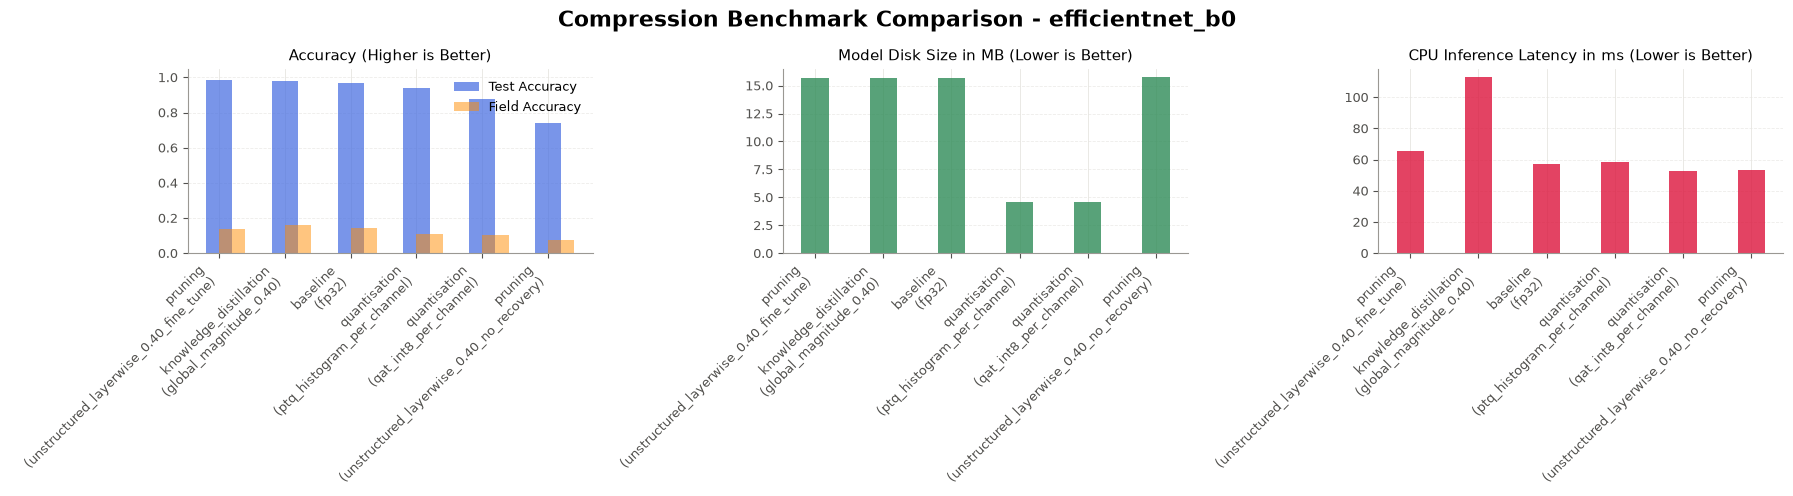

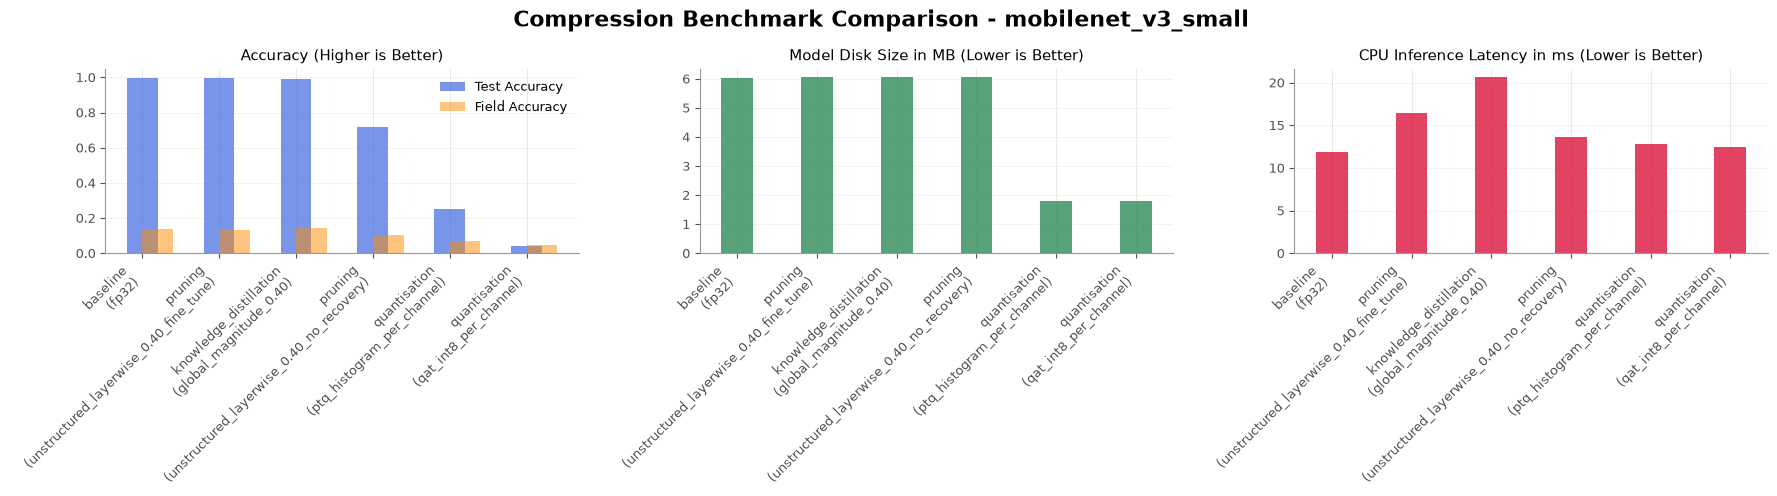

In [34]:
# 4.14a Accuracy, size and latency of representative variants
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the paths to our result files
baseline_path = RESULTS_DIR / 'aligned_baselines.csv'
pruning_path = RESULTS_DIR / 'aligned_pruning_results_partial.csv'
quant_path = RESULTS_DIR / 'aligned_quantisation_results_partial.csv'

# Load and concatenate whatever results are currently present
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No CSV files found yet to visualize!")
else:
    df_all = pd.concat(dfs, ignore_index=True, sort=False)

    # Pick a few key representative methods to compare per architecture
    # We'll filter for key variants to avoid over-crowding the plot
    df_subset = df_all[
        df_all['variant'].isin([
            'fp32',
            'unstructured_layerwise_0.40_no_recovery_partial',
            'unstructured_layerwise_0.40_fine_tune_partial',
            'global_magnitude_0.40_partial', # KD branch
            'ptq_histogram_per_channel_partial',
            'qat_int8_per_channel_partial'
        ])
    ].copy()

    # Create a nice label combining method + variant
    df_subset['label'] = df_subset['method'] + '\n(' + df_subset['variant'].str.replace('_partial', '') + ')'

    # Plot separately for each architecture
    for arch in df_subset['architecture'].unique():
        arch_df = df_subset[df_subset['architecture'] == arch].sort_values(by='test_accuracy', ascending=False)

        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle(f"Compression Benchmark Comparison - {arch}", fontsize=16, fontweight='bold')

        x_indices = range(len(arch_df))

        # 1. Test Accuracy & Field Accuracy
        axes[0].bar(x_indices, arch_df['test_accuracy'], alpha=0.7, label='Test Accuracy', color='royalblue', width=0.4, align='center')
        axes[0].bar(x_indices, arch_df['field_accuracy'], alpha=0.5, label='Field Accuracy', color='darkorange', width=0.4, align='edge')
        axes[0].set_title("Accuracy (Higher is Better)")
        axes[0].set_xticks(x_indices)
        axes[0].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[0].set_ylim(0, 1.05)
        axes[0].grid(axis='y', linestyle='--', alpha=0.7)
        axes[0].legend()

        # 2. Model Size (MB)
        axes[1].bar(x_indices, arch_df['model_size_mb'], color='seagreen', alpha=0.8, width=0.4)
        axes[1].set_title("Model Disk Size in MB (Lower is Better)")
        axes[1].set_xticks(x_indices)
        axes[1].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[1].grid(axis='y', linestyle='--', alpha=0.7)

        # 3. CPU Latency (ms)
        axes[2].bar(x_indices, arch_df['cpu_latency_mean_ms'], color='crimson', alpha=0.8, width=0.4)
        axes[2].set_title("CPU Inference Latency in ms (Lower is Better)")
        axes[2].set_xticks(x_indices)
        axes[2].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[2].grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.show()

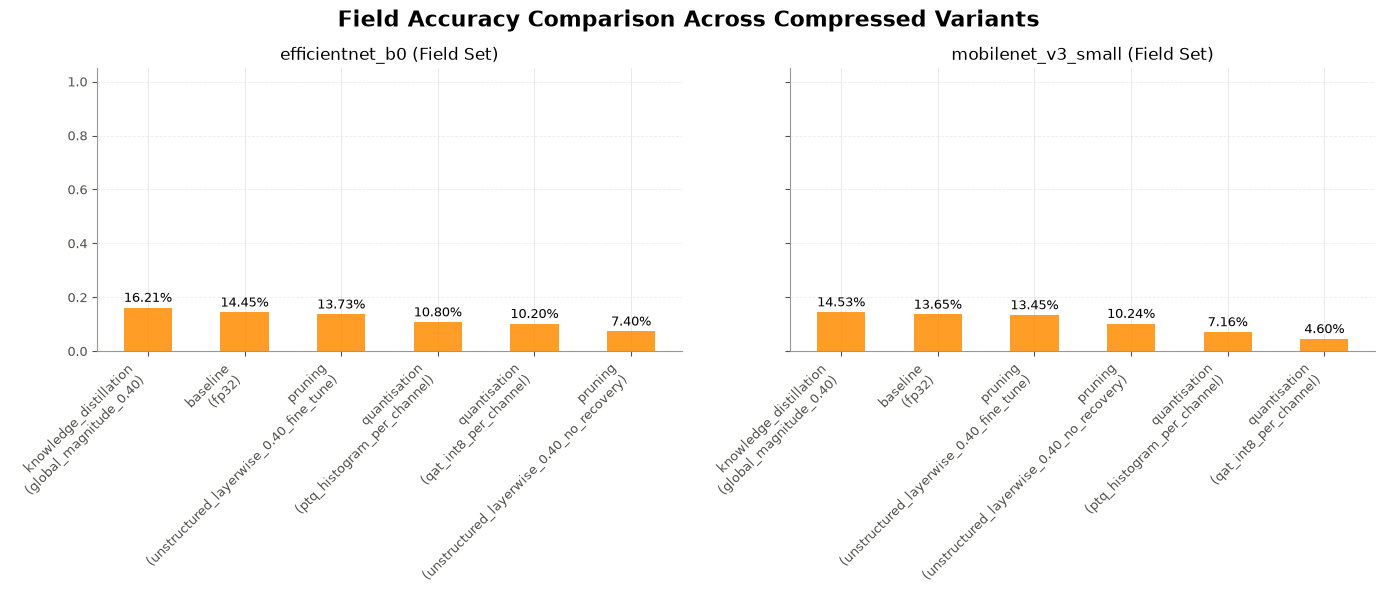

In [35]:
# 4.14b Field accuracy of representative variants
import pandas as pd
import matplotlib.pyplot as plt

# Re-load data from our paths
dfs = []
if baseline_path.exists():
    dfs.append(pd.read_csv(baseline_path))
if pruning_path.exists():
    dfs.append(pd.read_csv(pruning_path))
if quant_path.exists():
    dfs.append(pd.read_csv(quant_path))

if not dfs:
    print("No results found yet!")
else:
    df_all = pd.concat(dfs, ignore_index=True, sort=False)

    # Filter for the key strategies we want to evaluate
    df_subset = df_all[
        df_all['variant'].isin([
            'fp32',
            'unstructured_layerwise_0.40_no_recovery_partial',
            'unstructured_layerwise_0.40_fine_tune_partial',
            'global_magnitude_0.40_partial',
            'ptq_histogram_per_channel_partial',
            'qat_int8_per_channel_partial'
        ])
    ].copy()

    df_subset['label'] = df_subset['method'] + '\n(' + df_subset['variant'].str.replace('_partial', '') + ')'

    # Create an independent visualization dedicated to Field Accuracy
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    fig.suptitle("Field Accuracy Comparison Across Compressed Variants", fontsize=16, fontweight='bold')

    architectures = df_subset['architecture'].unique()
    for i, arch in enumerate(architectures):
        arch_df = df_subset[df_subset['architecture'] == arch].sort_values(by='field_accuracy', ascending=False)
        x_indices = range(len(arch_df))

        bars = axes[i].bar(x_indices, arch_df['field_accuracy'], color='darkorange', alpha=0.85, width=0.5)
        axes[i].set_title(f"{arch} (Field Set)", fontsize=12)
        axes[i].set_xticks(x_indices)
        axes[i].set_xticklabels(arch_df['label'], rotation=45, ha='right')
        axes[i].set_ylim(0, 1.05)
        axes[i].grid(axis='y', linestyle='--', alpha=0.7)

        # Add value labels on top of the bars
        for bar in bars:
            yval = bar.get_height()
            if not pd.isna(yval):
                axes[i].text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f"{yval:.2%}", ha='center', va='bottom', fontsize=9)

    plt.tight_layout()
    plt.show()

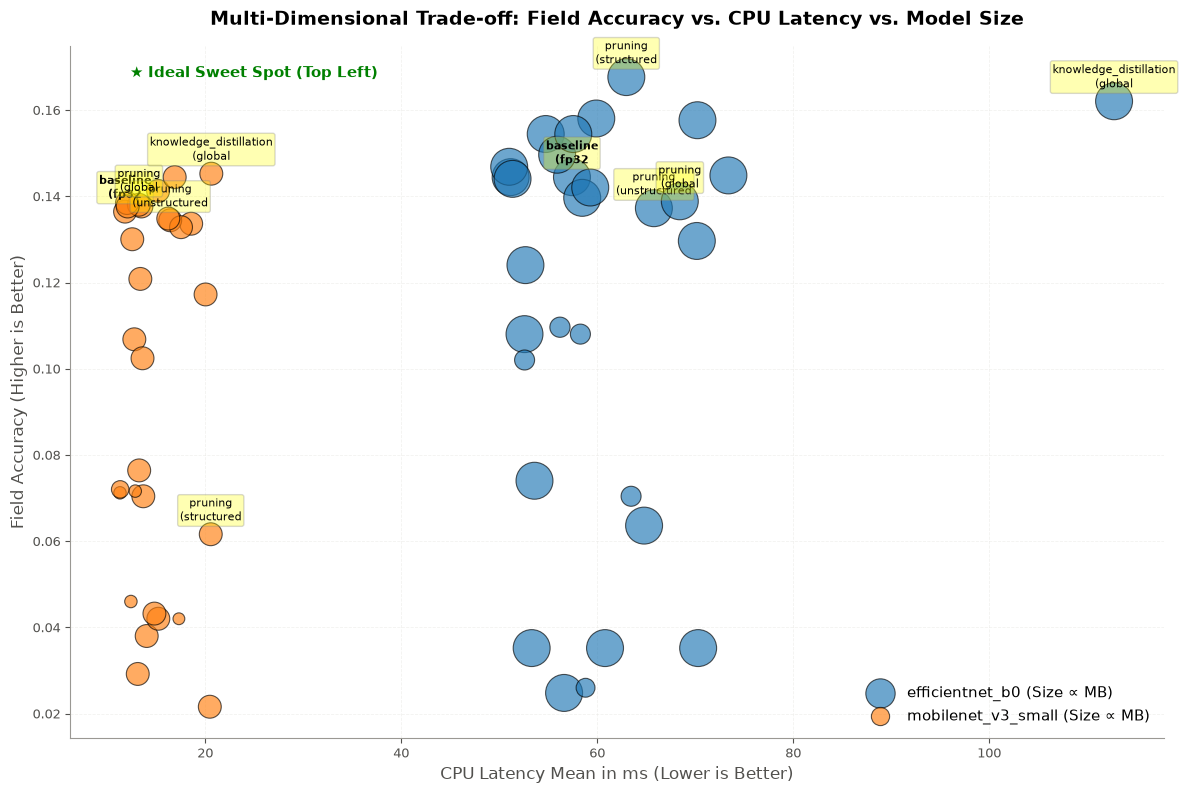

In [36]:
# 4.14c Trade-off: field accuracy vs CPU latency vs size
import matplotlib.pyplot as plt
import pandas as pd

# Re-load consolidated results
results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_plot = pd.read_csv(results_path)

    # Drop any rows with missing latency or accuracy values to clean up the plot
    df_plot = df_plot.dropna(subset=['field_accuracy', 'cpu_latency_mean_ms', 'model_size_mb'])

    plt.figure(figsize=(12, 8))

    # Distinct markers/colors per architecture
    colors = {'efficientnet_b0': '#1f77b4', 'mobilenet_v3_small': '#ff7f0e'}

    for arch in df_plot['architecture'].unique():
        sub_df = df_plot[df_plot['architecture'] == arch]

        # Size of bubble is proportional to model size (scaled up for visualization visibility)
        sizes = sub_df['model_size_mb'] * 45

        sc = plt.scatter(
            sub_df['cpu_latency_mean_ms'],
            sub_df['field_accuracy'],
            s=sizes,
            c=colors.get(arch, 'gray'),
            label=f"{arch} (Size ∝ MB)",
            alpha=0.65,
            edgecolors='black',
            linewidths=0.8
        )

        # Label key top-performing or interesting variants to avoid crowding
        for _, row in sub_df.iterrows():
            is_baseline = row['method'] == 'baseline'
            is_best_prune = 'fine_tune' in str(row['variant']) and '0.40' in str(row['variant'])
            is_kd = 'global_magnitude_0.40_partial' in str(row['variant'])

            if is_baseline or is_best_prune or is_kd:
                label_text = f"{row['method']}\n({row['variant'].split('_')[0] if not is_baseline else 'fp32'}"
                plt.annotate(
                    label_text,
                    (row['cpu_latency_mean_ms'], row['field_accuracy']),
                    textcoords="offset points",
                    xytext=(0, 10),
                    ha='center',
                    fontsize=8,
                    fontweight='bold' if is_baseline else 'normal',
                    bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3, ec="gray")
                )

    plt.title("Multi-Dimensional Trade-off: Field Accuracy vs. CPU Latency vs. Model Size", fontsize=14, fontweight='bold', pad=15)
    plt.ylabel("Field Accuracy (Higher is Better)", fontsize=12)
    plt.xlabel("CPU Latency Mean in ms (Lower is Better)", fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(loc='lower right', fontsize=11)

    # Add a visual indicator of the optimal zone
    plt.text(df_plot['cpu_latency_mean_ms'].min(), df_plot['field_accuracy'].max(), "  ★ Ideal Sweet Spot (Top Left)", color='green', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found! Please run the preceding consolidation cell first.")

/var/folders/xk/xtdph1j16131w66hv1jwx9b00000gn/T/ipykernel_8471/2969645493.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)


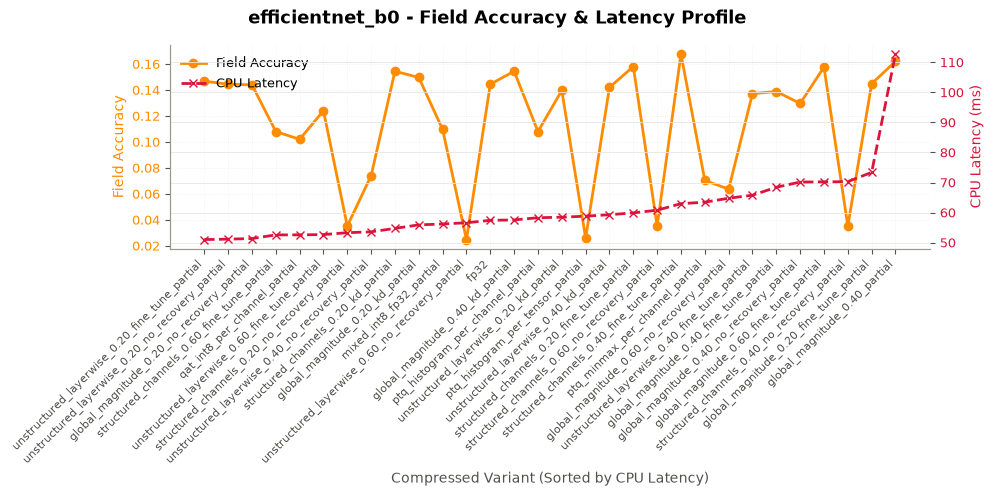

/var/folders/xk/xtdph1j16131w66hv1jwx9b00000gn/T/ipykernel_8471/2969645493.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)


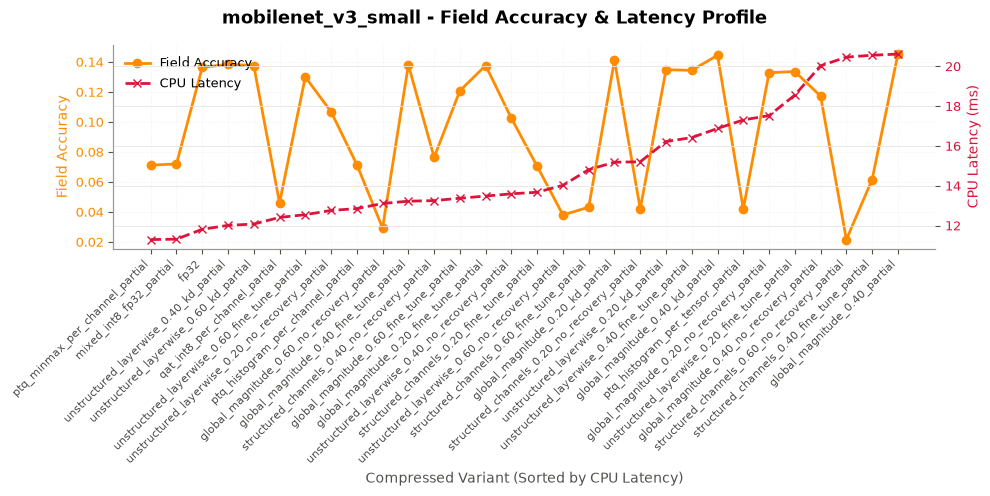

In [37]:
# 4.14d Field accuracy and latency per variant
import matplotlib.pyplot as plt
import pandas as pd

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_clean = df_results.dropna(subset=['field_accuracy', 'cpu_latency_mean_ms']).copy()

    # Plot separately for each architecture to keep trade-offs clear
    for arch in df_clean['architecture'].unique():
        arch_df = df_clean[df_clean['architecture'] == arch].copy()

        # Sort values by latency to produce logical progression line charts
        arch_df = arch_df.sort_values(by='cpu_latency_mean_ms')

        fig, ax1 = plt.subplots(figsize=(10, 5))
        fig.suptitle(f"{arch} - Field Accuracy & Latency Profile", fontsize=13, fontweight='bold')

        # Plot Field Accuracy (Left Axis)
        color = 'darkorange'
        ax1.set_xlabel('Compressed Variant (Sorted by CPU Latency)', fontsize=10)
        ax1.set_ylabel('Field Accuracy', color=color, fontsize=10)
        line1 = ax1.plot(arch_df['variant'], arch_df['field_accuracy'], color=color, marker='o', linewidth=2, label='Field Accuracy')
        ax1.tick_params(axis='y', labelcolor=color)
        ax1.set_xticklabels(arch_df['variant'], rotation=45, ha='right', fontsize=8)
        ax1.grid(True, linestyle=':', alpha=0.6)

        # Instantiate a second axes that shares the same x-axis for Latency
        ax2 = ax1.twinx()
        color = 'crimson'
        ax2.set_ylabel('CPU Latency (ms)', color=color, fontsize=10)
        line2 = ax2.plot(arch_df['variant'], arch_df['cpu_latency_mean_ms'], color=color, marker='x', linestyle='--', linewidth=2, label='CPU Latency')
        ax2.tick_params(axis='y', labelcolor=color)

        # Add a combined legend
        lines = line1 + line2
        labels = [l.get_label() for l in lines]
        ax1.legend(lines, labels, loc='upper left')

        plt.tight_layout()
        plt.show()
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

In [38]:
# 4.14e EfficientNet-B0: system-fitness tables
import pandas as pd
from IPython.display import display, HTML

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    # Filter to only efficientnet_b0
    df_eff = df_results[df_results['architecture'] == 'efficientnet_b0'].copy()

    # --- Define System-Fitness Index Weights & Normalizers ---
    max_lat = df_eff['cpu_latency_mean_ms'].max()
    max_size = df_eff['model_size_mb'].max()

    # Fitness function
    def calc_fitness(row, w_acc, w_lat, w_size):
        # Normalize latency and size relative to max in the subset (lower is better, so we subtract)
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    # Calculate scores for different scenarios
    df_eff['Fitness_Server'] = df_eff.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_eff['Fitness_Mobile'] = df_eff.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_eff['Fitness_IoT'] = df_eff.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    cols_to_show = [
        'architecture', 'method', 'variant', 'field_accuracy', 'test_accuracy',
        'model_size_mb', 'cpu_latency_mean_ms', 'Fitness_Server', 'Fitness_Mobile', 'Fitness_IoT'
    ]

    # 1. Pruning & KD Results Table (Sorted by Field Accuracy)
    pruning_df = df_eff[df_eff['method'].isin(['baseline', 'pruning', 'knowledge_distillation'])].copy()
    pruning_sorted = pruning_df.sort_values(by='field_accuracy', ascending=False)[cols_to_show].reset_index(drop=True)

    print("=== EfficientNet-B0: Pruning & KD Results Table with System-Fitness Index ===")
    display(pruning_sorted)

    # 2. Quantisation Results Table (Sorted by Field Accuracy)
    quant_df = df_eff[df_eff['method'].isin(['baseline', 'quantisation'])].copy()
    quant_sorted = quant_df.sort_values(by='field_accuracy', ascending=False)[cols_to_show].reset_index(drop=True)

    print("\n=== EfficientNet-B0: Quantisation Results Table with System-Fitness Index ===")
    display(quant_sorted)
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

=== EfficientNet-B0: Pruning & KD Results Table with System-Fitness Index ===


,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms,Fitness_Server,Fitness_Mobile,Fitness_IoT
0,efficientnet_b0,pruning,structured_channels_0.40_fine_tune_partial,0.167667,0.977679,15.720040,62.967355,-0.021583,-0.428687,-0.633349
1,efficientnet_b0,knowledge_distillation,global_magnitude_0.40_partial,0.162065,0.976749,15.720799,112.741441,-0.070219,-0.651122,-0.766941
2,efficientnet_b0,pruning,structured_channels_0.20_fine_tune_partial,0.158063,0.987909,15.720040,59.901576,-0.026547,-0.417972,-0.627112
3,efficientnet_b0,pruning,global_magnitude_0.60_fine_tune_partial,0.157663,0.971912,15.718871,70.227479,-0.036019,-0.463872,-0.654632
4,efficientnet_b0,knowledge_distillation,structured_channels_0.20_kd_partial,0.154462,0.984189,15.740106,54.743164,-0.024980,-0.396430,-0.614744
5,efficientnet_b0,knowledge_distillation,global_magnitude_0.40_kd_partial,0.154462,0.977121,15.738570,57.553876,-0.027464,-0.408876,-0.622174
6,efficientnet_b0,knowledge_distillation,global_magnitude_0.20_kd_partial,0.149660,0.978609,15.738570,55.908586,-0.029846,-0.403020,-0.618756
7,efficientnet_b0,pruning,unstructured_layerwise_0.20_fine_tune_partial,0.146859,0.983817,15.721148,51.015020,-0.027635,-0.381936,-0.605742
8,efficientnet_b0,pruning,global_magnitude_0.20_fine_tune_partial,0.144858,0.982515,15.718871,73.385749,-0.049064,-0.481720,-0.665597
9,efficientnet_b0,baseline,fp32,0.144458,0.970052,15.702365,57.419464,-0.035118,-0.410821,-0.622667



=== EfficientNet-B0: Quantisation Results Table with System-Fitness Index ===


,architecture,method,variant,field_accuracy,test_accuracy,model_size_mb,cpu_latency_mean_ms,Fitness_Server,Fitness_Mobile,Fitness_IoT
0,efficientnet_b0,baseline,fp32,0.144458,0.970052,15.702365,57.419464,-0.035118,-0.410821,-0.622667
1,efficientnet_b0,quantisation,mixed_int8_fp32_partial,0.109644,0.941406,4.705136,56.195117,0.007980,-0.276109,-0.277057
2,efficientnet_b0,quantisation,ptq_histogram_per_channel_partial,0.108043,0.941220,4.626019,58.281470,0.005352,-0.284837,-0.280416
3,efficientnet_b0,quantisation,qat_int8_per_channel_partial,0.102041,0.874442,4.615642,52.585993,0.005668,-0.261247,-0.266132
4,efficientnet_b0,quantisation,ptq_minmax_per_channel_partial,0.070428,0.407552,4.616973,63.453249,-0.029270,-0.318943,-0.301414
5,efficientnet_b0,quantisation,ptq_histogram_per_tensor_partial,0.026010,0.016183,4.104800,58.808108,-0.057430,-0.305160,-0.281668


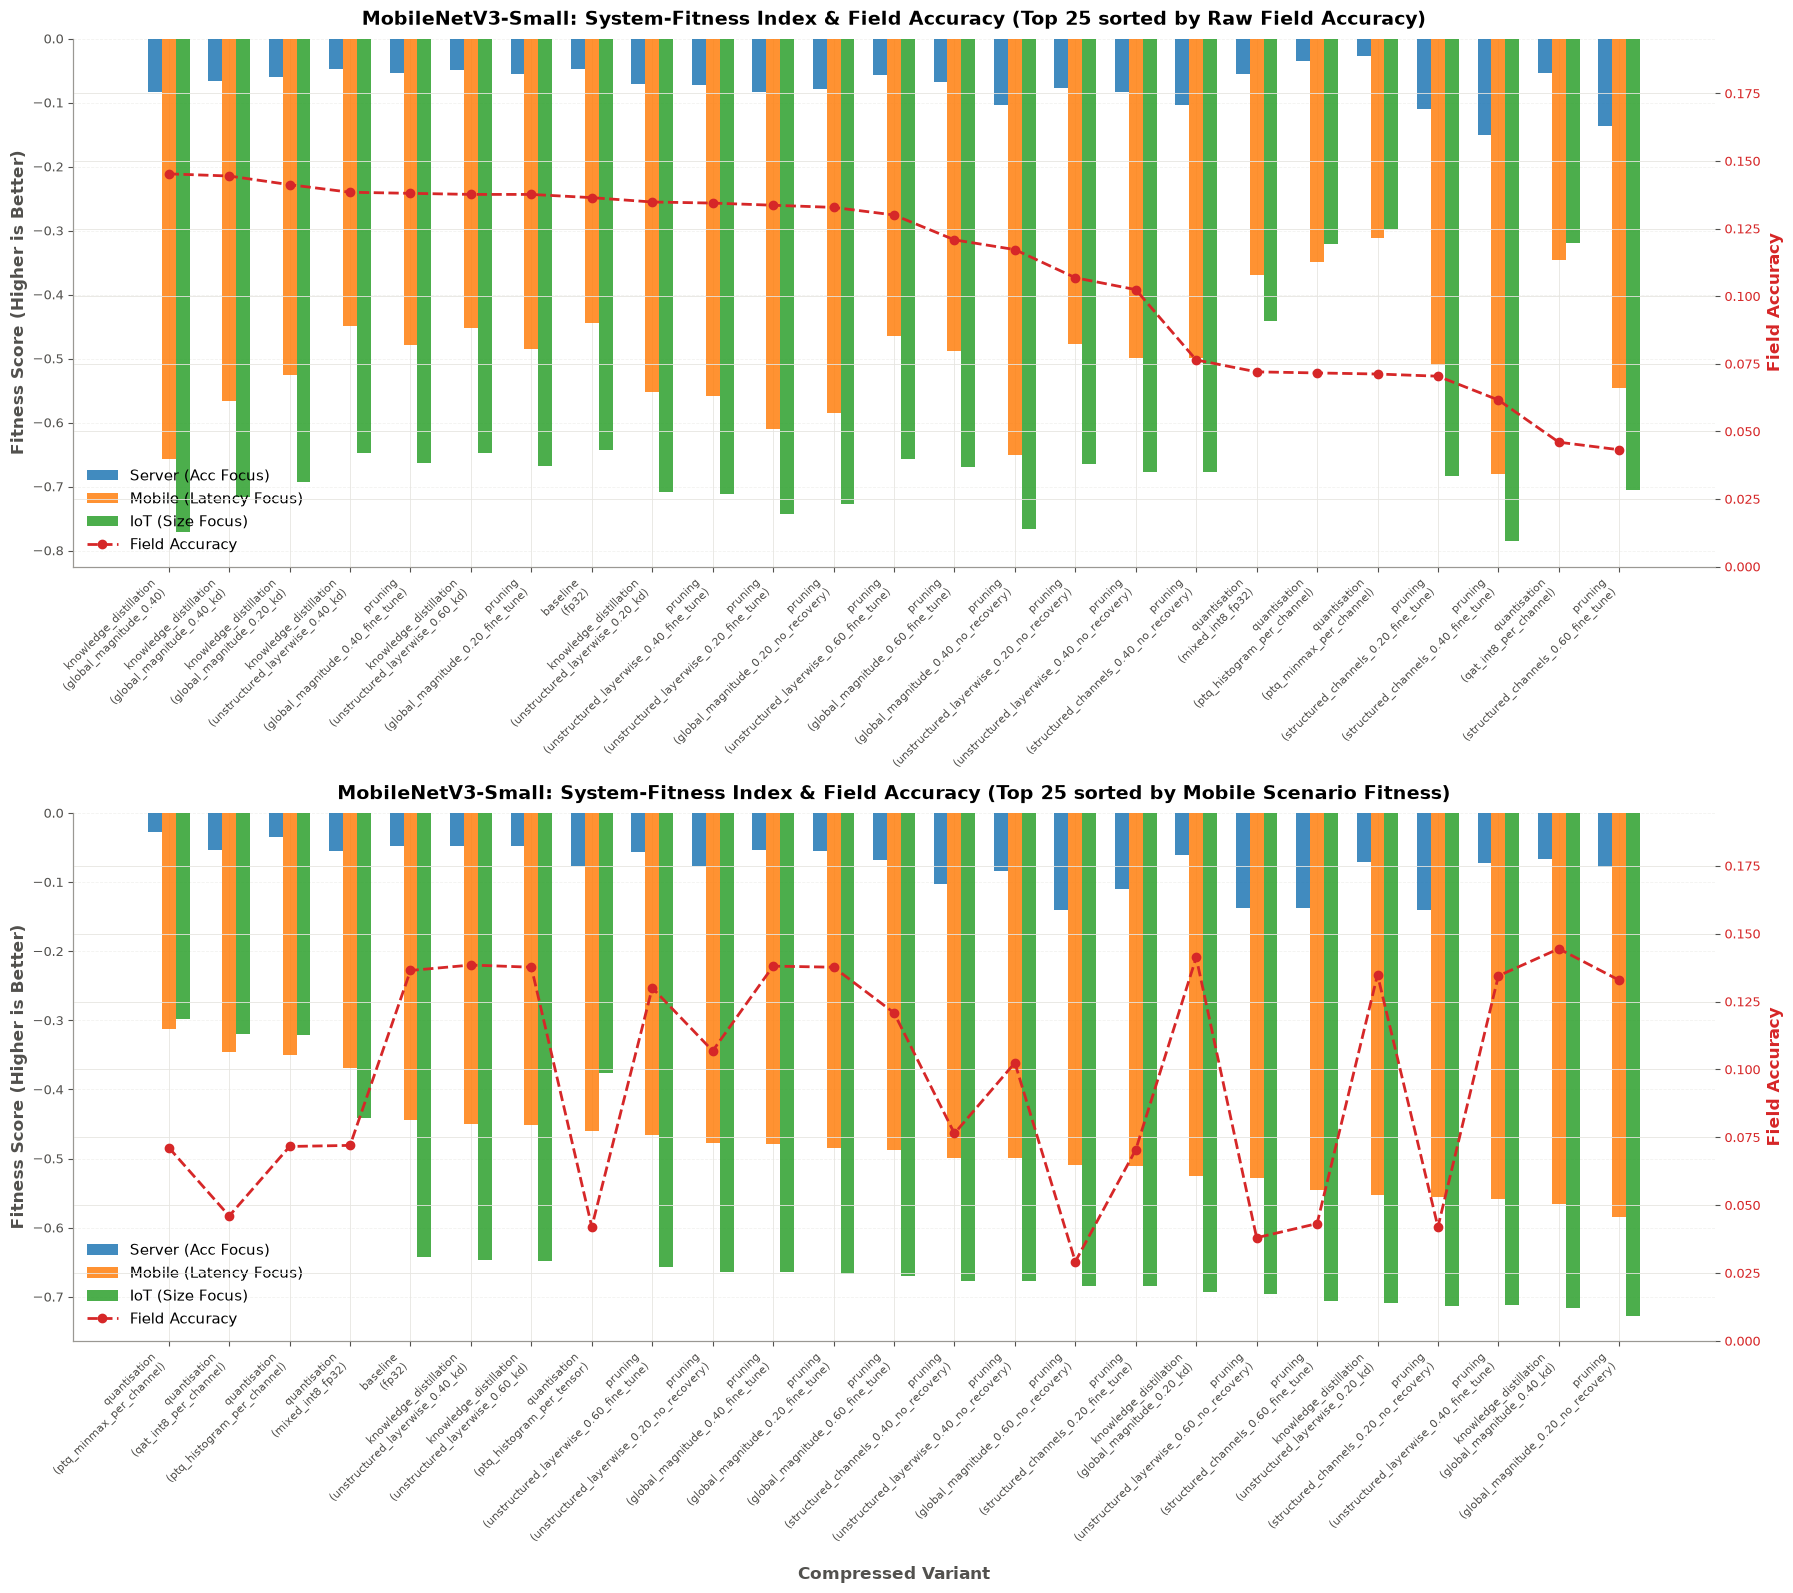

In [39]:
# 4.14f MobileNetV3-Small: system-fitness index
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_mob = df_results[df_results['architecture'] == 'mobilenet_v3_small'].copy()

    # Define normalization limits based on MobileNet dataset maximums
    max_lat = df_mob['cpu_latency_mean_ms'].max()
    max_size = df_mob['model_size_mb'].max()

    # Calculate scores
    def calc_fitness(row, w_acc, w_lat, w_size):
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    df_mob['Server Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_mob['Mobile Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_mob['IoT Scenario'] = df_mob.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    # --- Graph 1: Sorted by Pure Field Accuracy ---
    df_plot_acc = df_mob.sort_values(by=['field_accuracy', 'cpu_latency_mean_ms'], ascending=[False, True]).head(25).copy()
    df_plot_acc['label'] = df_plot_acc['method'] + '\n(' + df_plot_acc['variant'].str.replace('_partial', '') + ')'

    fig, (ax_acc1, ax_mob1) = plt.subplots(2, 1, figsize=(18, 16))

    x = np.arange(len(df_plot_acc))
    width = 0.23

    # Plot 1 (Accuracy Sorted) Primary Y-axis
    ax_acc1.bar(x - width, df_plot_acc['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_acc1.bar(x, df_plot_acc['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_acc1.bar(x + width, df_plot_acc['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_acc1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_acc1.set_title('MobileNetV3-Small: System-Fitness Index & Field Accuracy (Top 25 sorted by Raw Field Accuracy)', fontsize=14, fontweight='bold', pad=10)
    ax_acc1.set_xticks(x)
    ax_acc1.set_xticklabels(df_plot_acc['label'], rotation=45, ha='right', fontsize=8)
    ax_acc1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 1 Secondary Y-axis
    ax_acc2 = ax_acc1.twinx()
    ax_acc2.plot(x, df_plot_acc['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_acc2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_acc2.tick_params(axis='y', labelcolor='#d62728')
    min_acc = max(0.0, df_plot_acc['field_accuracy'].min() - 0.05)
    max_acc = min(1.0, df_plot_acc['field_accuracy'].max() + 0.05)
    ax_acc2.set_ylim(min_acc, max_acc)

    lines, labels = ax_acc1.get_legend_handles_labels()
    lines2, labels2 = ax_acc2.get_legend_handles_labels()
    ax_acc1.legend(lines + lines2, labels + labels2, loc='lower left', fontsize=11)

    # --- Graph 2: Sorted by Mobile Scenario Fitness ---
    df_plot_mob = df_mob.sort_values(by=['Mobile Scenario', 'field_accuracy'], ascending=[False, False]).head(25).copy()
    df_plot_mob['label'] = df_plot_mob['method'] + '\n(' + df_plot_mob['variant'].str.replace('_partial', '') + ')'

    # Plot 2 (Mobile Sorted) Primary Y-axis
    ax_mob1.bar(x - width, df_plot_mob['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_mob1.bar(x, df_plot_mob['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_mob1.bar(x + width, df_plot_mob['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_mob1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_mob1.set_xlabel('Compressed Variant', fontsize=12, fontweight='bold', labelpad=15)
    ax_mob1.set_title('MobileNetV3-Small: System-Fitness Index & Field Accuracy (Top 25 sorted by Mobile Scenario Fitness)', fontsize=14, fontweight='bold', pad=10)
    ax_mob1.set_xticks(x)
    ax_mob1.set_xticklabels(df_plot_mob['label'], rotation=45, ha='right', fontsize=8)
    ax_mob1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 2 Secondary Y-axis
    ax_mob2 = ax_mob1.twinx()
    ax_mob2.plot(x, df_plot_mob['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_mob2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_mob2.tick_params(axis='y', labelcolor='#d62728')
    min_acc_m = max(0.0, df_plot_mob['field_accuracy'].min() - 0.05)
    max_acc_m = min(1.0, df_plot_mob['field_accuracy'].max() + 0.05)
    ax_mob2.set_ylim(min_acc_m, max_acc_m)

    lines_m, labels_m = ax_mob1.get_legend_handles_labels()
    lines2_m, labels2_m = ax_mob2.get_legend_handles_labels()
    ax_mob1.legend(lines_m + lines2_m, labels_m + labels2_m, loc='lower left', fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found!")

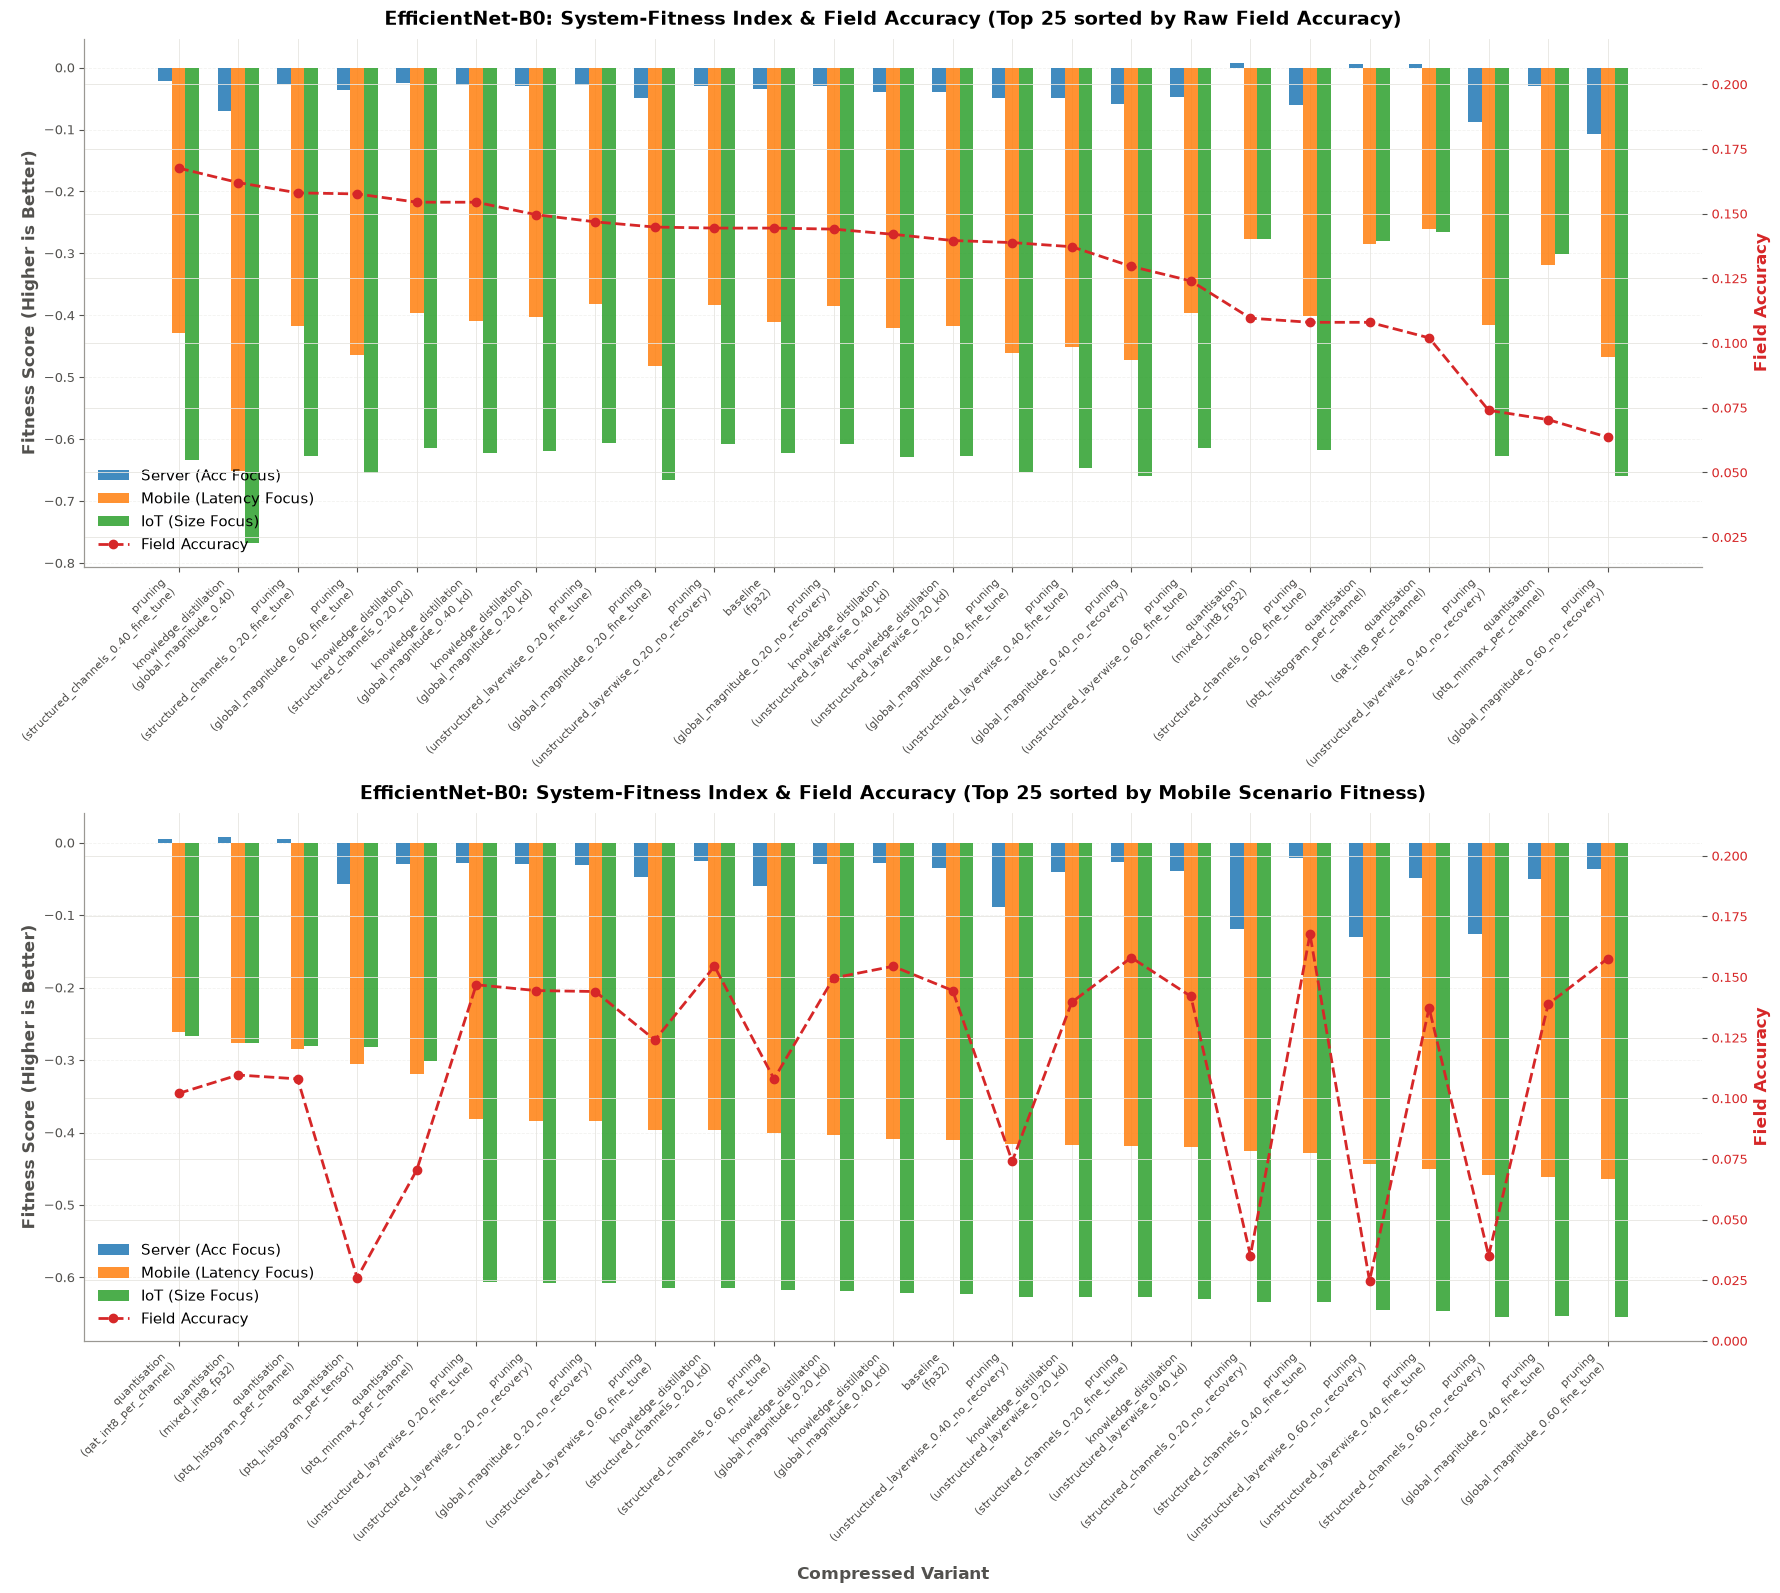

In [40]:
# 4.14g EfficientNet-B0: system-fitness index
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

results_path = RESULTS_DIR / 'aligned_compression_results_partial.csv'
if results_path.exists():
    df_results = pd.read_csv(results_path)
    df_eff = df_results[df_results['architecture'] == 'efficientnet_b0'].copy()

    # Define normalization limits based on EfficientNet dataset maximums
    max_lat = df_eff['cpu_latency_mean_ms'].max()
    max_size = df_eff['model_size_mb'].max()

    # Calculate scores
    def calc_fitness(row, w_acc, w_lat, w_size):
        acc_score = row['field_accuracy']
        lat_score = row['cpu_latency_mean_ms'] / max_lat if max_lat > 0 else 1.0
        size_score = row['model_size_mb'] / max_size if max_size > 0 else 1.0
        return w_acc * acc_score - w_lat * lat_score - w_size * size_score

    df_eff['Server Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.8, 0.1, 0.1), axis=1)
    df_eff['Mobile Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.3, 0.5, 0.2), axis=1)
    df_eff['IoT Scenario'] = df_eff.apply(lambda r: calc_fitness(r, 0.2, 0.3, 0.5), axis=1)

    # --- Graph 1: Sorted by Pure Field Accuracy ---
    df_plot_acc = df_eff.sort_values(by=['field_accuracy', 'cpu_latency_mean_ms'], ascending=[False, True]).head(25).copy()
    df_plot_acc['label'] = df_plot_acc['method'] + '\n(' + df_plot_acc['variant'].str.replace('_partial', '') + ')'

    fig, (ax_acc1, ax_mob1) = plt.subplots(2, 1, figsize=(18, 16))

    x = np.arange(len(df_plot_acc))
    width = 0.23

    # Plot 1 (Accuracy Sorted) Primary Y-axis
    ax_acc1.bar(x - width, df_plot_acc['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_acc1.bar(x, df_plot_acc['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_acc1.bar(x + width, df_plot_acc['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_acc1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_acc1.set_title('EfficientNet-B0: System-Fitness Index & Field Accuracy (Top 25 sorted by Raw Field Accuracy)', fontsize=14, fontweight='bold', pad=10)
    ax_acc1.set_xticks(x)
    ax_acc1.set_xticklabels(df_plot_acc['label'], rotation=45, ha='right', fontsize=8)
    ax_acc1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 1 Secondary Y-axis
    ax_acc2 = ax_acc1.twinx()
    ax_acc2.plot(x, df_plot_acc['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_acc2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_acc2.tick_params(axis='y', labelcolor='#d62728')
    min_acc = max(0.0, df_plot_acc['field_accuracy'].min() - 0.05)
    max_acc = min(1.0, df_plot_acc['field_accuracy'].max() + 0.05)
    ax_acc2.set_ylim(min_acc, max_acc)

    lines, labels = ax_acc1.get_legend_handles_labels()
    lines2, labels2 = ax_acc2.get_legend_handles_labels()
    ax_acc1.legend(lines + lines2, labels + labels2, loc='lower left', fontsize=11)

    # --- Graph 2: Sorted by Mobile Scenario Fitness ---
    df_plot_mob = df_eff.sort_values(by=['Mobile Scenario', 'field_accuracy'], ascending=[False, False]).head(25).copy()
    df_plot_mob['label'] = df_plot_mob['method'] + '\n(' + df_plot_mob['variant'].str.replace('_partial', '') + ')'

    # Plot 2 (Mobile Sorted) Primary Y-axis
    ax_mob1.bar(x - width, df_plot_mob['Server Scenario'], width, label='Server (Acc Focus)', color='#1f77b4', alpha=0.85)
    ax_mob1.bar(x, df_plot_mob['Mobile Scenario'], width, label='Mobile (Latency Focus)', color='#ff7f0e', alpha=0.85)
    ax_mob1.bar(x + width, df_plot_mob['IoT Scenario'], width, label='IoT (Size Focus)', color='#2ca02c', alpha=0.85)
    ax_mob1.set_ylabel('Fitness Score (Higher is Better)', fontsize=12, fontweight='bold')
    ax_mob1.set_xlabel('Compressed Variant', fontsize=12, fontweight='bold', labelpad=15)
    ax_mob1.set_title('EfficientNet-B0: System-Fitness Index & Field Accuracy (Top 25 sorted by Mobile Scenario Fitness)', fontsize=14, fontweight='bold', pad=10)
    ax_mob1.set_xticks(x)
    ax_mob1.set_xticklabels(df_plot_mob['label'], rotation=45, ha='right', fontsize=8)
    ax_mob1.grid(axis='y', linestyle='--', alpha=0.5)

    # Plot 2 Secondary Y-axis
    ax_mob2 = ax_mob1.twinx()
    ax_mob2.plot(x, df_plot_mob['field_accuracy'], color='#d62728', marker='o', markersize=6, linewidth=2.0, linestyle='--', label='Field Accuracy')
    ax_mob2.set_ylabel('Field Accuracy', color='#d62728', fontsize=12, fontweight='bold')
    ax_mob2.tick_params(axis='y', labelcolor='#d62728')
    min_acc_m = max(0.0, df_plot_mob['field_accuracy'].min() - 0.05)
    max_acc_m = min(1.0, df_plot_mob['field_accuracy'].max() + 0.05)
    ax_mob2.set_ylim(min_acc_m, max_acc_m)

    lines_m, labels_m = ax_mob1.get_legend_handles_labels()
    lines2_m, labels2_m = ax_mob2.get_legend_handles_labels()
    ax_mob1.legend(lines_m + lines2_m, labels_m + labels2_m, loc='lower left', fontsize=11)

    plt.tight_layout()
    plt.show()
else:
    print("Consolidated results CSV not found! Please run the consolidation cells first.")

### 4.15 Exploratory: stacking compressed EfficientNets

Off by default (`STAGES["rq71_ensembles"]`): nine full models on both test sets is slow, and the results are printed, not saved. The models are chosen by test-set fitness, so these numbers are exploratory.

In [41]:
# 4.15a Nine-model stack
if not STAGES["rq71_ensembles"]:
    print("Skipped: STAGES[\"rq71_ensembles\"] is False (exploratory).")
else:
    import torch
    import torch.nn as nn
    from pathlib import Path
    from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
    from torch.ao.quantization import QConfigMapping

    print("=== OPTION 1: 9-Model Full Stacking Ensemble ===")

    class EnsembleStack(nn.Module):
        def __init__(self, arch, model_paths, num_classes=26):
            super().__init__()
            self.models = nn.ModuleList()
            for path in model_paths:
                state_dict = torch.load(path, map_location='cpu')
                if 'model_state_dict' in state_dict:
                    state_dict = state_dict['model_state_dict']

                m = build_model_71(arch)

                # Detect quantization by checking if any loaded tensor is a quantized parameter type
                is_quantized = any(isinstance(v, torch.Tensor) and v.is_quantized for v in state_dict.values())

                if is_quantized:
                    # Recreate the exact FX quantization structure
                    mapping = QConfigMapping().set_global(ptq_qconfig('histogram', True))
                    if 'mixed' in str(path):
                        mapping = mapping.set_module_name('classifier', None)
                    prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
                    m = convert_fx(prepared).eval()

                # Load the state dict using the correctly-structured model
                m.load_state_dict(state_dict, strict=True)
                m.eval()
                self.models.append(m)

        def forward(self, x):
            # Run inference across all sub-models and average the output logits
            logits = [model(x) for model in self.models]
            return torch.stack(logits, dim=0).mean(dim=0)

    model_keys = [
        'efficientnet_b0_quantisation_qat_int8_per_channel_partial.pth',
        'efficientnet_b0_quantisation_mixed_int8_fp32_partial.pth',
        'efficientnet_b0_quantisation_ptq_histogram_per_channel_partial.pth',
        'efficientnet_b0_pruning_unstructured_layerwise_0.20_fine_tune_partial.pth',
        'efficientnet_b0_pruning_structured_channels_0.40_fine_tune_partial.pth',
        'efficientnet_b0_pruning_global_magnitude_0.20_no_recovery_partial.pth',
        'efficientnet_b0_knowledge_distillation_structured_channels_0.20_kd_partial.pth',
        'efficientnet_b0_knowledge_distillation_global_magnitude_0.40_kd_partial.pth',
        'efficientnet_b0_knowledge_distillation_unstructured_layerwise_0.40_kd_partial.pth'
    ]

    local_valid_paths = [OUTPUT_MODEL_DIR / k for k in model_keys if (OUTPUT_MODEL_DIR / k).exists()]

    if len(local_valid_paths) == 9:
        print("All 9 checkpoints are present on disk. Initializing the 9-model Stack...")
        full_stack = EnsembleStack(arch='efficientnet_b0', model_paths=local_valid_paths)
        full_stack = full_stack.to(device).eval()

        # Benchmarking latency
        print("Measuring CPU Latency for 9-Model Stack...")
        lat_mean, lat_std = cpu_latency_ms(full_stack, test_loader.dataset)

        # Evaluating test split
        print("Evaluating on Test Split...")
        test_metrics = evaluate_split(full_stack, test_loader, device)

        # Evaluating field split
        print("Evaluating on Field Split...")
        field_metrics = evaluate_split(full_stack, field_loader, device)

        print("\n--- 9-Model Stack Evaluation Results ---")
        print(f"Test Accuracy  : {test_metrics['accuracy']:.4%}")
        print(f"Field Accuracy : {field_metrics['accuracy']:.4%}")
        print(f"CPU Latency    : {lat_mean:.2f} ms ± {lat_std:.2f} ms")
    else:
        print(f"Warning: Only {len(local_valid_paths)}/9 checkpoints were found on disk.")

Skipped: STAGES["rq71_ensembles"] is False (exploratory).


In [42]:
# 4.15b Three-model stack, one per technique
if not STAGES["rq71_ensembles"]:
    print("Skipped: STAGES[\"rq71_ensembles\"] is False (exploratory).")
else:
    import torch
    import torch.nn as nn
    from pathlib import Path
    from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
    from torch.ao.quantization import QConfigMapping

    print("=== OPTION 2: 3-Model Selective Hybrid Stacking Ensemble ===")

    class EnsembleStack(nn.Module):
        def __init__(self, arch, model_paths, num_classes=26):
            super().__init__()
            self.models = nn.ModuleList()
            for path in model_paths:
                state_dict = torch.load(path, map_location='cpu')
                if 'model_state_dict' in state_dict:
                    state_dict = state_dict['model_state_dict']

                m = build_model_71(arch)
                is_quantized = any(isinstance(v, torch.Tensor) and v.is_quantized for v in state_dict.values())

                if is_quantized:
                    # Structurally prepare the model for PyTorch FX Quantization to accept quantized weights
                    mapping = QConfigMapping().set_global(ptq_qconfig('histogram', True))
                    if 'mixed' in str(path):
                        mapping = mapping.set_module_name('classifier', None)
                    prepared = prepare_fx(m.cpu().eval(), mapping, example_inputs)
                    m = convert_fx(prepared).eval()
                    m.load_state_dict(state_dict, strict=True)
                else:
                    # Non-quantized model (e.g. standard FP32 pruned or KD model)
                    m.load_state_dict(state_dict, strict=True)

                m.eval()
                self.models.append(m)

        def forward(self, x):
            logits = [model(x) for model in self.models]
            return torch.stack(logits, dim=0).mean(dim=0)

    # Force dataloaders to run sequentially with num_workers=0 to prevent background worker crashes
    test_loader = make_loader_71(test_df, eval_tf, shuffle=False)
    field_loader = make_loader_71(field_df, eval_tf, shuffle=False)

    selective_keys = [
        'efficientnet_b0_quantisation_qat_int8_per_channel_partial.pth',
        'efficientnet_b0_pruning_unstructured_layerwise_0.20_fine_tune_partial.pth',
        'efficientnet_b0_knowledge_distillation_structured_channels_0.20_kd_partial.pth'
    ]

    selective_paths = [OUTPUT_MODEL_DIR / k for k in selective_keys if (OUTPUT_MODEL_DIR / k).exists()]

    if len(selective_paths) == 3:
        print(f"All 3 targeted hybrid checkpoints found. Initializing the 3-model Hybrid Stack...")
        hybrid_stack = EnsembleStack(arch='efficientnet_b0', model_paths=selective_paths)
        hybrid_stack = hybrid_stack.to(device).eval()

        # Benchmarking latency
        print("Measuring CPU Latency for 3-Model Stack...")
        hybrid_lat_mean, hybrid_lat_std = cpu_latency_ms(hybrid_stack, test_loader.dataset)

        # Evaluating test split
        print("Evaluating on Test Split...")
        hybrid_test_metrics = evaluate_split(hybrid_stack, test_loader, device)

        # Evaluating field split
        print("Evaluating on Field Split...")
        hybrid_field_metrics = evaluate_split(hybrid_stack, field_loader, device)

        print("\n--- 3-Model Hybrid Stack Evaluation Results ---")
        print(f"Test Accuracy  : {hybrid_test_metrics['accuracy']:.4%}")
        print(f"Field Accuracy : {hybrid_field_metrics['accuracy']:.4%}")
        print(f"CPU Latency    : {hybrid_lat_mean:.2f} ms ± {hybrid_lat_std:.2f} ms")
    else:
        print(f"Warning: Only found {len(selective_paths)}/3 targeted hybrid checkpoints on disk.")

Skipped: STAGES["rq71_ensembles"] is False (exploratory).


## Part 5 · RQ7.2: the laboratory-to-field gap

> *How large is the performance drop between laboratory-condition training images
> and field-condition test images, and which augmentation strategies reduce it most?*

Train on PlantVillage only. Score every model on held-out PlantVillage (`lab_test`)
and on the PlantDoc test split (`field_test`), with the same classes and metric.

* **Claim 1, the gap:** the control arm A0 (minimal augmentation) gives
  lab macro-F1 minus field macro-F1, with a bootstrap interval.
* **Claim 2, what reduces it:** arms A1 to A4 differ from A0 in augmentation only.
  Each is compared with A0 by a paired bootstrap on the same field images,
  averaged over three seeds.

In [43]:
# 5.1 Smoke test: proves the training loop works on this machine; its numbers mean nothing
if not STAGES["rq72_smoke"]:
    print("Skipped: STAGES[\"rq72_smoke\"] is False (plumbing test only).")
else:
    scfg = make_config(smoke=True, backbone=BACKBONE, **{**EXTRA, "manifest": PIPELINE["full_manifest"]})
    run_sweep(scfg, prepare_data(scfg, verbose=False))

Skipped: STAGES["rq72_smoke"] is False (plumbing test only).


In [44]:
# 5.2 The sweep: 5 arms x 3 seeds
if not STAGES["rq72_sweep"]:
    print("Skipped: STAGES[\"rq72_sweep\"] is False (finished runs are analysed below).")
else:
    run_sweep(cfg, data)


=== run 1/15: A0_none, seed 42 ===
[skip] A0_none__seed42 already done

=== run 2/15: A1_geometric, seed 42 ===
[skip] A1_geometric__seed42 already done

=== run 3/15: A2_photometric, seed 42 ===
[skip] A2_photometric__seed42 already done

=== run 4/15: A3_degradation, seed 42 ===
[skip] A3_degradation__seed42 already done

=== run 5/15: A4_combined, seed 42 ===
[skip] A4_combined__seed42 already done

=== run 6/15: A0_none, seed 43 ===
[skip] A0_none__seed43 already done

=== run 7/15: A1_geometric, seed 43 ===
[skip] A1_geometric__seed43 already done

=== run 8/15: A2_photometric, seed 43 ===
[skip] A2_photometric__seed43 already done

=== run 9/15: A3_degradation, seed 43 ===
[skip] A3_degradation__seed43 already done

=== run 10/15: A4_combined, seed 43 ===
[skip] A4_combined__seed43 already done

=== run 11/15: A0_none, seed 44 ===
[skip] A0_none__seed44 already done

=== run 12/15: A1_geometric, seed 44 ===
[skip] A1_geometric__seed44 already done

=== run 13/15: A2_photometric,

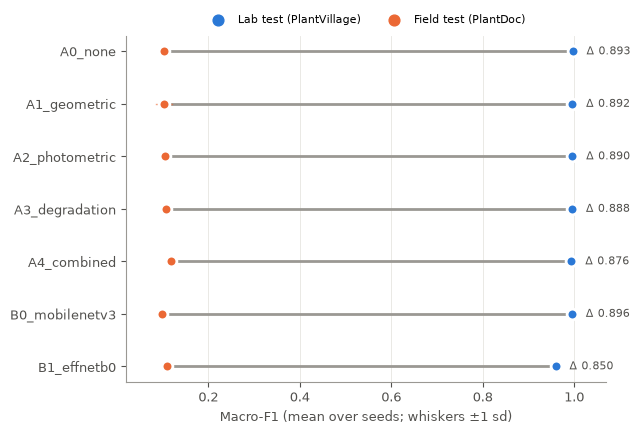

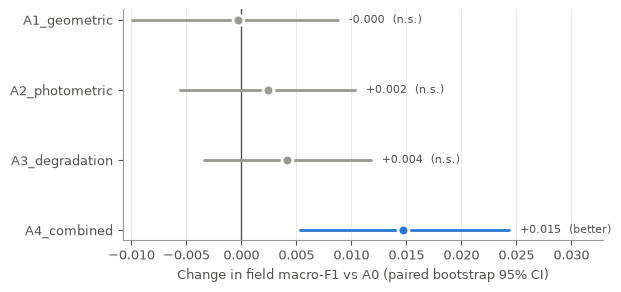

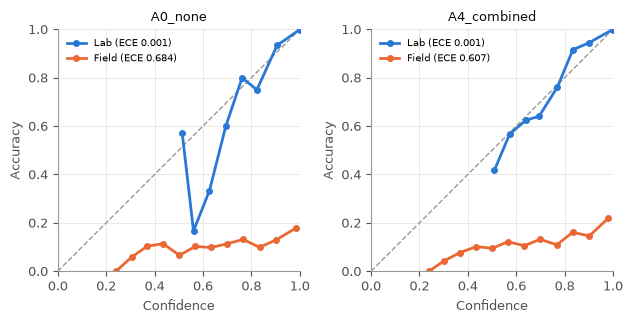

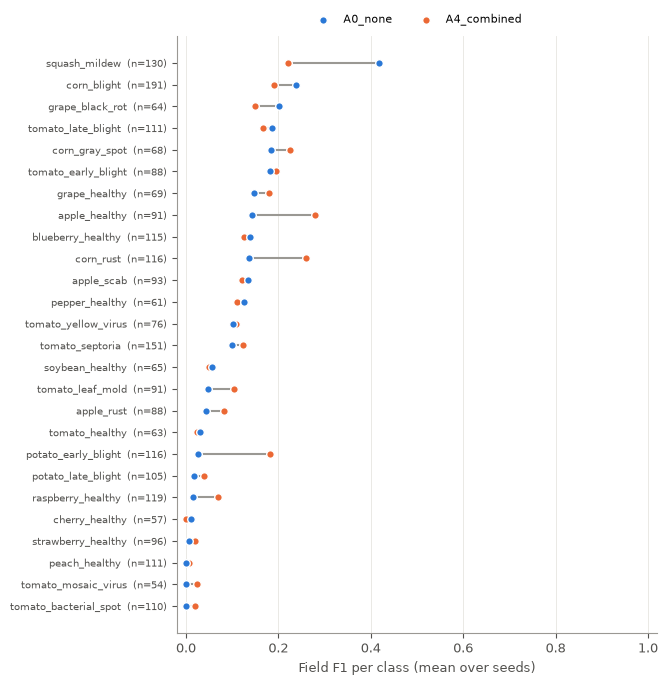

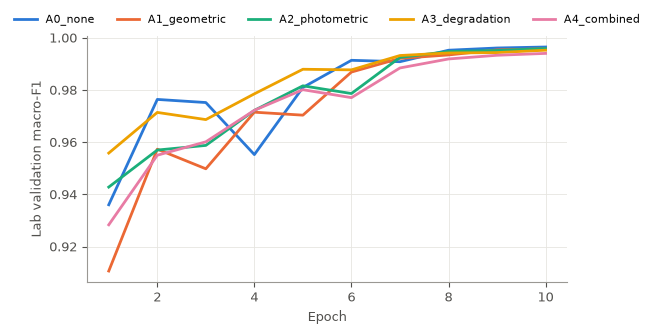

           arm  n_seeds  lab_f1  field_f1   gap  field_gain  field_gain_ci_lo  field_gain_ci_hi  field_gain_p  gap_closed  field_ece
       A0_none        3   0.996     0.104 0.893       0.000             0.000             0.000           NaN       0.000      0.684
  A1_geometric        3   0.996     0.103 0.892      -0.000            -0.010             0.009         0.912      -0.000      0.653
A2_photometric        3   0.996     0.106 0.890       0.002            -0.006             0.010         0.550       0.003      0.657
A3_degradation        3   0.995     0.108 0.888       0.004            -0.003             0.012         0.305       0.005      0.655
   A4_combined        3   0.994     0.118 0.876       0.015             0.005             0.024         0.001       0.016      0.607
B0_mobilenetv3        1   0.995     0.099 0.896      -0.004            -0.015             0.006         0.411      -0.005      0.694
   B1_effnetb0        1   0.959     0.109 0.850       0.005          

,arm,n_seeds,hypothesis,lab_f1,lab_f1_sd,field_f1,field_f1_sd,gap,gap_sd,gap_ci_lo,...,field_gain_ci_lo,field_gain_ci_hi,field_gain_p,lab_cost_ci_lo,lab_cost_ci_hi,lab_ece,field_ece,lab_acc,field_acc,gap_closed
0,A0_none,3,Control: the group baseline's augmentation (re...,0.996437,0.001101,0.103530,0.002920,0.892907,0.003486,0.883981,...,0.000000,0.000000,NaN,0.000000,0.000000,0.001548,0.683728,0.997520,0.140456,0.000000
1,A1_geometric,3,"Field photos differ in framing, scale, angle a...",0.995565,0.000225,0.103254,0.016862,0.892312,0.016771,0.883056,...,-0.009932,0.008742,0.912,-0.002199,0.000467,0.001539,0.652812,0.996838,0.129518,-0.000310
2,A2_photometric,3,Field photos differ in illumination: colour ca...,0.995704,0.000713,0.105930,0.006682,0.889773,0.006932,0.879833,...,-0.005568,0.010314,0.550,-0.002279,0.000825,0.001650,0.657120,0.997024,0.142057,0.002688
3,A3_degradation,3,Phone cameras lose lesion detail: fewer pixels...,0.995251,0.000825,0.107654,0.005236,0.887597,0.004594,0.877885,...,-0.003382,0.011751,0.305,-0.002789,0.000461,0.001925,0.655257,0.996776,0.149526,0.004619
4,A4_combined,3,The factors are complementary: A1 + A2 + A3 to...,0.993813,0.001373,0.118224,0.004205,0.875589,0.003428,0.865015,...,0.005309,0.024328,0.001,-0.004649,-0.000612,0.002198,0.607295,0.995536,0.148860,0.016457
5,B0_mobilenetv3,1,Existing mobilenet_v3_small checkpoint (mobile...,0.994923,NaN,0.099329,NaN,0.895594,NaN,0.884377,...,-0.014756,0.006117,0.411,-0.003660,0.000348,0.001541,0.693656,0.995908,0.135254,-0.004705
6,B1_effnetb0,1,Existing efficientnet_b0 checkpoint (effnetb0_...,0.959195,NaN,0.108700,NaN,0.850494,NaN,0.837386,...,-0.006834,0.017060,0.445,-0.044136,-0.030983,0.007302,0.424091,0.971354,0.134854,0.005790


In [45]:
# 5.3 Analysis: tables, figures and the headline sentence for report section 5
table = analyse(cfg, data)
table

## Part 6 · RQ7.1 × RQ7.2: does compression cost more in the field, and does augmentation survive it?

Inputs: Part 4's CSV and checkpoints, and Part 5's trained models. Three parts, in priority order:

| Part | Question | Cells | Cost |
|---|---|---|---|
| A. Joint table | Does compression cost more accuracy in the field than in the lab? | 6.2 | minutes (int8 on CPU) |
| B. Augment, then compress | Does A4's field gain over A0 survive pruning and int8? | 6.3–6.4 | ~1.5–2 h on a T4 |
| C. Compress, then augment | Which compressed model, briefly fine-tuned with which arm, is best? | 6.5–6.8 | ~4 h MobileNet + ~8 h EfficientNet |

In [46]:
# 6.1 Settings for the compression x augmentation study
# Reuses `cfg` and `data` from Part 2 (same manifest, image cache, class order and test sets).
COMP = {
    # inputs from COS801_Compression_Final.ipynb
    "results_csv": "results/aligned_compression_partial/aligned_compression_results_partial.csv",
    "model_dir": "models/aligned_compression_partial",   # used if a saved_state path in the CSV does not resolve
    "archs": ["mobilenet_v3_small", "efficientnet_b0"],
    "baselines": {                                       # each architecture's baseline: its saved class names give
        "mobilenet_v3_small": "models/mobilenetv3_baseline_best.pth",   # the output order every compressed
        "efficientnet_b0": "models/effnetb0_baseline_best.pth",          # model of that architecture inherits
    },
    "families": ["pruned", "fine_tuned", "kd"],          # one parent per family = a shortlist of 3 per architecture
    "include_baseline_parent": False,                    # True adds the unpruned baseline as a 4th parent (+15 runs):
                                                         # same fine-tune recipe, so it isolates the effect of pruning
    # the experiment
    "arms": ["A0_none", "A1_geometric", "A2_photometric", "A3_degradation", "A4_combined"],
    "seeds": [42, 43, 44],
    "epochs": 2,                 # short fine-tune from the compressed weights, identical for every arm
    "lr": 1e-4,
    "weight_decay": 1e-4,
    "use_50pct": True,           # fine-tune on the use_50pct subset, as the compression notebook did
    "subset_manifest": "data/data_split_resolved.csv",   # the CSV that carries the use_50pct column
    "keep_masks": True,          # pruned weights stay exactly zero during fine-tuning
    # selection (lab validation only; the field test is never used to choose anything)
    "selection_per_class": 50,   # fixed, class-stratified lab_val subset used for every model-selection decision
    "val_tie": 0.002,            # models within this macro-F1 of the best count as tied
    # int8 branch: each fine-tuned model is re-quantised with the PTQ recipe chosen on lab_val for its parent
    "requantise": True,
    "quant_recipes": ["ptq_histogram_per_channel", "mixed_int8_fp32", "ptq_minmax_per_channel", "ptq_histogram_per_tensor"],
    "calibration_samples": 1024,
    "requant_seeds": {           # int8 is a CPU step: ~3 min per MobileNet run, ~8 min per EfficientNet run on Colab
        "mobilenet_v3_small": None,      # None = every seed
        "efficientnet_b0": [42],         # one seed keeps EfficientNet's int8 step to ~2 h; use None for all three
    },
    # Option 1 (joint table): also score the compression notebook's int8 models (CPU, a few minutes each)
    "joint_include_int8": True,
    # Option 2 (augment, then compress): RQ7.2's trained models (MobileNet; the RQ7.2 sweep has no EfficientNet arms)
    "aug_then_compress": {
        "arms": ["A0_none", "A4_combined"],          # control first, then the arm whose gain is tested
        "seeds": [42, 43, 44],
        "prune_kinds": ["global_magnitude"],         # also: "unstructured_layerwise", "structured_channels"
        "prune_amounts": [0.2, 0.4],
        "recovery": True,                            # + a short fine-tune with the SAME arm, masks kept (GPU)
        "int8": True,                                # PTQ with the recipe chosen on lab_val (CPU)
        "tflite_exports_dir": None,                  # e.g. "results/rq71_exports_colab": adds the export notebook's
    },                                               # TFLite int8 results for these arms, if it was run on them
    # deployment budget for the final choice (None = no limit)
    "budget_mb": None,           # judged on the gzip size: pruned zeros only save space when compressed
    "budget_ms": None,           # CPU, 1 thread, batch 1
    # bookkeeping
    "results_dir": "results/rq72_compressed",            # one sub-folder per architecture
    "time_budget_h": 6,          # the sweep starts no run it cannot finish in time; rerun to continue
}

# Which architectures this runtime works on. Both on one T4 is ~12 h; to halve that, open the notebook in a
# second Colab GPU runtime and set this to ["mobilenet_v3_small"] in one and ["efficientnet_b0"] in the other.
ARCHS_HERE = COMP["archs"]

In [47]:
# 6.1b Functions: shortlist, fine-tune, int8, analysis
import gzip
import re
import warnings

# The compression notebook's SHARED_CLASSES order. Its checkpoints' outputs are in this order, so it must
# equal the class order used here, or every score below would be computed against the wrong labels.
COMPRESSION_CLASS_ORDER = [
    "apple_scab", "apple_rust", "apple_healthy", "blueberry_healthy", "cherry_healthy",
    "corn_gray_spot", "corn_rust", "corn_blight", "grape_black_rot", "grape_healthy",
    "peach_healthy", "pepper_healthy", "potato_early_blight", "potato_late_blight",
    "raspberry_healthy", "soybean_healthy", "squash_mildew", "strawberry_healthy",
    "tomato_bacterial_spot", "tomato_early_blight", "tomato_late_blight", "tomato_leaf_mold",
    "tomato_septoria", "tomato_yellow_virus", "tomato_mosaic_virus", "tomato_healthy"]

# Same PTQ recipes as COS801_Compression_Final (observer, per-channel weights, classifier left in FP32)
QUANT_RECIPES = {
    "ptq_minmax_per_channel": ("minmax", True, False),
    "ptq_histogram_per_channel": ("histogram", True, False),
    "ptq_histogram_per_tensor": ("histogram", False, False),
    "mixed_int8_fp32": ("histogram", True, True),
}


# ---------------------------------------------------------------- paths and inputs
def comp_for(comp_all: dict, arch: str) -> dict:
    """The settings for one architecture: its own results folder, baseline and int8 seed list."""
    c = {k: v for k, v in comp_all.items() if k not in ("archs", "baselines")}
    rs = comp_all.get("requant_seeds")
    c.update(arch=arch, baseline=comp_all["baselines"][arch],
             results_dir=f"{comp_all['results_dir']}/{arch}",
             requant_seeds=rs.get(arch) if isinstance(rs, dict) else rs)
    return c


def _comp_path(data, p) -> Path:
    p = Path(p)
    return p if p.is_absolute() else data["root"] / p


def _comp_out(comp, data) -> Path:
    out = _comp_path(data, comp["results_dir"])
    out.mkdir(parents=True, exist_ok=True)
    return out


def _family(method, variant) -> str:
    v = str(variant)
    if method == "knowledge_distillation":
        return "kd"
    if method == "pruning":
        return "fine_tuned" if "fine_tune" in v else ("pruned" if "no_recovery" in v else "pruning_other")
    if method == "quantisation":
        return "quantised"
    return str(method)


def _tag(family, variant) -> str:
    v = str(variant).replace("_partial", "")
    return f"{family}-{v}".replace(".", "p").replace("/", "_").replace(" ", "_")


def _nominal_sparsity(variant):
    m = re.search(r"_(0\.\d+)", str(variant))
    return float(m.group(1)) if m else 0.0


def _resolve_state(saved_state, model_dir: Path) -> Path:
    p = Path(str(saved_state))
    if p.exists():
        return p
    q = model_dir / p.name   # the CSV stores Colab paths; locally the file sits under the same folder name
    if q.exists():
        return q
    raise FileNotFoundError(f"Compressed checkpoint not found: {p} (also tried {q})")


def _subset_mask(data, comp) -> pd.Series:
    """True for lab_train rows in the use_50pct subset. Checks that the subset CSV has the same
    val/test/field rows as this notebook's manifest, so the two notebooks share their test sets."""
    df = data["df"]
    is_train = df.role == "lab_train"
    if not comp.get("use_50pct"):
        return is_train
    sub = pd.read_csv(_comp_path(data, comp["subset_manifest"]))
    if "use_50pct" not in sub.columns:
        raise KeyError(f"{comp['subset_manifest']} has no use_50pct column")
    pcol = "path"
    for role, split in (("lab_val", "val"), ("lab_test", "test"), ("lab_train", "train")):
        a = set(df.loc[df.role == role, pcol].astype(str))
        b = set(sub.loc[(sub.domain == "lab") & (sub.split == split), pcol].astype(str))
        if a - b or len(b - a) > 0.01 * max(1, len(b)):
            raise RuntimeError(f"{role} differs between this notebook's manifest and {comp['subset_manifest']} "
                               f"({len(a - b)} rows only here, {len(b - a)} only there). They must be the same split.")
    keep = set(sub.loc[sub.use_50pct.astype(bool) & (sub.split == "train"), pcol].astype(str))
    return is_train & df[pcol].astype(str).isin(keep)


def _selection_df(data, comp) -> pd.DataFrame:
    """Fixed, class-stratified lab_val subset used for every selection decision in this section."""
    val = data["df"][data["df"].role == "lab_val"]
    k = comp["selection_per_class"]
    sel = pd.concat([g.sample(min(len(g), k), random_state=0) for _, g in val.groupby("y", sort=True)])
    return sel.sort_index()


# ---------------------------------------------------------------- models
def _prunable(m):
    return [(n, mod) for n, mod in m.named_modules() if isinstance(mod, (nn.Conv2d, nn.Linear))]


def _sparsity(m) -> float:
    z = t = 0
    for _, mod in _prunable(m):
        w = mod.weight.detach()
        z += int((w == 0).sum()); t += w.numel()
    return z / max(t, 1)


def _masks(m) -> dict:
    return {n: (mod.weight.detach() != 0) for n, mod in _prunable(m) if bool((mod.weight == 0).any())}


def _load_fp32(path, arch, n, perm=None):
    """perm[i] = the checkpoint output that predicts our class i. The head is reordered so that output i
    is our class i; everything downstream (fine-tuning, scoring, int8) then uses this notebook's order."""
    sd = torch.load(path, map_location="cpu", weights_only=True)
    if isinstance(sd, dict) and "model_state_dict" in sd:
        sd = sd["model_state_dict"]
    if any(torch.is_tensor(v) and v.is_quantized for v in sd.values()):
        return None   # an int8 FX model: not trainable; the int8 branch re-quantises fine-tuned FP32 models instead
    m = build_model(arch, n, pretrained=False)
    m.load_state_dict(_strip_prefixes(sd), strict=True)
    if perm is not None and list(perm) != list(range(n)):
        head = m.classifier[-1] if hasattr(m, "classifier") else m.fc
        idx = torch.as_tensor(perm)
        with torch.no_grad():
            head.weight.copy_(head.weight[idx].clone())
            if head.bias is not None:
                head.bias.copy_(head.bias[idx].clone())
    return m.eval()


def head_order(cfg, data, comp):
    """Output order of the architecture's baseline, which every compressed model inherits. Worked out the way
    Part 3 does (saved class names matched by name, checked on lab_val) and cached. None = already ours."""
    if comp.get("no_perm"):
        return None
    f = _comp_out(comp, data) / "shortlist" / "class_order.json"
    if f.exists():
        j = json.loads(f.read_text())
        return j["perm"]
    f.parent.mkdir(parents=True, exist_ok=True)
    path = _comp_path(data, comp["baseline"])
    if not path.exists():
        print(f"WARNING: baseline {path} not found, so the output order cannot be read from its class names. "
              "Assuming the canonical order; the per-parent order check in the shortlist will flag it if wrong.")
        perm, how = None, "assumed canonical (baseline file missing)"
    else:
        info = inspect_checkpoint(path, verbose=False)
        if info["arch"] != comp["arch"]:
            raise ValueError(f"{path} is {info['arch']}, not {comp['arch']}")
        device = get_device()
        cols, how = _choose_class_order(info, data, cfg, info["model"].to(device), device,
                                        build_eval_transform(cfg["img_size"]), None, None)
        perm = None if list(cols) == list(range(len(data["classes"]))) else [int(c) for c in cols]
    moved = [] if perm is None else [(data["classes"][i], int(c)) for i, c in enumerate(perm) if i != c]
    f.write_text(json.dumps({"perm": perm, "how": how, "moved": moved}, indent=2))
    print(f"[{comp['arch']}] output order: {how}")
    if moved:
        print(f"  The baseline's outputs are NOT in this notebook's class order: {len(moved)} classes sit at other "
              f"outputs, e.g. {moved[:4]}. Every compressed model's head is reordered to match before use.")
    return perm


def _size_mb(model):
    buf = io.BytesIO()
    torch.save(model.state_dict(), buf)
    raw = buf.getvalue()
    return len(raw) / 2**20, len(gzip.compress(raw, 6)) / 2**20


def _cpu_latency(model, sdf, cfg, warmup=20, runs=100):
    """The compression notebook's contract: CPU, one thread, batch 1, 20 warm-up, 100 timed images."""
    ev = build_eval_transform(cfg["img_size"])
    xs = []
    for f in sdf.file.iloc[:runs]:
        with Image.open(f) as im:
            xs.append(ev(im.convert("RGB")).unsqueeze(0))
    old = torch.get_num_threads()
    torch.set_num_threads(1)
    model = model.cpu().eval()
    try:
        with torch.inference_mode():
            for x in xs[:warmup]:
                model(x)
            t = []
            for x in xs:
                t0 = time.perf_counter(); model(x); t.append((time.perf_counter() - t0) * 1000)
    finally:
        torch.set_num_threads(old)
    return float(np.median(t)), float(np.mean(t))


def _eval_split(model, sdf, cfg, device):
    return predict_probs(model.to(device), make_loader(sdf, build_eval_transform(cfg["img_size"]), cfg, device), device)


def _finish_metrics(model, data, cfg, comp, device, run_dir, base: dict, col_perm=None):
    """Score on lab_test, field_test and the selection subset; save predictions + metrics.json.
    col_perm reorders output columns (for int8 models, whose output layer cannot be reordered in place)."""
    fix = (lambda p: p[:, col_perm]) if col_perm is not None else (lambda p: p)
    df, classes = data["df"], data["classes"]
    n = len(classes)
    preds, metrics = {}, {}
    for split in ("lab_test", "field_test"):
        sdf = df[df.role == split]
        p = fix(_eval_split(model, sdf, cfg, device))
        k = split.split("_")[0]
        preds.update({f"{k}_probs": p.astype(np.float32), f"{k}_true": sdf.y.to_numpy(),
                      f"{k}_paths": sdf[cfg["path_col"]].astype(str).to_numpy()})
        metrics[split] = score(p, sdf.y.to_numpy(), n, cfg["ece_bins"])
    sel = _selection_df(data, comp)
    sp = fix(_eval_split(model, sel, cfg, device))
    sel_m = score(sp, sel.y.to_numpy(), n, cfg["ece_bins"])
    np.savez_compressed(run_dir / "predictions.npz", classes=np.array(classes), **preds)
    raw_mb, gz_mb = _size_mb(model)
    lat_med, lat_mean = _cpu_latency(copy.deepcopy(model), df[df.role == "lab_test"], cfg)
    lab, field = metrics["lab_test"], metrics["field_test"]
    degenerate = min(lab["n_pred_classes"], field["n_pred_classes"]) <= 2 or lab["macro_f1"] < 2.0 / n
    out = {**base, "lab_test": lab, "field_test": field, "selection_val": sel_m,
           "gap_macro_f1": lab["macro_f1"] - field["macro_f1"], "degenerate": bool(degenerate),
           "size_mb": raw_mb, "size_gzip_mb": gz_mb, "sparsity": _sparsity(model) if base.get("precision") == "fp32" else base.get("sparsity"),
           "latency_ms_median": lat_med, "latency_ms_mean": lat_mean,
           "classes": list(classes), "torch": torch.__version__}
    (run_dir / "metrics.json").write_text(json.dumps(out, indent=2, default=float))
    return out


# ---------------------------------------------------------------- 6.5: shortlist
def shortlist_compressed(cfg, data, comp) -> pd.DataFrame:
    if list(data["classes"]) != COMPRESSION_CLASS_ORDER:
        raise RuntimeError("This notebook's class order differs from the compression notebook's, so its "
                           f"checkpoints' outputs would be read as the wrong classes:\n{data['classes']}")
    out = _comp_out(comp, data) / "shortlist"
    out.mkdir(exist_ok=True)
    table = pd.read_csv(_comp_path(data, comp["results_csv"]))
    table = table[table.architecture == comp["arch"]].drop_duplicates(["method", "variant"], keep="last").copy()
    table["family"] = [_family(m, v) for m, v in zip(table.method, table.variant)]
    fams = list(comp["families"]) + (["baseline"] if comp.get("include_baseline_parent") else [])
    table = table[table.family.isin(fams)]
    if table.empty:
        raise RuntimeError(f"No {comp['arch']} rows for families {fams} in {comp['results_csv']}")

    cand_file = out / "candidates.csv"
    done = pd.read_csv(cand_file) if cand_file.exists() else pd.DataFrame(columns=["tag"])
    device, n = get_device(), len(data["classes"])
    perm = head_order(cfg, data, comp)
    sel = _selection_df(data, comp)
    model_dir = _comp_path(data, comp["model_dir"])
    rows = done.to_dict("records")
    for _, r in table.iterrows():
        tag = _tag(r.family, r.variant)
        if tag in set(done.tag):
            continue
        path = _resolve_state(r.saved_state, model_dir)
        m = _load_fp32(path, comp["arch"], n, perm)
        if m is None:
            print(f"  skip {tag}: quantised checkpoint"); continue
        sp = _eval_split(m, sel, cfg, device)
        sm = score(sp, sel.y.to_numpy(), n, cfg["ece_bins"])
        ident, best_acc, _ = _order_check(sel.y.to_numpy(), sp.argmax(1), n)
        rows.append({"tag": tag, "family": r.family, "method": r.method, "variant": r.variant, "path": str(path),
                     "nominal_sparsity": _nominal_sparsity(r.variant), "sparsity": round(_sparsity(m), 4),
                     "sel_macro_f1": sm["macro_f1"], "sel_acc": sm["accuracy"],
                     "order_acc": float(ident), "order_best_acc": float(best_acc) if best_acc is not None else float(ident),
                     "compression_nb_test_acc": r.get("test_accuracy"), "compression_nb_field_acc": r.get("field_accuracy")})
        print(f"  {tag:46s} selection macro-F1 {sm['macro_f1']:.4f}  sparsity {rows[-1]['sparsity']:.2f}")
        pd.DataFrame(rows).to_csv(cand_file, index=False)
    cands = pd.DataFrame(rows)
    # A model whose outputs are clearly in another order (a good model under some permutation, much better than
    # as loaded) did not inherit the baseline's order. On a weak model, chance permutations look slightly better,
    # so only a large, confident difference counts.
    wrong = (cands.order_best_acc - cands.order_acc > 0.05) & (cands.order_best_acc >= 0.5)
    if wrong.any():
        print("WARNING: these candidates' outputs are in a different order from their baseline's, so they are "
              f"excluded: {cands.loc[wrong, 'tag'].tolist()}")
        cands = cands[~wrong]

    picks = []
    for fam in fams:
        c = cands[cands.family == fam]
        if c.empty:
            print(f"WARNING: no usable {fam} candidate"); continue
        top = c.sel_macro_f1.max()
        tied = c[c.sel_macro_f1 >= top - comp["val_tie"]]
        picks.append(tied.sort_values(["sparsity", "sel_macro_f1"], ascending=False).iloc[0])
    short = pd.DataFrame(picks).reset_index(drop=True)
    short.to_csv(out / "shortlist.csv", index=False)

    print(f"\nShortlist ({len(short)} parents), chosen on {len(sel)} lab_val images; ties within "
          f"{comp['val_tie']} go to the sparser model:")
    print(short[["tag", "family", "nominal_sparsity", "sparsity", "sel_macro_f1"]].to_string(index=False))
    regrown = short[(short.nominal_sparsity > 0) & (short.sparsity < short.nominal_sparsity - 0.05)]
    for _, r in regrown.iterrows():
        print(f"NOTE: {r.tag} was pruned to {r.nominal_sparsity:.0%} but is now {r.sparsity:.1%} sparse: the "
              "compression notebook's fine-tune/KD let the pruned weights grow back. Here its remaining zeros "
              "are kept fixed; report its real sparsity, not the nominal one.")
    return short


# ---------------------------------------------------------------- 6.6: fine-tune each parent with each arm
def evaluate_parents(cfg, data, comp, short):
    """Each parent as it is, before any fine-tuning: the reference for what fine-tuning adds."""
    out, device = _comp_out(comp, data), get_device()
    perm, n = head_order(cfg, data, comp), len(data["classes"])
    base = _comp_path(data, comp["baseline"])
    ref_dir = out / "baseline-as-is__parent__seed0"
    if base.exists() and not (ref_dir / "metrics.json").exists():
        ref_dir.mkdir(parents=True, exist_ok=True)
        info = inspect_checkpoint(base, verbose=False)
        bm = build_model(comp["arch"], n, pretrained=False)
        bm.load_state_dict(info["model"].state_dict())
        tmp = ref_dir / "_weights.pt"; torch.save(bm.state_dict(), tmp)
        bm = _load_fp32(tmp, comp["arch"], n, perm); tmp.unlink()
        r = _finish_metrics(bm, data, cfg, comp, device, ref_dir,
                            {"kind": "reference", "parent": "baseline-as-is", "family": "baseline", "arm": "none",
                             "seed": 0, "precision": "fp32", "source": str(base)})
        print(f"[reference] {comp['arch']} baseline as-is: lab {r['lab_test']['macro_f1']:.3f}  "
              f"field {r['field_test']['macro_f1']:.3f}")
    for _, p in short.iterrows():
        run_dir = out / f"{p.tag}__parent__seed0"
        if (run_dir / "metrics.json").exists():
            continue
        run_dir.mkdir(parents=True, exist_ok=True)
        m = _load_fp32(p.path, comp["arch"], n, perm)
        r = _finish_metrics(m, data, cfg, comp, device, run_dir,
                            {"kind": "parent", "parent": p.tag, "family": p.family, "arm": "none", "seed": 0,
                             "precision": "fp32", "source": p.path})
        print(f"[parent] {p.tag}: lab {r['lab_test']['macro_f1']:.3f}  field {r['field_test']['macro_f1']:.3f}")


def finetune_compressed(parent, arm, seed, data, cfg, comp, run_dir: Path):
    if (run_dir / "metrics.json").exists():
        print(f"[skip] {run_dir.name} already done")
        return json.loads((run_dir / "metrics.json").read_text())
    run_dir.mkdir(parents=True, exist_ok=True)
    device = get_device()
    df, classes = data["df"], data["classes"]
    n = len(classes)
    amp = cfg["use_amp"] and device.type == "cuda"
    seed_everything(seed, cfg.get("deterministic", False))

    train_df = df[_subset_mask(data, comp)]
    train_dl = make_loader(train_df, build_train_transform(arm, cfg["img_size"], a0_rotation=cfg.get("a0_rotation", 10)),
                           cfg, device, train=True, seed=seed)
    ev = build_eval_transform(cfg["img_size"])
    val_df = df[df.role == "lab_val"]
    val_dl = make_loader(val_df, ev, cfg, device)

    model = _load_fp32(parent.path, comp["arch"], n, head_order(cfg, data, comp)).to(device)
    masks = {k: v.to(device) for k, v in _masks(model).items()} if comp.get("keep_masks", True) else {}
    mods = dict(model.named_modules())
    sparsity_at_load = _sparsity(model)
    opt = torch.optim.AdamW(model.parameters(), lr=comp["lr"], weight_decay=comp["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=comp["epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["label_smoothing"])

    def reapply_masks():
        with torch.no_grad():
            for name, mk in masks.items():
                mods[name].weight.mul_(mk)

    start, best, history = 0, -1.0, []
    last = run_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start, best, history = ck["epoch"] + 1, ck["best"], ck["history"]
        random.setstate(ck["py_rng"]); np.random.set_state(ck["np_rng"]); torch.set_rng_state(ck["torch_rng"].cpu().to(torch.uint8))
        print(f"[resume] {run_dir.name} from epoch {start + 1}")

    for epoch in range(start, comp["epochs"]):
        model.train()
        t0, tot, seen = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
                loss = loss_fn(model(x), y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            reapply_masks()
            tot += loss.item() * len(y); seen += len(y)
        sched.step()
        vp = predict_probs(model, val_dl, device)
        vy = val_df.y.to_numpy()
        vf1, vacc = macro_f1(vy, vp.argmax(1), n), float((vp.argmax(1) == vy).mean())
        history.append({"epoch": epoch + 1, "train_loss": tot / max(1, seen), "val_macro_f1": vf1,
                        "val_acc": vacc, "seconds": time.time() - t0})
        sel = vacc if cfg.get("select_metric", "macro_f1") == "accuracy" else vf1
        flag = ""
        if sel > best:
            best = sel
            _save_atomic({"model_state_dict": model.state_dict(),
                          "class_to_idx": {c: i for i, c in enumerate(classes)}, "num_classes": n,
                          "validation_accuracy": vacc, "validation_macro_f1": vf1, "epoch": epoch + 1,
                          "architecture": comp["arch"], "image_size": cfg["img_size"],
                          "rq72_arm": arm, "seed": seed, "parent": parent.tag, "parent_path": parent.path},
                         run_dir / "best.pt")
            flag = " *"
        print(f"  {run_dir.name}  epoch {epoch + 1}/{comp['epochs']}  loss {tot / max(1, seen):.3f}  "
              f"val acc {vacc:.3f}  val macro-F1 {vf1:.3f}{flag}  ({time.time() - t0:.0f}s)")
        _save_atomic({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                      "scaler": scaler.state_dict(), "epoch": epoch, "best": best, "history": history,
                      "py_rng": random.getstate(), "np_rng": np.random.get_state(),
                      "torch_rng": torch.get_rng_state()}, last)

    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device, weights_only=True)["model_state_dict"])
    out = _finish_metrics(model, data, cfg, comp, device, run_dir, {
        "kind": "finetune", "parent": parent.tag, "family": parent.family, "arm": arm, "seed": seed,
        "precision": "fp32", "sparsity_at_load": sparsity_at_load, "best_val": best,
        "select_metric": cfg.get("select_metric", "macro_f1"), "history": history,
        "n_train": int(len(train_df)),
        "config": {k: comp.get(k) for k in ("epochs", "lr", "weight_decay", "use_50pct", "keep_masks")}})
    last.unlink(missing_ok=True)
    print(f"[done] {run_dir.name}: lab {out['lab_test']['macro_f1']:.3f}  field {out['field_test']['macro_f1']:.3f}  "
          f"sparsity {out['sparsity']:.2f}" + ("   [DEGENERATE - do not report]" if out["degenerate"] else ""))
    return out


def _guard_settings(out: Path, comp: dict, keys):
    sc = out / "sweep_config.json"
    if sc.exists():
        old = json.loads(sc.read_text())
        diff = {k: (old.get(k), comp.get(k)) for k in keys if str(old.get(k)) != str(comp.get(k))}
        if diff and any(d.is_dir() and "__seed" in d.name and not d.name.endswith("__seed0") for d in out.iterdir()):
            raise RuntimeError("These settings differ from the runs already in " + str(out) + ":\n  "
                               + "\n  ".join(f"{k}: was {o!r}, now {n!r}" for k, (o, n) in diff.items())
                               + "\nRestore them, or set a new COMP['results_dir'].")
    sc.write_text(json.dumps(comp, indent=2, default=str))


def run_compressed_sweep(cfg, data, jobs, time_budget_h=None):
    """jobs = [(comp, shortlist), ...], one per architecture. Seeds outermost, then architecture, parent and
    arm: if time runs out, every architecture x parent x arm already has its first seed."""
    for comp, _ in jobs:
        _guard_settings(_comp_out(comp, data), comp,
                        ("arch", "epochs", "lr", "weight_decay", "use_50pct", "keep_masks", "selection_per_class"))
    seeds = list(dict.fromkeys(s for comp, _ in jobs for s in comp["seeds"]))
    plan = [(s, comp, p, a) for s in seeds for comp, short in jobs if s in comp["seeds"]
            for _, p in short.iterrows() for a in comp["arms"]]
    rdir = lambda comp, p, a, s: _comp_out(comp, data) / f"{p.tag}__{a}__seed{s}"
    t_start, durations = time.time(), {}
    for k, (seed, comp, parent, arm) in enumerate(plan, 1):
        run_dir = rdir(comp, parent, arm, seed)
        already = (run_dir / "metrics.json").exists()
        todo = [(c, p, a, s) for s, c, p, a in plan if not (rdir(c, p, a, s) / "metrics.json").exists()]
        est = lambda: sum(np.mean(durations.get(c["arch"], [np.mean(sum(durations.values(), []))])) for c, _, _, _ in todo)
        if not already and time_budget_h and durations:
            nxt = np.mean(durations.get(comp["arch"], sum(durations.values(), [])))
            if (time.time() - t_start + nxt) / 3600 > time_budget_h:
                print(f"\nTime budget of {time_budget_h} h reached; {len(todo)} runs left (about {est() / 3600:.1f} h). "
                      "Rerun this cell to continue where it stopped.")
                return
        print(f"\n=== run {k}/{len(plan)}: {comp['arch']} | {parent.tag} + {arm}, seed {seed} ===")
        t0 = time.time()
        finetune_compressed(parent, arm, seed, data, cfg, comp, run_dir)
        if not already:
            durations.setdefault(comp["arch"], []).append(time.time() - t0)
            todo = [(c, p, a, s) for s, c, p, a in plan if not (rdir(c, p, a, s) / "metrics.json").exists()]
            print(f"    this run {(time.time() - t0) / 60:.1f} min | {len(todo)} left, about {est() / 3600:.1f} h more")
    print("\nFine-tune sweep finished.")


# ---------------------------------------------------------------- 6.7: re-quantise to int8
def _quantise_fx(model, recipe, calib_loader):
    try:
        from torch.ao.quantization import (HistogramObserver, MinMaxObserver, PerChannelMinMaxObserver,
                                           QConfig, QConfigMapping)
        from torch.ao.quantization.quantize_fx import convert_fx, prepare_fx
    except Exception as e:
        raise RuntimeError(f"torch.ao.quantization is unavailable in torch {torch.__version__} ({e}). "
                           "Use the PyTorch version the compression notebook ran on, or set COMP['requantise']=False.")
    observer, per_channel, mixed = QUANT_RECIPES[recipe]
    engines = list(torch.backends.quantized.supported_engines)
    torch.backends.quantized.engine = "x86" if "x86" in engines else ("fbgemm" if "fbgemm" in engines else "qnnpack")
    act = (HistogramObserver if observer == "histogram" else MinMaxObserver).with_args(
        dtype=torch.quint8, qscheme=torch.per_tensor_affine, reduce_range=False)
    wt = (PerChannelMinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_channel_symmetric, ch_axis=0)
          if per_channel else MinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_tensor_symmetric))
    mapping = QConfigMapping().set_global(QConfig(activation=act, weight=wt))
    if mixed:
        mapping = mapping.set_module_name("classifier", None)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        example = (next(iter(calib_loader))[0][:1],)
        prepared = prepare_fx(copy.deepcopy(model).cpu().eval(), mapping, example)
        with torch.inference_mode():
            for x, _ in calib_loader:
                prepared(x)
        return convert_fx(prepared).eval()


def _calibration_loader(data, cfg, comp):
    """Fixed, seeded calibration images from the fine-tuning set, eval transform, CPU (as the compression notebook)."""
    tr = data["df"][_subset_mask(data, comp)].reset_index(drop=True)
    rng = np.random.default_rng(42)
    idx = np.sort(rng.choice(len(tr), size=min(comp["calibration_samples"], len(tr)), replace=False))
    return make_loader(tr.iloc[idx], build_eval_transform(cfg["img_size"]), cfg, torch.device("cpu"))


def choose_quant_recipes(cfg, data, comp, short) -> dict:
    """For each parent, the PTQ recipe with the best macro-F1 on the lab_val selection subset."""
    out = _comp_out(comp, data) / "shortlist"
    f = out / "quant_recipes.csv"
    rows = pd.read_csv(f).to_dict("records") if f.exists() else []
    done = {(r["parent"], r["recipe"]) for r in rows}
    sel, n, cal = _selection_df(data, comp), len(data["classes"]), _calibration_loader(data, cfg, comp)
    cpu = torch.device("cpu")
    perm = head_order(cfg, data, comp)
    for _, p in short.iterrows():
        fp32 = _load_fp32(p.path, comp["arch"], n, perm)
        for rec in comp["quant_recipes"]:
            if (p.tag, rec) in done:
                continue
            q = _quantise_fx(fp32, rec, cal)
            sm = score(_eval_split(q, sel, cfg, cpu), sel.y.to_numpy(), n, cfg["ece_bins"])
            rows.append({"parent": p.tag, "recipe": rec, "sel_macro_f1": sm["macro_f1"], "sel_acc": sm["accuracy"]})
            print(f"  {p.tag:40s} {rec:28s} selection macro-F1 {sm['macro_f1']:.4f}")
            pd.DataFrame(rows).to_csv(f, index=False)
    t = pd.DataFrame(rows)
    choice = {par: g.sort_values("sel_macro_f1", ascending=False).recipe.iloc[0] for par, g in t.groupby("parent")}
    print("Chosen int8 recipe per parent (on lab_val):", choice)
    return choice


def run_requant_sweep(cfg, data, comp, short, recipes: dict):
    """Re-quantise every finished FP32 fine-tune with its parent's recipe. Runs not yet fine-tuned are skipped,
    so this cell can also run on a second (CPU) runtime while the GPU sweep is still going."""
    out = _comp_out(comp, data)
    cal, cpu, n = _calibration_loader(data, cfg, comp), torch.device("cpu"), len(data["classes"])
    t_start, durations, budget = time.time(), [], comp.get("time_budget_h")
    todo = sorted(d for d in out.glob("*__*__seed*") if (d / "metrics.json").exists()
                  and json.loads((d / "metrics.json").read_text()).get("kind") == "finetune")
    for d in todo:
        j = json.loads((d / "metrics.json").read_text())
        if comp.get("requant_seeds") and j["seed"] not in comp["requant_seeds"]:
            continue
        qdir = out / f"{j['parent']}-int8__{j['arm']}__seed{j['seed']}"
        if (qdir / "metrics.json").exists():
            continue
        if budget and durations and (time.time() - t_start + float(np.mean(durations))) / 3600 > budget:
            print("Time budget reached; rerun this cell to continue."); return
        t0 = time.time()
        qdir.mkdir(parents=True, exist_ok=True)
        fp32 = build_model(comp["arch"], n, pretrained=False)
        fp32.load_state_dict(torch.load(d / "best.pt", map_location="cpu", weights_only=True)["model_state_dict"])
        rec = recipes[j["parent"]]
        q = _quantise_fx(fp32.eval(), rec, cal)
        r = _finish_metrics(q, data, cfg, comp, cpu, qdir, {
            "kind": "finetune_int8", "parent": j["parent"] + "-int8", "fp32_parent": j["parent"],
            "family": j["family"], "arm": j["arm"], "seed": j["seed"], "precision": "int8",
            "recipe": rec, "sparsity": j.get("sparsity"), "source": str(d / "best.pt")})
        durations.append(time.time() - t0)
        print(f"[int8] {qdir.name}: lab {r['lab_test']['macro_f1']:.3f}  field {r['field_test']['macro_f1']:.3f}  "
              f"({durations[-1] / 60:.1f} min)")
    print("Re-quantisation finished.")


# ---------------------------------------------------------------- 6.8: analysis and the best model
def _reference_runs(cfg, data, comp) -> list:
    """The uncompressed RQ7.2 arms (results/rq72_aligned), scored on the same selection subset, for comparison."""
    ref_dir = results_root(cfg, data)
    cache = _comp_out(comp, data) / "shortlist" / "reference_selection.json"
    cached = json.loads(cache.read_text()) if cache.exists() else {}
    sel, n, device = _selection_df(data, comp), len(data["classes"]), get_device()
    rows = []
    for m in sorted(ref_dir.glob("A*__seed*/metrics.json")):
        j = json.loads(m.read_text())
        if j.get("external") or j.get("arm") not in comp["arms"]:
            continue
        if (j.get("config") or {}).get("backbone", cfg["backbone"]) != comp["arch"]:
            continue   # the RQ7.2 sweep is one architecture; it is a reference only for that one
        key = m.parent.name
        if key not in cached:
            net = build_model(comp["arch"], n, pretrained=False)
            net.load_state_dict(torch.load(m.parent / "best.pt", map_location="cpu", weights_only=True)["model_state_dict"])
            sm = score(_eval_split(net, sel, cfg, device), sel.y.to_numpy(), n, cfg["ece_bins"])
            raw, gz = _size_mb(net)
            med, mean = _cpu_latency(copy.deepcopy(net), data["df"][data["df"].role == "lab_test"], cfg)
            cached[key] = {"selection_val": sm, "size_mb": raw, "size_gzip_mb": gz, "sparsity": _sparsity(net),
                           "latency_ms_median": med, "latency_ms_mean": mean}
            cache.write_text(json.dumps(cached, indent=2, default=float))
        rows.append({**j, **cached[key], "kind": "uncompressed", "parent": "uncompressed (RQ7.2)",
                     "precision": "fp32", "dir": m.parent})
    return rows


def _load_comp(out: Path) -> list:
    rows = []
    for m in sorted(out.glob("*__*__seed*/metrics.json")):
        j = json.loads(m.read_text()); j["dir"] = m.parent
        rows.append(j)
    return rows


def analyse_compressed(cfg, data, comp) -> pd.DataFrame:
    out = _comp_out(comp, data)
    runs = _load_comp(out) + _reference_runs(cfg, data, comp)
    if not runs:
        raise FileNotFoundError(f"No finished runs in {out}")
    for r in runs:
        p = np.load(r["dir"] / "predictions.npz", allow_pickle=True)
        r["field_pred"], r["field_true"] = p["field_probs"].argmax(1), p["field_true"]
        r["field_paths"], r["lab_paths"] = p["field_paths"], p["lab_paths"]
    ref = runs[0]
    for r in runs:
        if not (np.array_equal(r["field_paths"], ref["field_paths"]) and np.array_equal(r["lab_paths"], ref["lab_paths"])):
            raise RuntimeError(f"{r['dir'].name} was scored on different test images; results cannot be compared.")
    bad = [r["dir"].name for r in runs if r.get("degenerate")]
    if bad:
        print(f"Degenerate runs (kept in the table, flagged; never selected): {bad}")

    n = len(data["classes"])
    field_true = ref["field_true"]
    rng = np.random.default_rng(0)
    fi = rng.integers(0, len(field_true), (cfg["n_boot"], len(field_true)))
    groups = {}
    for r in runs:
        groups.setdefault((r["parent"], r["arm"]), []).append(r)
    boot = {k: _boot_mean_f1(field_true, [r["field_pred"] for r in g], fi, n) for k, g in groups.items()}

    rows = []
    for (parent, arm), g in groups.items():
        lf = np.array([r["lab_test"]["macro_f1"] for r in g]); ff = np.array([r["field_test"]["macro_f1"] for r in g])
        sd = lambda v: float(v.std(ddof=1)) if len(v) > 1 else float("nan")
        row = {"parent": parent, "arm": arm, "kind": g[0]["kind"], "precision": g[0]["precision"],
               "recipe": g[0].get("recipe", ""), "n_seeds": len(g),
               "sel_val_f1": float(np.mean([r["selection_val"]["macro_f1"] for r in g])),
               "lab_f1": lf.mean(), "lab_sd": sd(lf), "field_f1": ff.mean(), "field_sd": sd(ff),
               "gap": float((lf - ff).mean()),
               "field_ece": float(np.mean([r["field_test"]["ece"] for r in g])),
               "sparsity": float(np.mean([r.get("sparsity") or 0 for r in g])),
               "size_mb": float(np.mean([r["size_mb"] for r in g])),
               "size_gzip_mb": float(np.mean([r["size_gzip_mb"] for r in g])),
               "latency_ms": float(np.median([r["latency_ms_median"] for r in g])),
               "degenerate": any(r.get("degenerate") for r in g)}
        a0 = (parent, "A0_none")
        if arm not in ("A0_none", "none") and a0 in boot:
            d = boot[(parent, arm)] - boot[a0]
            row.update(field_gain=float(ff.mean() - np.mean([r["field_test"]["macro_f1"] for r in groups[a0]])),
                       gain_ci_lo=float(np.percentile(d, 2.5)), gain_ci_hi=float(np.percentile(d, 97.5)),
                       gain_p=float(min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
        unc = ("uncompressed (RQ7.2)", arm)
        if parent != unc[0] and unc in groups:
            row["field_vs_uncompressed_same_arm"] = float(ff.mean() - np.mean([r["field_test"]["macro_f1"] for r in groups[unc]]))
        rows.append(row)
    t = pd.DataFrame(rows).sort_values(["kind", "parent", "arm"]).reset_index(drop=True)

    t.insert(0, "arch", comp["arch"])
    pick, text = select_best(t, comp)

    tdir, fdir = out / "tables", out / "figures"
    tdir.mkdir(exist_ok=True); fdir.mkdir(exist_ok=True)
    t.to_csv(tdir / "compressed_x_arm.csv", index=False)
    (tdir / "best_model.txt").write_text(text + "\n")

    plt = _mpl()
    _fig_comp_arms(plt, t, comp, fdir / "fig6_compressed_field_by_arm.pdf")
    _fig_comp_size(plt, t, pick, fdir / "fig7_size_vs_field.pdf")

    show = t[[c for c in ["parent", "arm", "precision", "n_seeds", "sel_val_f1", "lab_f1", "field_f1", "field_sd",
                          "field_gain", "gain_ci_lo", "gain_ci_hi", "gain_p", "sparsity", "size_gzip_mb", "latency_ms"]
              if c in t.columns]]
    print(show.round(3).to_string(index=False))
    print("\n" + text)
    print(f"\nTables in {tdir}\nFigures in {fdir}")
    return t


def select_best(t, comp):
    """Chosen on lab validation only: among models within the budget and within `val_tie` of the best
    selection-set macro-F1, the smallest (gzip) file, then the fastest. The field test is reported, never used."""
    elig = t[~t.degenerate].copy()   # parents used as-is ("none") are deployable candidates too
    if comp.get("budget_mb"):
        elig = elig[elig.size_gzip_mb <= comp["budget_mb"]]
    if comp.get("budget_ms"):
        elig = elig[elig.latency_ms <= comp["budget_ms"]]
    if elig.empty:
        raise RuntimeError("No model meets the budget.")
    top = elig.sel_val_f1.max()
    pick = elig[elig.sel_val_f1 >= top - comp["val_tie"]].sort_values(["size_gzip_mb", "latency_ms", "sel_val_f1"],
                                                                     ascending=[True, True, False]).iloc[0]
    oracle = t[~t.degenerate].sort_values("field_f1", ascending=False).iloc[0]
    pm = lambda m, s_: f"{m:.3f} +/- {s_:.3f}" if s_ == s_ else f"{m:.3f} (single run)"
    how = lambda r: "used as-is, no fine-tune" if r.arm == "none" else f"fine-tuned with {r.arm}"
    text = (f"Selected model (lab validation rule): {pick.arch} {pick.parent}, {how(pick)} [{pick.precision}] - "
            f"lab macro-F1 {pm(pick.lab_f1, pick.lab_sd)}, field {pm(pick.field_f1, pick.field_sd)}, "
            f"{pick.size_gzip_mb:.2f} MB gzip ({pick.size_mb:.2f} MB raw), {pick.latency_ms:.1f} ms CPU, "
            f"sparsity {pick.sparsity:.0%}, {int(pick.n_seeds)} seed(s).\n"
            f"Best on the field test (descriptive only - the field test chose it, so this figure is optimistic): "
            f"{oracle.arch} {oracle.parent}, {how(oracle)} [{oracle.precision}], field {pm(oracle.field_f1, oracle.field_sd)}.")
    return pick, text


def select_overall(cfg, data, comp_all, tables: dict) -> pd.DataFrame:
    """The same rule across architectures."""
    t = pd.concat(tables.values(), ignore_index=True)
    pick, text = select_best(t, comp_all)
    out = _comp_path(data, comp_all["results_dir"])
    t.to_csv(out / "compressed_x_arm_all_archs.csv", index=False)
    (out / "best_model_overall.txt").write_text(text + "\n")
    print("=== Across architectures ===\n" + text)
    return t


def _fig_comp_arms(plt, t, comp, path):
    d = t[t.arm.isin(comp["arms"])]
    series = list(dict.fromkeys(zip(d.parent, d.precision)))
    fig, ax = plt.subplots(figsize=(7.2, 3.6))
    xs = np.arange(len(comp["arms"]))
    w = 0.8 / max(1, len(series))
    for i, (par, prec) in enumerate(series):
        s = d[(d.parent == par) & (d.precision == prec)].set_index("arm").reindex(comp["arms"])
        ax.errorbar(xs - 0.4 + w * (i + 0.5), s.field_f1, yerr=s.field_sd.fillna(0), fmt="o", ms=4, capsize=2,
                    color=SERIES[i % len(SERIES)], label=par)
    ax.set_xticks(xs); ax.set_xticklabels([a.split("_")[0] for a in comp["arms"]])
    ax.set_ylabel("Field macro-F1 (mean +/- 1 sd over seeds)"); ax.set_xlabel("Augmentation arm used for fine-tuning")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(plt, fig, path)


def _fig_comp_size(plt, t, pick, path):
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    for i, (par, g) in enumerate(t.groupby("parent", sort=False)):
        ft, raw = g[g.arm != "none"], g[g.arm == "none"]
        mk = "s" if g.precision.iloc[0] == "int8" else "o"
        ax.scatter(ft.size_gzip_mb, ft.field_f1, s=22, color=SERIES[i % len(SERIES)], label=par, marker=mk)
        if len(raw):   # the parent before fine-tuning: hollow marker
            ax.scatter(raw.size_gzip_mb, raw.field_f1, s=30, facecolors="none", edgecolors=SERIES[i % len(SERIES)], marker=mk)
    ax.scatter([pick.size_gzip_mb], [pick.field_f1], s=140, facecolors="none", edgecolors=INK, linewidths=1.2,
               label="selected (lab validation rule)")
    ax.set_xlabel("Model file size, gzip (MB)"); ax.set_ylabel("Field macro-F1")
    ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    _save(plt, fig, path)

In [48]:
# 6.1c Functions: the joint table and augment-then-compress
# ================================================================ Option 1: the joint compression x shift table
def _quant_recipe_of(variant) -> str:
    v = str(variant)
    if "mixed" in v:
        return "mixed_int8_fp32"
    if "minmax" in v:
        return "ptq_minmax_per_channel"
    if "per_tensor" in v:
        return "ptq_histogram_per_tensor"
    return "ptq_histogram_per_channel"   # histogram per-channel PTQ and QAT convert to the same int8 layout


def _load_int8(path, arch, n, variant, example):
    """Rebuild the compression notebook's int8 FX model (same qconfig), then load its saved weights."""
    from torch.ao.quantization import (HistogramObserver, MinMaxObserver, PerChannelMinMaxObserver,
                                       QConfig, QConfigMapping)
    from torch.ao.quantization.quantize_fx import convert_fx, prepare_fx
    observer, per_channel, mixed = QUANT_RECIPES[_quant_recipe_of(variant)]
    engines = list(torch.backends.quantized.supported_engines)
    torch.backends.quantized.engine = "x86" if "x86" in engines else ("fbgemm" if "fbgemm" in engines else "qnnpack")
    act = (HistogramObserver if observer == "histogram" else MinMaxObserver).with_args(
        dtype=torch.quint8, qscheme=torch.per_tensor_affine, reduce_range=False)
    wt = (PerChannelMinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_channel_symmetric, ch_axis=0)
          if per_channel else MinMaxObserver.with_args(dtype=torch.qint8, qscheme=torch.per_tensor_symmetric))
    mapping = QConfigMapping().set_global(QConfig(activation=act, weight=wt))
    if mixed:
        mapping = mapping.set_module_name("classifier", None)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        prepared = prepare_fx(build_model(arch, n, pretrained=False).eval(), mapping, example)
        with torch.inference_mode():
            prepared(example[0])   # one pass so every observer has a range; the loaded weights replace them
        q = convert_fx(prepared).eval()
        q.load_state_dict(torch.load(path, map_location="cpu", weights_only=False), strict=True)
    return q


def joint_table(cfg, data, comp) -> pd.DataFrame:
    """Every compressed model of one architecture, scored on lab_test and field_test with the class order
    corrected, against that architecture's own baseline: does compression cost more in the field than in the lab?"""
    out = _comp_out(comp, data) / "joint"
    out.mkdir(parents=True, exist_ok=True)
    n, device, cpu = len(data["classes"]), get_device(), torch.device("cpu")
    perm = head_order(cfg, data, comp)
    table = pd.read_csv(_comp_path(data, comp["results_csv"]))
    table = table[table.architecture == comp["arch"]].drop_duplicates(["method", "variant"], keep="last").copy()
    table["family"] = [_family(m, v) for m, v in zip(table.method, table.variant)]
    if not comp.get("joint_include_int8", True):
        table = table[table.family != "quantised"]
    if not (table.family == "baseline").any():
        raise RuntimeError(f"No baseline row for {comp['arch']} in {comp['results_csv']}")
    model_dir = _comp_path(data, comp["model_dir"])
    lab_df = data["df"][data["df"].role == "lab_test"]
    example = (build_eval_transform(cfg["img_size"])(Image.open(lab_df.file.iloc[0]).convert("RGB")).unsqueeze(0),)
    for _, r in table.iterrows():
        tag = _tag(r.family, r.variant)
        run_dir = out / tag
        if (run_dir / "metrics.json").exists():
            continue
        run_dir.mkdir(exist_ok=True)
        path = _resolve_state(r.saved_state, model_dir)
        base = {"kind": "joint", "parent": tag, "family": r.family, "method": r.method, "variant": r.variant,
                "arm": "none", "seed": 0, "source": str(path)}
        try:
            if r.family == "quantised":
                m = _load_int8(path, comp["arch"], n, r.variant, example)
                res = _finish_metrics(m, data, cfg, comp, cpu, run_dir, {**base, "precision": "int8"},
                                      col_perm=None if perm is None else np.asarray(perm))
            else:
                m = _load_fp32(path, comp["arch"], n, perm)
                res = _finish_metrics(m, data, cfg, comp, device, run_dir, {**base, "precision": "fp32"})
        except Exception as e:
            print(f"  could not score {tag}: {type(e).__name__}: {str(e)[:160]}")
            shutil.rmtree(run_dir, ignore_errors=True)
            continue
        print(f"  {tag:52s} lab {res['lab_test']['macro_f1']:.3f}  field {res['field_test']['macro_f1']:.3f}")

    runs = []
    for m in sorted(out.glob("*/metrics.json")):
        j = json.loads(m.read_text())
        p = np.load(m.parent / "predictions.npz", allow_pickle=True)
        j.update(lab_pred=p["lab_probs"].argmax(1), field_pred=p["field_probs"].argmax(1),
                 lab_true=p["lab_true"], field_true=p["field_true"])
        runs.append(j)
    base_run = next(r for r in runs if r["family"] == "baseline")
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    li = rng.integers(0, len(base_run["lab_true"]), (B, len(base_run["lab_true"])))
    fi = rng.integers(0, len(base_run["field_true"]), (B, len(base_run["field_true"])))
    bl = _boot_mean_f1(base_run["lab_true"], [base_run["lab_pred"]], li, n)
    bf = _boot_mean_f1(base_run["field_true"], [base_run["field_pred"]], fi, n)
    L0, F0 = base_run["lab_test"]["macro_f1"], base_run["field_test"]["macro_f1"]
    rows = []
    for r in runs:
        ml = _boot_mean_f1(r["lab_true"], [r["lab_pred"]], li, n)
        mf = _boot_mean_f1(r["field_true"], [r["field_pred"]], fi, n)
        d_lab, d_field = ml - bl, mf - bf                     # paired: same resampled images for both models
        rel = d_field / np.maximum(bf, 1e-9) - d_lab / np.maximum(bl, 1e-9)   # relative field change - relative lab change
        L, F = r["lab_test"]["macro_f1"], r["field_test"]["macro_f1"]
        rows.append({"arch": comp["arch"], "model": r["parent"], "family": r["family"], "precision": r["precision"],
                     "lab_f1": L, "field_f1": F,
                     "lab_change": L - L0, "lab_change_ci_lo": np.percentile(d_lab, 2.5), "lab_change_ci_hi": np.percentile(d_lab, 97.5),
                     "field_change": F - F0, "field_change_ci_lo": np.percentile(d_field, 2.5), "field_change_ci_hi": np.percentile(d_field, 97.5),
                     "rel_lab_change": (L - L0) / L0, "rel_field_change": (F - F0) / F0,
                     "rel_diff": (F - F0) / F0 - (L - L0) / L0,
                     "rel_diff_ci_lo": np.percentile(rel, 2.5), "rel_diff_ci_hi": np.percentile(rel, 97.5),
                     "sparsity": r.get("sparsity"), "size_mb": r["size_mb"], "size_gzip_mb": r["size_gzip_mb"],
                     "latency_ms": r["latency_ms_median"], "degenerate": r["degenerate"]})
    t = pd.DataFrame(rows).sort_values(["family", "model"]).reset_index(drop=True)
    t["field_hurt_more"] = np.where(t.rel_diff_ci_hi < 0, "yes", np.where(t.rel_diff_ci_lo > 0, "no (less)", "not distinguishable"))
    t.loc[t.family == "baseline", "field_hurt_more"] = ""
    t.to_csv(out / "joint_table.csv", index=False)
    plt = _mpl()
    _fig_joint(plt, t, out / "fig_joint_relative_drop.pdf")
    show = t[["model", "precision", "lab_f1", "field_f1", "rel_lab_change", "rel_field_change", "rel_diff",
              "rel_diff_ci_lo", "rel_diff_ci_hi", "field_hurt_more", "size_gzip_mb", "degenerate"]]
    print(f"\n{comp['arch']}: change from the baseline (lab {L0:.3f}, field {F0:.3f}). rel_diff = relative field change "
          "minus relative lab change; below zero means compression costs proportionally more in the field.")
    print(show.round(3).to_string(index=False))
    ok = t[(t.family != "baseline") & ~t.degenerate]
    print(f"\nOf {len(ok)} non-degenerate compressed models, {int((ok.field_hurt_more == 'yes').sum())} lose proportionally "
          f"more in the field than in the lab, {int((ok.field_hurt_more == 'no (less)').sum())} lose proportionally less, and "
          f"{int((ok.field_hurt_more == 'not distinguishable').sum())} are not distinguishable (paired bootstrap, 95%).")
    return t


def _fig_joint(plt, t, path):
    d = t[(t.family != "baseline") & ~t.degenerate]
    fig, ax = plt.subplots(figsize=(5.6, 4.2))
    for i, (fam, g) in enumerate(d.groupby("family")):
        ax.scatter(g.rel_lab_change, g.rel_field_change, s=24, color=SERIES[i % len(SERIES)], label=fam,
                   marker="s" if fam == "quantised" else "o")
    lo = float(min(d.rel_lab_change.min(), d.rel_field_change.min(), 0)) if len(d) else -0.1
    ax.plot([lo, 0.05], [lo, 0.05], ls="--", color=MUTED, lw=1)
    ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
    ax.set_xlabel("Relative change in lab macro-F1 vs baseline"); ax.set_ylabel("Relative change in field macro-F1")
    ax.set_title("Below the diagonal: compression costs proportionally more in the field", fontsize=8, color=INK2)
    ax.legend(fontsize=7)
    _save(plt, fig, path)


# ================================================================ Option 2: augment, then compress
def _prune_model(model, kind, amount):
    """The compression notebook's three pruning methods, made permanent."""
    import torch.nn.utils.prune as prune
    m = copy.deepcopy(model)
    mods = [mod for _, mod in m.named_modules() if isinstance(mod, (nn.Conv2d, nn.Linear))]
    if kind == "unstructured_layerwise":
        for mod in mods:
            prune.l1_unstructured(mod, "weight", amount)
    elif kind == "global_magnitude":
        prune.global_unstructured([(mod, "weight") for mod in mods], pruning_method=prune.L1Unstructured, amount=amount)
    elif kind == "structured_channels":
        for mod in mods:
            if isinstance(mod, nn.Conv2d) and mod.out_channels > 1:
                prune.ln_structured(mod, "weight", min(amount, (mod.out_channels - 1) / mod.out_channels), n=2, dim=0)
    else:
        raise ValueError(kind)
    for mod in mods:
        if hasattr(mod, "weight_orig"):
            prune.remove(mod, "weight")
    return m.eval()


def _aug_comp(comp_all) -> dict:
    a = comp_all["aug_then_compress"]
    c = comp_for(comp_all, "mobilenet_v3_small")
    c.update(results_dir=f"{comp_all['results_dir']}/aug_then_compress", no_perm=True,
             arms=a["arms"], seeds=a["seeds"])
    return c


def run_aug_then_compress(cfg, data, comp_all):
    """RQ7.2's trained A0/A4 models (already in this notebook's class order) -> pruned without recovery,
    pruned + short recovery with the SAME arm (masks kept), and int8 PTQ. Seeds outermost; resumable."""
    a, c = comp_all["aug_then_compress"], _aug_comp(comp_all)
    out = _comp_out(c, data)
    src_dir = results_root(cfg, data)
    n, device, cpu = len(data["classes"]), get_device(), torch.device("cpu")
    budget, t0_all = comp_all.get("time_budget_h"), time.time()
    recipe = None
    if a.get("int8"):
        f = out / "int8_recipe.json"
        if f.exists():
            recipe = json.loads(f.read_text())["recipe"]
        else:   # chosen once, on the A0 seed-42 model and the lab_val selection subset
            m0 = _load_fp32(src_dir / f"A0_none__seed{a['seeds'][0]}" / "best.pt", c["arch"], n)
            sel, cal = _selection_df(data, c), _calibration_loader(data, cfg, c)
            scores = {}
            for rec in c["quant_recipes"]:
                q = _quantise_fx(m0, rec, cal)
                scores[rec] = score(_eval_split(q, sel, cfg, cpu), sel.y.to_numpy(), n)["macro_f1"]
                print(f"  int8 recipe {rec:28s} selection macro-F1 {scores[rec]:.4f}")
            recipe = max(scores, key=scores.get)
            f.write_text(json.dumps({"recipe": recipe, "scores": scores}, indent=2))
        print(f"int8 recipe (chosen on lab_val): {recipe}")
    for seed in a["seeds"]:
        for arm in a["arms"]:
            src = src_dir / f"{arm}__seed{seed}" / "best.pt"
            if not src.exists():
                print(f"MISSING {src}: run the RQ7.2 sweep (Part 5) for {arm}, seed {seed} first"); continue
            if budget and (time.time() - t0_all) / 3600 > budget:
                print("Time budget reached; rerun this cell to continue."); return
            model = _load_fp32(src, c["arch"], n)
            for kind in a["prune_kinds"]:
                for amt in a["prune_amounts"]:
                    tag = f"{kind}{int(round(amt * 100))}"
                    nr = out / f"{tag}-norec__{arm}__seed{seed}"
                    if not (nr / "metrics.json").exists():
                        nr.mkdir(parents=True, exist_ok=True)
                        pm = _prune_model(model, kind, amt)
                        torch.save({"model_state_dict": pm.state_dict()}, nr / "pruned.pt")
                        r = _finish_metrics(pm, data, cfg, c, device, nr, {
                            "kind": "aug_compress", "recipe": f"{tag}-norec", "arm": arm, "seed": seed,
                            "precision": "fp32", "source": str(src)})
                        print(f"[{tag} no recovery] {arm} s{seed}: lab {r['lab_test']['macro_f1']:.3f} "
                              f"field {r['field_test']['macro_f1']:.3f} sparsity {r['sparsity']:.2f}")
                    if a.get("recovery"):
                        rd = out / f"{tag}-rec__{arm}__seed{seed}"
                        parent = pd.Series({"path": str(nr / "pruned.pt"), "tag": f"{tag}-rec", "family": "aug_compress"})
                        r = finetune_compressed(parent, arm, seed, data, cfg, c, rd)
                        if "recipe" not in r:   # label it for the analysis
                            j = json.loads((rd / "metrics.json").read_text()); j.update(recipe=f"{tag}-rec", kind="aug_compress")
                            (rd / "metrics.json").write_text(json.dumps(j, indent=2, default=float))
            if recipe:
                qd = out / f"int8__{arm}__seed{seed}"
                if not (qd / "metrics.json").exists():
                    qd.mkdir(parents=True, exist_ok=True)
                    q = _quantise_fx(model, recipe, _calibration_loader(data, cfg, c))
                    r = _finish_metrics(q, data, cfg, c, cpu, qd, {
                        "kind": "aug_compress", "recipe": f"int8-{recipe}", "arm": arm, "seed": seed,
                        "precision": "int8", "source": str(src)})
                    print(f"[int8] {arm} s{seed}: lab {r['lab_test']['macro_f1']:.3f} field {r['field_test']['macro_f1']:.3f}")
    print(f"\nAugment-then-compress runs finished. Results in {out}")


def analyse_aug_then_compress(cfg, data, comp_all) -> pd.DataFrame:
    """Per compression recipe: A4's field gain over A0 (paired, seeds averaged), and how it differs from the same
    gain without compression. The difference is the interaction: does augmentation's benefit survive compression?"""
    a, c = comp_all["aug_then_compress"], _aug_comp(comp_all)
    out, src_dir, n = _comp_out(c, data), results_root(cfg, data), len(data["classes"])
    ctrl, treat = a["arms"][0], a["arms"][-1]
    preds = {}   # (recipe, arm) -> list of (lab_pred, field_pred, metrics)
    def add(recipe, d):
        j = json.loads((d / "metrics.json").read_text())
        p = np.load(d / "predictions.npz", allow_pickle=True)
        preds.setdefault((recipe, j["arm"]), []).append((p["lab_probs"].argmax(1), p["field_probs"].argmax(1), j, p))
    for arm in a["arms"]:
        for s in a["seeds"]:
            d = src_dir / f"{arm}__seed{s}"
            if (d / "metrics.json").exists():
                add("uncompressed", d)
    for d in sorted(out.glob("*__*__seed*")):
        if (d / "metrics.json").exists():
            add(json.loads((d / "metrics.json").read_text())["recipe"], d)
    if not preds:
        raise FileNotFoundError("No runs yet: run 6.3 first.")
    any_p = next(iter(preds.values()))[0][3]
    lab_true, field_true = any_p["lab_true"], any_p["field_true"]
    for v in preds.values():
        for *_, p in v:
            if not (np.array_equal(p["field_paths"], any_p["field_paths"]) and np.array_equal(p["lab_paths"], any_p["lab_paths"])):
                raise RuntimeError("Runs were scored on different test images; they cannot be compared.")
    rng = np.random.default_rng(0)
    B = cfg["n_boot"]
    li = rng.integers(0, len(lab_true), (B, len(lab_true)))
    fi = rng.integers(0, len(field_true), (B, len(field_true)))
    bf = {k: _boot_mean_f1(field_true, [x[1] for x in v], fi, n) for k, v in preds.items()}
    bl = {k: _boot_mean_f1(lab_true, [x[0] for x in v], li, n) for k, v in preds.items()}
    recipes = ["uncompressed"] + sorted({r for r, _ in preds} - {"uncompressed"})
    rows = []
    for rec in recipes:
        if (rec, ctrl) not in preds or (rec, treat) not in preds:
            continue
        mean = lambda arm, dom: float(np.mean([x[2][dom]["macro_f1"] for x in preds[(rec, arm)]]))
        g = bf[(rec, treat)] - bf[(rec, ctrl)]
        row = {"recipe": rec, "n_seeds": min(len(preds[(rec, ctrl)]), len(preds[(rec, treat)])),
               f"lab_{ctrl}": mean(ctrl, "lab_test"), f"lab_{treat}": mean(treat, "lab_test"),
               f"field_{ctrl}": mean(ctrl, "field_test"), f"field_{treat}": mean(treat, "field_test"),
               "field_gain": mean(treat, "field_test") - mean(ctrl, "field_test"),
               "gain_ci_lo": np.percentile(g, 2.5), "gain_ci_hi": np.percentile(g, 97.5),
               "lab_gain": mean(treat, "lab_test") - mean(ctrl, "lab_test"),
               "sparsity": float(np.mean([x[2].get("sparsity") or 0 for x in preds[(rec, ctrl)]])),
               "size_gzip_mb": float(np.mean([x[2].get("size_gzip_mb", np.nan) for x in preds[(rec, ctrl)]]))}
        if rec != "uncompressed" and ("uncompressed", ctrl) in bf and ("uncompressed", treat) in bf:
            u = bf[("uncompressed", treat)] - bf[("uncompressed", ctrl)]
            row.update(gain_vs_uncompressed=row["field_gain"] - rows[0]["field_gain"],
                       inter_ci_lo=np.percentile(g - u, 2.5), inter_ci_hi=np.percentile(g - u, 97.5))
        rows.append(row)
    t = pd.DataFrame(rows)
    if "inter_ci_lo" in t:
        t["gain_survives"] = np.where(t.recipe == "uncompressed", "",
                              np.where(t.inter_ci_hi < 0, "smaller after compression",
                                       np.where(t.inter_ci_lo > 0, "larger after compression", "unchanged (n.s.)")))

    # TFLite int8 from the RQ7.1 export notebook, if that was run on these models (descriptive: no predictions saved)
    tfl = []
    if a.get("tflite_exports_dir"):
        for f in sorted(_comp_path(data, a["tflite_exports_dir"]).glob("*__seed*/results_tflite_int8_dynamic.json")):
            j = json.loads(f.read_text())
            if j.get("condition") in a["arms"]:
                tfl.append({"recipe": "tflite-int8 (export notebook)", "arm": j["condition"], "seed": j["seed"],
                            "lab": j["metrics"].get("lab_macro_f1"), "field": j["metrics"].get("field_macro_f1")})
    if tfl:
        tt = pd.DataFrame(tfl).groupby("arm")[["lab", "field"]].mean()
        if ctrl in tt.index and treat in tt.index:
            t = pd.concat([t, pd.DataFrame([{"recipe": "tflite-int8 (export notebook)",
                                             f"lab_{ctrl}": tt.loc[ctrl, "lab"], f"lab_{treat}": tt.loc[treat, "lab"],
                                             f"field_{ctrl}": tt.loc[ctrl, "field"], f"field_{treat}": tt.loc[treat, "field"],
                                             "field_gain": tt.loc[treat, "field"] - tt.loc[ctrl, "field"],
                                             "gain_survives": "descriptive (no paired CI)"}])], ignore_index=True)
    t.to_csv(out / "aug_then_compress.csv", index=False)
    plt = _mpl()
    _fig_aug_comp(plt, t, ctrl, treat, out / "fig_aug_then_compress.pdf")
    print(t.round(3).to_string(index=False))
    u = t.iloc[0]
    lines = [f"Uncompressed, {treat} minus {ctrl} on field macro-F1: {u.field_gain:+.3f} "
             f"(paired 95% CI {u.gain_ci_lo:+.3f} to {u.gain_ci_hi:+.3f})."]
    for _, r in t.iloc[1:].iterrows():
        if r.get("gain_ci_lo") == r.get("gain_ci_lo") and "inter_ci_lo" in r and r.inter_ci_lo == r.inter_ci_lo:
            lines.append(f"After {r.recipe}: {treat} minus {ctrl} {r.field_gain:+.3f} (CI {r.gain_ci_lo:+.3f} to {r.gain_ci_hi:+.3f}); "
                         f"difference from uncompressed {r.gain_vs_uncompressed:+.3f} "
                         f"(CI {r.inter_ci_lo:+.3f} to {r.inter_ci_hi:+.3f}): {r.gain_survives}.")
    text = "\n".join(lines)
    (out / "headline.txt").write_text(text + "\n")
    print("\n" + text)
    return t


def _fig_aug_comp(plt, t, ctrl, treat, path):
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    ys = np.arange(len(t))[::-1]
    for y, (_, r) in zip(ys, t.iterrows()):
        a0, a4 = r[f"field_{ctrl}"], r[f"field_{treat}"]
        ax.plot([a0, a4], [y, y], color=GRID, lw=2, zorder=1)
        ax.scatter([a0], [y], color=SERIES[0], s=26, zorder=2, label=ctrl if y == ys[0] else None)
        ax.scatter([a4], [y], color=SERIES[1], s=26, zorder=2, label=treat if y == ys[0] else None)
    ax.set_yticks(ys); ax.set_yticklabels(t.recipe, fontsize=7)
    ax.set_xlabel("Field macro-F1 (mean over seeds)")
    ax.set_title(f"Does {treat}'s field gain survive compression?", fontsize=8, color=INK2)
    ax.legend(fontsize=7, loc="lower right")
    _save(plt, fig, path)

### 6.2 Part A · the joint table

Every compressed model of each architecture (pruned, fine-tuned, KD and the compression notebook's int8 models) is
scored on `lab_test` and `field_test`, after the class-order correction. It is compared with its own baseline:
* **`lab_change`, `field_change`:** the absolute change in macro-F1, with paired bootstrap intervals (the same
  resampled test images for both models).
* **`rel_diff`:** the relative field change minus the relative lab change. The field baseline is only ~0.1 and the
  lab baseline ~0.99, so absolute drops are not comparable; relative ones are. **Below zero means compression costs
  proportionally more in the field.** `field_hurt_more` says whether the 95% interval excludes zero.

Outputs per architecture in `results/rq72_compressed/<arch>/joint/`: `joint_table.csv`,
`fig_joint_relative_drop.pdf` (relative lab change against relative field change; points below the diagonal lose
more in the field), and one folder per model with its predictions.


######## mobilenet_v3_small


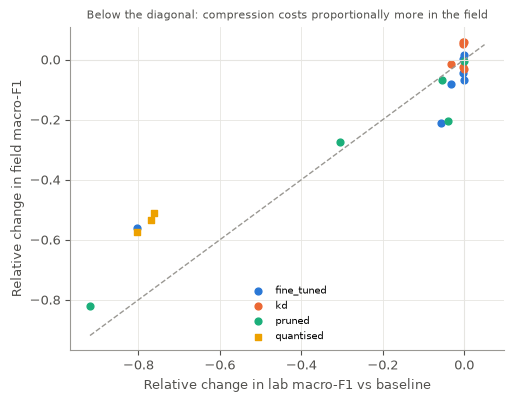


mobilenet_v3_small: change from the baseline (lab 0.995, field 0.099). rel_diff = relative field change minus relative lab change; below zero means compression costs proportionally more in the field.
                                           model precision  lab_f1  field_f1  rel_lab_change  rel_field_change  rel_diff  rel_diff_ci_lo  rel_diff_ci_hi     field_hurt_more  size_gzip_mb  degenerate
                                   baseline-fp32      fp32   0.995     0.099           0.000             0.000     0.000           0.000           0.000                             5.545       False
      fine_tuned-global_magnitude_0p20_fine_tune      fp32   0.994     0.101          -0.001             0.016     0.017          -0.026           0.061 not distinguishable         5.536       False
      fine_tuned-global_magnitude_0p40_fine_tune      fp32   0.993     0.099          -0.002             0.004     0.005          -0.080           0.094 not distinguishable         5.572       False
   

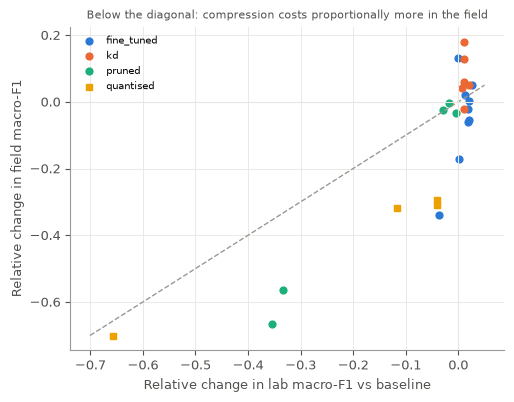


efficientnet_b0: change from the baseline (lab 0.959, field 0.119). rel_diff = relative field change minus relative lab change; below zero means compression costs proportionally more in the field.
                                           model precision  lab_f1  field_f1  rel_lab_change  rel_field_change  rel_diff  rel_diff_ci_lo  rel_diff_ci_hi     field_hurt_more  size_gzip_mb  degenerate
                                   baseline-fp32      fp32   0.959     0.119           0.000             0.000     0.000           0.000           0.000                            14.492       False
      fine_tuned-global_magnitude_0p20_fine_tune      fp32   0.977     0.112           0.019            -0.060    -0.079          -0.144          -0.016                 yes        14.583       False
      fine_tuned-global_magnitude_0p40_fine_tune      fp32   0.976     0.116           0.018            -0.022    -0.040          -0.118           0.044 not distinguishable        14.575       False
      

In [49]:
# 6.2 Part A - the joint table: every compressed model, lab cost vs field cost (no training; int8 models on CPU)
if not STAGES["joint_a"]:
    print("Skipped: STAGES[\"joint_a\"] is False (the saved joint tables are kept).")
else:
    JOINT = {}
    for arch in ARCHS_HERE:
        print(f"\n######## {arch}")
        JOINT[arch] = joint_table(cfg, data, comp_for(COMP, arch))

### 6.3–6.4 Part B · augment, then compress

The deployment-order question: train with the best augmentation, then compress. Part 5's models for **A0
(control) and A4 (the only arm that beat it)**, three seeds each, are compressed three ways:
* **pruned without recovery** (global magnitude, 20% and 40% by default);
* **pruned plus a short recovery fine-tune with the same arm** (2 epochs, masks kept);
* **int8 post-training quantisation**, with the recipe chosen on lab validation.

For each recipe, 6.4 reports A4's field gain over A0 with a paired interval. It also reports **how that gain
differs from the uncompressed gain (+0.015)**: `gain_survives` is "smaller after compression", "larger after compression" or "unchanged (n.s.)".
This is MobileNet only, because the RQ7.2 sweep has no EfficientNet arms. If the RQ7.1 export notebook was
run on these A0/A4 models, set `tflite_exports_dir` in 6.1 to add its TFLite int8 results as a descriptive row.

Outputs in `results/rq72_compressed/aug_then_compress/`: `aug_then_compress.csv`, `headline.txt` (sentences for
the report) and `fig_aug_then_compress.pdf` (A0 and A4 field scores per recipe).

In [50]:
# 6.3 Part B - augment, then compress: prune / recover / quantise RQ7.2's A0 and A4 models (~1.5-2 h on a T4)
if not STAGES["joint_b"]:
    print("Skipped: STAGES[\"joint_b\"] is False (finished runs are analysed in 6.4).")
else:
    run_aug_then_compress(cfg, data, COMP)

int8 recipe (chosen on lab_val): ptq_minmax_per_channel
[skip] global_magnitude20-rec__A0_none__seed42 already done
[skip] global_magnitude40-rec__A0_none__seed42 already done
[skip] global_magnitude20-rec__A4_combined__seed42 already done
[skip] global_magnitude40-rec__A4_combined__seed42 already done
[skip] global_magnitude20-rec__A0_none__seed43 already done
[skip] global_magnitude40-rec__A0_none__seed43 already done
[skip] global_magnitude20-rec__A4_combined__seed43 already done
[skip] global_magnitude40-rec__A4_combined__seed43 already done
[skip] global_magnitude20-rec__A0_none__seed44 already done
[skip] global_magnitude40-rec__A0_none__seed44 already done
[skip] global_magnitude20-rec__A4_combined__seed44 already done
[skip] global_magnitude40-rec__A4_combined__seed44 already done

Augment-then-compress runs finished. Results in /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq72_compressed/aug_then_compress


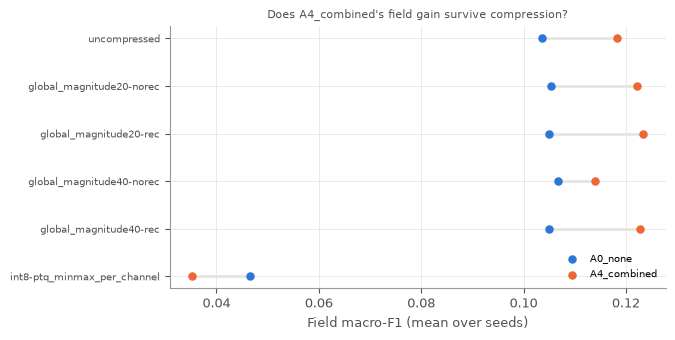

                     recipe  n_seeds  lab_A0_none  lab_A4_combined  field_A0_none  field_A4_combined  field_gain  gain_ci_lo  gain_ci_hi  lab_gain  sparsity  size_gzip_mb  gain_vs_uncompressed  inter_ci_lo  inter_ci_hi             gain_survives
               uncompressed        3        0.996            0.994          0.104              0.118       0.015       0.005       0.024    -0.003       0.0           NaN                   NaN          NaN          NaN                          
   global_magnitude20-norec        3        0.995            0.993          0.105              0.122       0.017       0.007       0.027    -0.002       0.2         4.791                 0.002       -0.003        0.007          unchanged (n.s.)
     global_magnitude20-rec        3        0.997            0.994          0.105              0.123       0.018       0.009       0.028    -0.002       0.2         4.792                 0.004       -0.002        0.009          unchanged (n.s.)
   global_magnitude4

In [51]:
# 6.4 Part B - does A4's field gain over A0 survive compression?
if not STAGES["joint_b"]:
    print("Skipped: STAGES[\"joint_b\"] is False (switch it on to analyse Part B).")
else:
    AUG = analyse_aug_then_compress(cfg, data, COMP)
    AUG

### 6.5–6.8 Part C · compress, then augment (exploratory)

In [52]:
# 6.5 Part C (exploratory) - shortlist per architecture: one parent per family, chosen on a fixed lab_val subset (never on the field test)
if not STAGES["joint_c"]:
    print("Skipped: STAGES[\"joint_c\"] is False (exploratory; about 12 h).")
else:
    COMPS = {a: comp_for(COMP, a) for a in ARCHS_HERE}   # per-architecture settings
    SHORT = {}
    for arch, c in COMPS.items():
        print(f"\n######## {arch}")
        SHORT[arch] = shortlist_compressed(cfg, data, c)
        evaluate_parents(cfg, data, c, SHORT[arch])   # each parent as-is, plus the baseline as-is, for reference

Skipped: STAGES["joint_c"] is False (exploratory; about 12 h).


In [53]:
# 6.6 Part C (exploratory) - fine-tune every parent with every arm, three seeds (GPU). Resumable: rerun after a disconnect.
if not STAGES["joint_c"]:
    print("Skipped: STAGES[\"joint_c\"] is False (exploratory; about 12 h).")
else:
    run_compressed_sweep(cfg, data, [(COMPS[a], SHORT[a]) for a in COMPS], time_budget_h=COMP["time_budget_h"])

Skipped: STAGES["joint_c"] is False (exploratory; about 12 h).


In [54]:
# 6.7 Part C (exploratory) - int8 branch: choose a PTQ recipe per parent on lab_val, then re-quantise finished fine-tunes (CPU).
# Can run on a second CPU-only runtime while 6.6 is still going; it skips runs that are not finished yet.
if not STAGES["joint_c"]:
    print("Skipped: STAGES[\"joint_c\"] is False (exploratory; about 12 h).")
else:
    if COMP["requantise"]:
        for arch, c in COMPS.items():
            print(f"\n######## {arch}")
            choice = choose_quant_recipes(cfg, data, c, SHORT[arch])
            run_requant_sweep(cfg, data, c, SHORT[arch], choice)

Skipped: STAGES["joint_c"] is False (exploratory; about 12 h).


In [55]:
# 6.8 Part C (exploratory) - analysis per architecture, then the best model across both
if not STAGES["joint_c"]:
    print("Skipped: STAGES[\"joint_c\"] is False (exploratory; about 12 h).")
else:
    TABLES = {}
    for arch, c in COMPS.items():
        print(f"\n######## {arch}")
        TABLES[arch] = analyse_compressed(cfg, data, c)
    comp_table = select_overall(cfg, data, COMP, TABLES)
    comp_table

Skipped: STAGES["joint_c"] is False (exploratory; about 12 h).


## Part 7 · RQ7.1 continued: export what would ship, and measure it

`export_benchmarks.ipynb`. For each checkpoint: FP32 ONNX, int8 dynamic and int8 static ONNX (each int8 format's
settings chosen on lab_val images, never a test set), and optionally TFLite (FP32 and dynamic-range int8). Every
exported file is checked against PyTorch, benchmarked on CPU in its own process (pinned threads, warm-up, median of
100 runs), and scored on lab and field **by running the exported file itself**. The measured artefact is always the
exported file, never the PyTorch `state_dict`.

By default it exports the MobileNetV3 baseline, Part 5's A0 and A4 runs, and Part 6B's pruned A4 (the deployment
candidate). Each checkpoint goes to `results/rq71_exports_<machine>/<condition>__seed<seed>/`; one that already has
a `summary.csv` is skipped (`EXPORT_FORCE = True` redoes it). Names that clashed with Part 4 carry `EXPORT_`.

In [56]:
# 7.1 Export settings. Paths follow Parts 0-6. Latency from different machines goes to different folders.
MACHINE = "colab" if IN_COLAB else platform.machine().lower()
DRIVE = ROOT
EXPORT_MANIFEST = ROOT / PIPELINE["full_manifest"]   # RQ7.2's split: exported files are scored on the same images
DATA_ROOT = ROOT                                     # manifest paths are relative to the root
RQ72_RESULTS = results_root(cfg, data)               # Part 5's run folders
OUT_ROOT = ROOT / "results" / f"rq71_exports_{MACHINE}"

# ---- which checkpoints
EXPORT_BASELINES = {   # condition label -> file; the C0 FP32 reference for RQ7.1
    "C0_mobilenetv3_baseline": ROOT / PIPELINE["baselines"]["mobilenet_v3_small"],
    # "C0_effnetb0_baseline": ROOT / PIPELINE["baselines"]["efficientnet_b0"],
}
BASELINE_SEED = 42
RQ72_ARMS = ["A0_none", "A4_combined"]       # Part 5 runs, every seed found
PART_B_RECIPES = ["global_magnitude40-rec"]  # Part 6B pruned + recovered models (the deployment candidate), if present
PART_B_ARMS = ["A4_combined"]                # which arms of those to export
EXTRA_CHECKPOINTS = []                       # (path, condition label, seed) for anything else

# ---- export and benchmark settings
FORMATS    = "fp32,int8_dynamic,int8_static"
CALIB_SIZE = 200         # lab_val images for static int8 calibration
QUANT_SEARCH = True      # try several int8 settings per format and keep the best on lab_val
SELECT_SIZE  = 520       # further lab_val images (not the calibration ones) used to choose; never test
CACHE_MAX_SIDE = cfg["cache_max_side"]   # keeps inputs identical to RQ7.2's image cache
THREADS = 1              # pin it; report it
WARMUP  = 20
RUNS    = 100            # timed single-image runs (median reported); >= 50
EVAL_LIMIT = None        # None = full test sets; e.g. 300 for a quick check; 0 = latency only
EXPORT_FORCE = False     # True re-exports checkpoints that already have a summary.csv

# ---- build the list: (checkpoint, condition, seed, metrics.json to check against, or None)
CHECKPOINTS = [(p, name, BASELINE_SEED, None) for name, p in EXPORT_BASELINES.items()]
for arm in RQ72_ARMS:
    for ck in sorted(RQ72_RESULTS.glob(f"{arm}__seed*/best.pt")):
        seed = int(ck.parent.name.split("__seed")[1])
        CHECKPOINTS.append((ck, arm, seed, ck.parent / "metrics.json"))
for recipe in PART_B_RECIPES:
    for arm in PART_B_ARMS:
        for ck in sorted((ROOT / COMP["results_dir"] / "aug_then_compress").glob(f"{recipe}__{arm}__seed*/best.pt")):
            seed = int(ck.parent.name.split("__seed")[1])
            CHECKPOINTS.append((ck, f"{arm}+{recipe}", seed, ck.parent / "metrics.json"))
CHECKPOINTS += [(p, c, s, None) for p, c, s in EXTRA_CHECKPOINTS]

print(f"running on: {MACHINE}")
print(f"output:     {OUT_ROOT}")
print(f"manifest:   {'found' if EXPORT_MANIFEST.exists() else 'NOT FOUND'}  {EXPORT_MANIFEST}")
for ck, cond, seed, _ in CHECKPOINTS:
    print(f"  {'ok     ' if Path(ck).exists() else 'MISSING'}  {cond:40s} seed {seed}  {ck}")

running on: arm64
output:     /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq71_exports_arm64
manifest:   found  /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/data/old_split_files/data_split_resolved.csv
  ok       C0_mobilenetv3_baseline                  seed 42  /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/models/mobilenetv3_baseline_best.pth
  ok       A0_none                                  seed 42  /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq72_aligned/A0_none__seed42/best.pt
  ok       A0_none                                  seed 43  /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq72_aligned/A0_none__seed43/best.pt
  ok       A0_none                               

### 7.2 Write the export/benchmark script

This cell only saves `export_bench.py` next to the notebook. Each exported file is benchmarked in its own fresh process with no PyTorch loaded, which keeps latency and RAM numbers comparable across formats.

In [57]:
%%writefile export_bench.py
#!/usr/bin/env python3
"""
export_bench.py — PJT07 / RQ7.1: export a trained checkpoint and measure what ships.

For one PyTorch checkpoint this script:
  1. exports FP32 ONNX                                   (always)
  2. builds int8 variants with ONNX Runtime              (C1 dynamic, C2 static + calibration)
  3. optionally converts the FP32 ONNX to TFLite         (--tflite, needs onnx2tf + tensorflow)
  4. checks every exported file agrees with PyTorch      (catches a broken export)
  5. benchmarks every exported file on CPU               (fixed threads, warm-up, median of N)
  6. evaluates every exported file on lab and field test (macro-F1 of the *exported* model)
  7. writes one results.json per format in the shared schema, plus a summary CSV

The measured artefact is always the exported file, never the PyTorch state_dict:
size is bytes on disk, latency is the runtime that would ship, and accuracy is
computed by running that same file. That avoids the two classic RQ7.1 mistakes —
reporting state_dict size, and quantising then evaluating in FP32 by accident.

Example (Colab or local):
    python export_bench.py \
        --checkpoint results/rq72_aligned/A0_seed1/best.pt \
        --manifest "/content/drive/Shareddrives/COS 801 Group 6/data/data_split_resolved.csv" \
        --data-root "/content/drive/Shareddrives/COS 801 Group 6" \
        --out exports/A0_seed1 --threads 1 --runs 100

Quick plumbing check without data (random weights, no accuracy):
    python export_bench.py --dummy --num-classes 26 --out exports/dummy --eval-limit 0

Install:
    pip install torch torchvision onnx onnxruntime onnxscript scikit-learn psutil pillow pandas
    # only for --tflite:
    pip install onnx2tf tensorflow tf-keras onnx-graphsurgeon sng4onnx ai-edge-litert

Notes from testing (torch 2.14, onnxruntime 1.29, tensorflow 2.21, onnx2tf 2.6):
  * TFLite goes through onnx2tf's TensorFlow-converter backend. Its newer default
    backend wrote int8 files that returned garbage (inf/NaN, different on every
    load); the TF converter path gives files that match PyTorch.
  * Each exported file is benchmarked in its own fresh process with no PyTorch
    loaded, so one runtime cannot disturb another's numbers.
  * ONNX Runtime's *dynamic* int8 is often SLOWER than FP32 for CNNs on x86 CPUs
    (its integer convolution kernels are not well optimised there). That is a real
    result to report, not a bug; static int8 is the deployment-realistic ONNX case.
"""
from __future__ import annotations

import argparse
import json
import os
import platform
import statistics
import subprocess
import sys
import time
from pathlib import Path

import numpy as np

# ----------------------------------------------------------------------------- config
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def parse_args() -> argparse.Namespace:
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    src = p.add_argument_group("model")
    src.add_argument("--checkpoint", type=Path, help="PyTorch checkpoint (.pt/.pth): full model, state_dict, or dict with 'model'/'state_dict'")
    src.add_argument("--arch", default="mobilenet_v3_small", help="torchvision architecture name (default: mobilenet_v3_small)")
    src.add_argument("--num-classes", type=int, help="number of output classes; inferred from checkpoint or manifest if omitted")
    src.add_argument("--dummy", action="store_true", help="use random weights (plumbing test only)")
    src.add_argument("--img-size", type=int, default=224)

    data = p.add_argument_group("data")
    data.add_argument("--manifest", type=Path, help="data_split(_resolved).csv")
    data.add_argument("--data-root", type=Path, default=Path("."), help="folder the manifest paths are relative to")
    data.add_argument("--path-col", default=None, help="image path column (default: resolved_path if present, else path)")
    data.add_argument("--resize", type=int, default=None,
                      help="resize shorter side to this, then centre-crop img-size (default: plain resize to img-size). "
                           "MUST match the eval transform used in training.")
    data.add_argument("--cache-max-side", type=int, default=320,
                      help="reproduce rq72_v2's image cache (thumbnail to this, JPEG q95) before resizing; "
                           "0 = off. Default 320 matches CONFIG['cache_max_side'].")
    data.add_argument("--eval-limit", type=int, default=None,
                      help="max images per test set (default: all; 0 = skip accuracy)")
    data.add_argument("--calib-size", type=int, default=200, help="lab val images used to calibrate static int8")
    data.add_argument("--select-size", type=int, default=520,
                      help="further lab val images (disjoint from calibration, stratified by class) used to "
                           "choose int8 settings; never the test sets")
    data.add_argument("--no-quant-search", dest="quant_search", action="store_false",
                      help="skip the search: per-channel dynamic and percentile static, first/last layers in FP32")

    bench = p.add_argument_group("benchmark")
    bench.add_argument("--threads", type=int, default=1, help="CPU threads for inference (pin it; default 1)")
    bench.add_argument("--warmup", type=int, default=20)
    bench.add_argument("--runs", type=int, default=100, help="timed single-image runs (report median; >=50)")

    out = p.add_argument_group("output")
    out.add_argument("--out", type=Path, required=True, help="output folder for exported files and results")
    out.add_argument("--condition", default=None, help="condition label written to results (default: checkpoint stem)")
    out.add_argument("--seed", type=int, default=None, help="training seed, recorded in results")
    out.add_argument("--formats", default="fp32,int8_dynamic,int8_static",
                     help="comma list from: fp32,int8_dynamic,int8_static")
    out.add_argument("--tflite", action="store_true", help="also convert FP32 ONNX -> TFLite (fp32 + dynamic-range int8)")
    out.add_argument("--opset", type=int, default=17)
    # internal: benchmark one exported file in a clean process (no PyTorch loaded)
    p.add_argument("--worker", type=Path, help=argparse.SUPPRESS)
    p.add_argument("--classes-json", type=Path, help=argparse.SUPPRESS)
    return p.parse_args()


# ----------------------------------------------------------------------------- model
def build_model(arch: str, num_classes: int):
    """Prefer the group's shared/model.py so the architecture is identical to training."""
    try:
        from shared.model import build_model as shared_build  # type: ignore
        return shared_build(num_classes, arch=arch, freeze=False)
    except Exception:
        pass
    import torch.nn as nn
    import torchvision
    m = getattr(torchvision.models, arch)(weights=None)
    if hasattr(m, "classifier"):
        last = m.classifier[-1] if isinstance(m.classifier, nn.Sequential) else m.classifier
        new = nn.Linear(last.in_features, num_classes)
        if isinstance(m.classifier, nn.Sequential):
            m.classifier[-1] = new
        else:
            m.classifier = new
    elif hasattr(m, "fc"):
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    else:
        raise ValueError(f"don't know how to replace the head of {arch}")
    return m


def load_model(args, num_classes_hint: int | None):
    import torch
    classes = None
    if args.dummy:
        n = args.num_classes or num_classes_hint
        if not n:
            sys.exit("--dummy needs --num-classes or a manifest")
        return build_model(args.arch, n).eval(), classes

    if not args.checkpoint:
        sys.exit("give --checkpoint (or --dummy for a plumbing test)")
    obj = torch.load(args.checkpoint, map_location="cpu", weights_only=False)

    if isinstance(obj, torch.nn.Module):
        return obj.eval(), classes

    state = obj
    if isinstance(obj, dict):
        classes = obj.get("classes") or obj.get("class_names")
        if not classes and isinstance(obj.get("class_to_idx"), dict):
            # RQ7.2 / baseline-notebook format: {"class name": index}
            c2i = obj["class_to_idx"]
            classes = [c for c, _ in sorted(c2i.items(), key=lambda kv: kv[1])]
        arch = obj.get("architecture") or obj.get("arch")
        if arch and arch != args.arch:
            print(f"NOTE: checkpoint says architecture={arch}; using it instead of --arch {args.arch}")
            args.arch = arch
        if obj.get("image_size") and int(obj["image_size"]) != args.img_size:
            print(f"NOTE: checkpoint was trained at {obj['image_size']} px; using that instead of {args.img_size}")
            args.img_size = int(obj["image_size"])
        # Same key priority as rq72_v2's _unwrap, so both notebooks load the same weights.
        # (Picking "model" first loaded different weights from the baseline file.)
        if not (obj and all(torch.is_tensor(v) for v in obj.values())):
            found = None
            for key in ("state_dict", "model_state_dict", "model", "net", "weights", "ema"):
                v = obj.get(key)
                if isinstance(v, torch.nn.Module):
                    return v.eval(), classes
                if isinstance(v, dict) and v and all(torch.is_tensor(t) for t in v.values()):
                    found = key
                    state = v
                    break
            if found is None:
                sys.exit(f"no weights found in checkpoint; top-level keys: {list(obj)[:15]}")
            print(f"weights: '{found}' entry of the checkpoint (top-level keys: {list(obj)[:10]})")
    changed = True  # strip wrapper prefixes, as rq72_v2's _strip_prefixes does
    while changed:
        changed = False
        for pre in ("module.", "_orig_mod.", "model."):
            if state and all(k.startswith(pre) for k in state):
                state = {k[len(pre):]: v for k, v in state.items()}
                changed = True

    # infer the class count from the last 2-D weight if not given
    n = args.num_classes
    if n is None:
        last_w = [v for k, v in state.items() if k.endswith("weight") and getattr(v, "ndim", 0) == 2]
        n = last_w[-1].shape[0] if last_w else num_classes_hint
    m = build_model(args.arch, n)
    missing, unexpected = m.load_state_dict(state, strict=False)
    if missing or unexpected:
        sys.exit(f"checkpoint does not match {args.arch}: missing={missing[:5]} unexpected={unexpected[:5]}")
    return m.eval(), classes


# ----------------------------------------------------------------------------- data
def load_manifest(args):
    import pandas as pd
    df = pd.read_csv(args.manifest)
    if args.path_col:
        rel = df[args.path_col].astype(str)
    elif "resolved_path" in df.columns:  # as rq72_v2: resolved_path where present, else path
        rel = df["resolved_path"].where(df["resolved_path"].notna(), df["path"]).astype(str)
    else:
        rel = df["path"].astype(str)
    df["_file"] = [str(args.data_root / p) for p in rel]
    return df


def preprocess(path: str, args) -> np.ndarray:
    from PIL import Image
    img = Image.open(path)
    fmt = img.format
    img.load()
    if args.cache_max_side and not (max(img.size) <= args.cache_max_side and fmt == "JPEG"):
        # rq72_v2 trains and scores from a cache: images larger than cache_max_side are
        # thumbnailed and re-saved as JPEG q95; small JPEGs are kept byte for byte.
        import io
        img = img.convert("RGB")
        if max(img.size) > args.cache_max_side:
            img.thumbnail((args.cache_max_side, args.cache_max_side), Image.BILINEAR)
        buf = io.BytesIO()
        img.save(buf, "JPEG", quality=95)
        buf.seek(0)
        img = Image.open(buf)
    img = img.convert("RGB")
    s = args.img_size
    if args.resize:
        w, h = img.size
        r = args.resize / min(w, h)
        img = img.resize((round(w * r), round(h * r)), Image.BILINEAR)
        w, h = img.size
        left, top = (w - s) // 2, (h - s) // 2
        img = img.crop((left, top, left + s, top + s))
    else:
        img = img.resize((s, s), Image.BILINEAR)
    x = (np.asarray(img, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return x.transpose(2, 0, 1)[None]  # 1x3xHxW, NCHW


def test_sets(df, limit):
    sets = {
        "lab": df[(df.domain == "lab") & (df.split == "test")],
        "field": df[(df.domain == "field") & (df.split == "field_test")],
    }
    if limit:
        sets = {k: v.sample(min(limit, len(v)), random_state=0) for k, v in sets.items()}
    return sets


# ----------------------------------------------------------------------------- export
def export_fp32_onnx(model, path: Path, img_size: int, opset: int):
    import torch
    x = torch.randn(1, 3, img_size, img_size)
    kwargs = dict(input_names=["input"], output_names=["logits"], opset_version=opset,
                  dynamic_axes={"input": {0: "batch"}, "logits": {0: "batch"}})
    import warnings
    warnings.filterwarnings("ignore")
    try:  # the TorchScript exporter is the most predictable for CNNs
        torch.onnx.export(model, x, str(path), dynamo=False, **kwargs)
    except TypeError:  # older torch without the dynamo flag
        torch.onnx.export(model, x, str(path), **kwargs)
    import onnx
    onnx.checker.check_model(str(path))


class _Calib:
    """CalibrationDataReader for onnxruntime static quantisation."""
    def __init__(self, batches):
        self._it = iter([{"input": b} for b in batches])

    def get_next(self):
        return next(self._it, None)


# Candidate settings tried for each int8 format. The one with the best macro-F1 on held-out
# lab_val images is kept (never chosen on a test set). All are standard ONNX Runtime options.
QUANT_CANDIDATES = {
    "int8_dynamic": [
        ("per_tensor",            {"per_channel": False}),   # ONNX Runtime's default
        ("per_channel",           {"per_channel": True}),
        ("per_channel_conv_gemm", {"per_channel": True, "op_types": ["Conv", "Gemm", "MatMul"]}),
        ("per_channel_keep_ends", {"per_channel": True, "op_types": ["Conv", "Gemm", "MatMul"], "keep_ends": True}),
    ],
    "int8_static": [
        ("minmax",                {"calib": "MinMax"}),
        ("percentile",            {"calib": "Percentile"}),
        ("entropy",               {"calib": "Entropy"}),
        ("minmax_keep_ends",      {"calib": "MinMax", "keep_ends": True}),
        ("percentile_conv_gemm",  {"calib": "Percentile", "op_types": ["Conv", "Gemm", "MatMul"]}),
        ("percentile_keep_ends",  {"calib": "Percentile", "op_types": ["Conv", "Gemm", "MatMul"], "keep_ends": True}),
    ],
}


def _end_nodes(model_path: Path) -> list[str]:
    """Names of the first Conv and the last Gemm/MatMul: the layers most sensitive to int8."""
    import onnx
    nodes = onnx.load(str(model_path), load_external_data=False).graph.node
    first = next((n.name for n in nodes if n.op_type == "Conv"), None)
    last = next((n.name for n in reversed(nodes) if n.op_type in ("Gemm", "MatMul")), None)
    return [n for n in (first, last) if n]


def preprocess_for_quant(fp32: Path) -> Path:
    from onnxruntime.quantization import quant_pre_process
    pre = fp32.with_name(fp32.stem + "_pre.onnx")
    try:
        quant_pre_process(str(fp32), str(pre), skip_symbolic_shape=True)
        return pre
    except Exception:
        return fp32  # pre-processing is an optimisation; fall back to the raw graph


def quantize(pre: Path, out: Path, kind: str, cfg: dict, calib_batches=None):
    import logging
    logging.getLogger().setLevel(logging.ERROR)
    from onnxruntime.quantization import QuantType, quantize_dynamic, quantize_static
    from onnxruntime.quantization import CalibrationMethod, QuantFormat
    common = {"per_channel": cfg.get("per_channel", True),
              "op_types_to_quantize": cfg.get("op_types"),
              "nodes_to_exclude": _end_nodes(pre) if cfg.get("keep_ends") else None}
    if kind == "int8_dynamic":
        quantize_dynamic(str(pre), str(out), weight_type=QuantType.QInt8, **common)
    elif kind == "int8_static":
        if not calib_batches:
            raise ValueError("static int8 needs calibration images (lab val split)")
        method = getattr(CalibrationMethod, cfg.get("calib", "MinMax"))
        extra = {"CalibPercentile": 99.999} if cfg.get("calib") == "Percentile" else {}
        common["per_channel"] = True
        quantize_static(str(pre), str(out), _Calib(calib_batches), quant_format=QuantFormat.QDQ,
                        activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8,
                        calibrate_method=method, extra_options=extra, **common)


def batch_predict(path: Path, X: np.ndarray, bs: int = 32) -> np.ndarray:
    """Top-1 predictions for a stack of preprocessed images (selection only, not timed)."""
    import onnxruntime as ort
    so = ort.SessionOptions()
    so.log_severity_level = 3
    sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
    name = sess.get_inputs()[0].name
    return np.concatenate([sess.run(None, {name: X[i:i + bs]})[0].argmax(1) for i in range(0, len(X), bs)])


def macro_f1_present(y_true, y_pred) -> float:
    from sklearn.metrics import f1_score
    return float(f1_score(y_true, y_pred, labels=sorted(set(y_true)), average="macro", zero_division=0))


def search_quant(kind: str, pre: Path, fp32: Path, out: Path, calib, Xsel, ysel, search: bool) -> tuple[str, list[dict]]:
    """Quantise with each candidate, score on held-out lab_val, keep the best as `out`."""
    cands = QUANT_CANDIDATES[kind] if search else [QUANT_CANDIDATES[kind][1 if kind == "int8_dynamic" else 5]]
    rows, best = [], None
    for name, cfg in cands:
        tmp = out.with_name(f"{out.stem}__{name}.onnx")
        try:
            quantize(pre, tmp, kind, cfg, calib)
        except Exception as e:
            rows.append({"format": kind, "config": name, "val_macro_f1": None, "note": f"failed: {e}"[:200]})
            continue
        f1 = macro_f1_present(ysel, batch_predict(tmp, Xsel)) if Xsel is not None else None
        rows.append({"format": kind, "config": name, "val_macro_f1": None if f1 is None else round(f1, 4),
                     "file_mb": round(tmp.stat().st_size / 2**20, 3), "note": ""})
        print(f"    {name:24s} lab_val macro-F1 {'-' if f1 is None else f'{f1:.4f}'}")
        if best is None or (f1 is not None and (best[1] is None or f1 > best[1])):
            if best:
                best[2].unlink(missing_ok=True)
            best = (name, f1, tmp)
        else:
            tmp.unlink(missing_ok=True)
    if best is None:
        raise RuntimeError(f"every {kind} candidate failed")
    best[2].replace(out)
    for r in rows:
        r["chosen"] = r["config"] == best[0]
    return best[0], rows


def export_tflite(fp32_onnx: Path, out_dir: Path) -> dict[str, Path]:
    """FP32 ONNX -> TFLite via onnx2tf. Produces fp32 and dynamic-range-quantised int8."""
    tf_dir = out_dir / "tflite_tmp"
    cmd = [sys.executable, "-m", "onnx2tf", "-i", str(fp32_onnx), "-o", str(tf_dir), "-osd", "-odrqt", "-qt", "per-channel", "-n"]
    # onnx2tf 2.x defaults to a direct-flatbuffer writer whose int8 files were broken in testing;
    # -tb tf_converter selects the TensorFlow converter. onnx2tf 1.x has no -tb flag and already
    # uses the TensorFlow converter, so only pass the flag when this version knows it.
    helptext = subprocess.run([sys.executable, "-m", "onnx2tf", "-h"], capture_output=True, text=True).stdout
    if "--tflite_backend" in helptext:
        cmd += ["-tb", "tf_converter"]
    print("[export] TFLite via onnx2tf (TensorFlow converter backend) ...")
    proc = subprocess.run(cmd, stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
    if proc.returncode != 0:
        raise RuntimeError("onnx2tf failed: " + proc.stderr.strip()[-600:])
    found = {}
    for f in tf_dir.glob("*.tflite"):
        if f.name.endswith("_float32.tflite"):
            found["tflite_fp32"] = f
        elif f.name.endswith("_dynamic_range_quant.tflite"):
            found["tflite_int8_dynamic"] = f
    final = {}
    for k, f in found.items():
        dst = out_dir / f"model_{k}.tflite"
        f.replace(dst)
        final[k] = dst
    return final


# ----------------------------------------------------------------------------- runners
class OnnxRunner:
    def __init__(self, path: Path, threads: int):
        import onnxruntime as ort
        so = ort.SessionOptions()
        so.intra_op_num_threads = threads
        so.inter_op_num_threads = 1
        so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
        self.sess = ort.InferenceSession(str(path), so, providers=["CPUExecutionProvider"])
        self.inp = self.sess.get_inputs()[0].name

    def __call__(self, x: np.ndarray) -> np.ndarray:
        return self.sess.run(None, {self.inp: x})[0]


class TFLiteRunner:
    """Inputs arrive NCHW; onnx2tf models are NHWC, so transpose on the way in."""
    def __init__(self, path: Path, threads: int):
        try:
            from ai_edge_litert.interpreter import Interpreter  # type: ignore
        except ImportError:
            import tensorflow as tf  # type: ignore
            Interpreter = tf.lite.Interpreter
        self.it = Interpreter(model_path=str(path), num_threads=threads)
        self.it.allocate_tensors()
        self.i = self.it.get_input_details()[0]
        self.o = self.it.get_output_details()[0]

    def __call__(self, x: np.ndarray) -> np.ndarray:
        x = x.transpose(0, 2, 3, 1).astype(np.float32)
        if tuple(self.i["shape"]) != x.shape:
            self.it.resize_tensor_input(self.i["index"], x.shape)
            self.it.allocate_tensors()
        self.it.set_tensor(self.i["index"], x)
        self.it.invoke()
        return self.it.get_tensor(self.o["index"])


def rss_mb() -> float:
    import psutil
    return psutil.Process().memory_info().rss / 2**20


def benchmark(make_runner, x: np.ndarray, warmup: int, runs: int) -> dict:
    """Single-image CPU latency. Load + warm-up first, then time each call separately."""
    rss0 = rss_mb()
    runner = make_runner()
    for _ in range(warmup):
        runner(x)
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        runner(x)
        times.append((time.perf_counter() - t0) * 1000)
    times.sort()
    return {
        "latency_ms_median": round(statistics.median(times), 3),
        "latency_ms_p90": round(times[int(0.9 * (len(times) - 1))], 3),
        "latency_ms_mean": round(statistics.fmean(times), 3),
        "latency_ms_std": round(statistics.pstdev(times), 3),
        "rss_delta_mb": round(rss_mb() - rss0, 1),
        "runs": runs, "warmup": warmup,
    }, runner


def evaluate(runner, df_set, class_to_idx, args) -> dict:
    from sklearn.metrics import accuracy_score, f1_score
    y_true, y_pred, n_skipped = [], [], 0
    for f, c in zip(df_set["_file"], df_set["class"]):
        if c not in class_to_idx:
            n_skipped += 1
            continue
        logits = runner(preprocess(f, args))
        y_true.append(class_to_idx[c])
        y_pred.append(int(np.argmax(logits, axis=1)[0]))
    labels = sorted(set(y_true))  # macro over classes present in this test set
    return {
        "macro_f1": round(float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)), 4),
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "n": len(y_true), "n_skipped_unknown_class": n_skipped,
    }


# ----------------------------------------------------------------------------- main
def env_block() -> dict:
    import onnxruntime, torch
    try:
        commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True).stdout.strip() or None
    except Exception:
        commit = None
    try:
        import cpuinfo  # type: ignore
        cpu = cpuinfo.get_cpu_info().get("brand_raw")
    except Exception:
        cpu = platform.processor() or platform.machine()
    return {"python": platform.python_version(), "torch": torch.__version__,
            "onnxruntime": onnxruntime.__version__, "platform": platform.platform(),
            "cpu": cpu, "cpu_count": os.cpu_count(), "commit": commit}


def worker(args):
    """Runs in a fresh process with no PyTorch: benchmark, parity, evaluate one file."""
    path = args.worker
    x = np.load(args.out / "_bench_input.npy")
    ref = np.load(args.out / "_bench_ref.npy")
    classes = json.loads(args.classes_json.read_text()) if args.classes_json else []
    class_to_idx = {c: i for i, c in enumerate(classes)}

    if path.suffix == ".tflite":
        make, runtime = (lambda: TFLiteRunner(path, args.threads)), "tflite"
    else:
        make, runtime = (lambda: OnnxRunner(path, args.threads)), "onnxruntime"
    lat, runner = benchmark(make, x, args.warmup, args.runs)

    out = runner(x)
    diff = float(np.abs(out - ref).max()) if np.all(np.isfinite(out)) else float("inf")
    parity = {"max_abs_logit_diff": round(diff, 5), "top1_agrees": bool(np.argmax(out) == np.argmax(ref))}

    metrics = {}
    if args.manifest and args.eval_limit != 0:
        df = load_manifest(args)
        for dom, sub in test_sets(df, args.eval_limit).items():
            print(f"  [eval] {dom}: {len(sub)} images", file=sys.stderr)
            r = evaluate(runner, sub, class_to_idx, args)
            metrics[f"{dom}_macro_f1"] = r["macro_f1"]
            metrics[f"{dom}_accuracy"] = r["accuracy"]
            metrics[f"{dom}_n"] = r["n"]
        if "lab_macro_f1" in metrics and "field_macro_f1" in metrics:
            metrics["gap_macro_f1"] = round(metrics["lab_macro_f1"] - metrics["field_macro_f1"], 4)

    rt = {}
    if runtime == "tflite":
        try:
            import ai_edge_litert
            rt["tflite_runtime"] = f"ai_edge_litert {getattr(ai_edge_litert, '__version__', '?')}"
        except ImportError:
            import tensorflow as tf
            rt["tflite_runtime"] = f"tensorflow {tf.__version__}"
    print("@@RESULT@@" + json.dumps({"latency": lat, "parity": parity, "metrics": metrics, "runtime": rt}))


def main():
    args = parse_args()
    if args.worker:
        return worker(args)
    args.out.mkdir(parents=True, exist_ok=True)
    formats = [f.strip() for f in args.formats.split(",") if f.strip()]

    df = load_manifest(args) if args.manifest else None
    manifest_classes = sorted(df["class"].unique()) if df is not None else None

    model, ckpt_classes = load_model(args, len(manifest_classes) if manifest_classes else None)
    n_out = model(__import__("torch").zeros(1, 3, args.img_size, args.img_size)).shape[1]

    # class order: the checkpoint's own list wins; sorted manifest classes is the fallback
    classes = list(ckpt_classes) if ckpt_classes else manifest_classes
    if classes is not None and len(classes) != n_out:
        sys.exit(f"model has {n_out} outputs but {len(classes)} classes were found — "
                 "pass the training class list (save it in the checkpoint as 'classes').")
    if ckpt_classes is None and classes is not None:
        print("NOTE: class order taken as sorted(manifest classes). If training used a different "
              "order, store 'classes' in the checkpoint or accuracy will be wrong.")
    class_to_idx = {c: i for i, c in enumerate(classes)} if classes else {}
    if manifest_classes and classes:
        unknown = sorted(set(manifest_classes) - set(classes))
        if unknown:
            print(f"WARNING: {len(unknown)} manifest classes are not in the checkpoint's class list "
                  f"(e.g. {unknown[:3]}); those test images are skipped. Map the names before reporting.")

    condition = args.condition or (args.checkpoint.stem if args.checkpoint else "dummy")
    x_bench = np.random.default_rng(0).standard_normal((1, 3, args.img_size, args.img_size)).astype(np.float32)

    # ---- 1. export
    files: dict[str, Path] = {}
    fp32 = args.out / "model_fp32.onnx"
    print(f"[export] fp32 onnx -> {fp32}")
    export_fp32_onnx(model, fp32, args.img_size, args.opset)
    files["onnx_fp32"] = fp32

    # lab_val only: calibration images, and a disjoint set to choose quantisation settings on
    calib, Xsel, ysel = None, None, None
    if df is not None and any(f.startswith("int8") for f in formats):
        val = df[(df.domain == "lab") & (df.split == "val") & df["class"].isin(class_to_idx)]
        cal_df = val.sample(min(args.calib_size, len(val)), random_state=0)
        calib = [preprocess(f, args) for f in cal_df["_file"]]
        rest = val.drop(cal_df.index)
        if args.quant_search and args.select_size and len(rest):
            per_class = max(1, args.select_size // max(1, rest["class"].nunique()))
            import pandas as pd
            sel_df = pd.concat([g.sample(min(len(g), per_class), random_state=1)
                                for _, g in rest.groupby("class", sort=True)])
            Xsel = np.concatenate([preprocess(f, args) for f in sel_df["_file"]])
            ysel = np.array([class_to_idx[c] for c in sel_df["class"]])
            ref_f1 = macro_f1_present(ysel, batch_predict(fp32, Xsel))
            print(f"[select] {len(calib)} calibration + {len(ysel)} selection images, both from lab_val; "
                  f"FP32 scores {ref_f1:.4f} on the selection set")

    quant_choice, search_rows = {}, []
    pre = preprocess_for_quant(fp32) if any(f.startswith("int8") for f in formats) else None
    if "int8_dynamic" in formats:
        p = args.out / "model_int8_dynamic.onnx"
        print(f"[export] int8 dynamic -> {p}")
        quant_choice["onnx_int8_dynamic"], rows = search_quant("int8_dynamic", pre, fp32, p, None, Xsel, ysel,
                                                               args.quant_search)
        search_rows += rows
        files["onnx_int8_dynamic"] = p

    if "int8_static" in formats:
        if calib is None:
            print("[export] skipping int8 static: needs --manifest for calibration images")
        else:
            p = args.out / "model_int8_static.onnx"
            print(f"[export] int8 static ({len(calib)} calibration images) -> {p}")
            quant_choice["onnx_int8_static"], rows = search_quant("int8_static", pre, fp32, p, calib, Xsel, ysel,
                                                                  args.quant_search)
            search_rows += rows
            files["onnx_int8_static"] = p
    if pre is not None and pre != fp32:
        pre.unlink(missing_ok=True)
    if search_rows:
        import pandas as pd
        pd.DataFrame(search_rows).to_csv(args.out / "quant_search.csv", index=False)
        print("  chosen: " + ", ".join(f"{k} = {v}" for k, v in quant_choice.items()))

    if args.tflite:
        try:
            files.update(export_tflite(fp32, args.out))
        except Exception as e:
            print(f"[export] TFLite conversion failed ({e}); continuing with ONNX only")

    # ---- 2. benchmark + evaluate each file in its own process.
    # PyTorch and TFLite in one process corrupt TFLite's int8 kernels (NaN outputs),
    # and a clean process also gives fairer latency and RAM numbers.
    import torch
    with torch.no_grad():
        ref = model(torch.from_numpy(x_bench)).numpy()
    np.save(args.out / "_bench_input.npy", x_bench)
    np.save(args.out / "_bench_ref.npy", ref)
    (args.out / "classes.json").write_text(json.dumps(classes or []))

    env, rows = env_block(), []
    for name, path in files.items():
        print(f"[bench] {name}: {args.warmup} warm-up + {args.runs} timed runs on {args.threads} thread(s)")
        cmd = [sys.executable, str(Path(__file__).resolve()), "--worker", str(path), "--out", str(args.out),
               "--classes-json", str(args.out / "classes.json"), "--img-size", str(args.img_size),
               "--threads", str(args.threads), "--warmup", str(args.warmup), "--runs", str(args.runs),
               "--data-root", str(args.data_root)]
        if args.manifest:
            cmd += ["--manifest", str(args.manifest)]
        if args.path_col:
            cmd += ["--path-col", args.path_col]
        if args.resize:
            cmd += ["--resize", str(args.resize)]
        cmd += ["--cache-max-side", str(args.cache_max_side)]
        if args.eval_limit is not None:
            cmd += ["--eval-limit", str(args.eval_limit)]
        envvars = {**os.environ, "TF_CPP_MIN_LOG_LEVEL": "3"}
        proc = subprocess.run(cmd, capture_output=True, text=True, env=envvars)
        line = next((l for l in reversed(proc.stdout.splitlines()) if l.startswith("@@RESULT@@")), None)
        if proc.returncode != 0 or line is None:
            print(f"  FAILED ({name}):\n" + (proc.stderr or proc.stdout)[-2000:])
            continue
        w = json.loads(line[len("@@RESULT@@"):])
        lat, metrics, parity = w["latency"], w["metrics"], w["parity"]
        if name in ("onnx_fp32", "tflite_fp32") and parity["max_abs_logit_diff"] > 1e-2:
            print(f"  WARNING: {name} differs from PyTorch by {parity['max_abs_logit_diff']} — check the export")
        if not np.isfinite(parity["max_abs_logit_diff"]):
            print(f"  WARNING: {name} produced non-finite outputs — do not report its numbers")

        size_mb = round(path.stat().st_size / 2**20, 3)
        result = {
            "rq": "7.1", "condition": condition, "format": name, "seed": args.seed,
            "arch": args.arch, "n_classes": int(n_out),
            "metrics": metrics,
            "cost": {"file_mb": size_mb, "device": "cpu", "threads": args.threads,
                     "input_shape": [1, 3, args.img_size, args.img_size], **lat},
            "parity_vs_pytorch": parity,
            "quant_config": quant_choice.get(name),
            "artefact": path.name,
            "env": {**env, **w.get("runtime", {})},
        }
        (args.out / f"results_{name}.json").write_text(json.dumps(result, indent=2))
        rows.append({"format": name, "file_mb": size_mb, **{k: lat[k] for k in ("latency_ms_median", "latency_ms_p90")},
                     **metrics, "max_abs_logit_diff": parity["max_abs_logit_diff"]})
        print(f"  {size_mb} MB · median {lat['latency_ms_median']} ms · " +
              " · ".join(f"{k}={v}" for k, v in metrics.items() if "f1" in k))

    for tmp in ("_bench_input.npy", "_bench_ref.npy"):
        (args.out / tmp).unlink(missing_ok=True)
    import shutil
    shutil.rmtree(args.out / "tflite_tmp", ignore_errors=True)

    # ---- 3. summary
    import pandas as pd
    summ = pd.DataFrame(rows)
    base = summ.loc[summ.format == "onnx_fp32"].iloc[0]
    summ["size_reduction_x"] = (base.file_mb / summ.file_mb).round(2)
    summ["speedup_x"] = (base.latency_ms_median / summ.latency_ms_median).round(2)
    for col in ("lab_macro_f1", "field_macro_f1"):
        if col in summ:
            summ[f"delta_{col}"] = (summ[col] - base[col]).round(4)
    summ.to_csv(args.out / "summary.csv", index=False)
    print("\n" + summ.to_string(index=False))
    print(f"\nWrote {len(rows)} results files and summary.csv to {args.out}")


if __name__ == "__main__":
    main()

Overwriting export_bench.py


In [58]:
# 7.3 Export and benchmark every checkpoint (each in its own process)
# Return memory the kernel no longer uses before the export processes start: TensorFlow's converter needs
# about 2 GB on top of everything Parts 4-6 left behind, and a full runtime kills the kernel.
if not STAGES["export"]:
    print("Skipped: STAGES[\"export\"] is False (existing exports are summarised below).")
else:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    try:
        import ctypes
        ctypes.CDLL("libc.so.6").malloc_trim(0)   # Linux / Colab; harmless to skip elsewhere
    except Exception:
        pass
    import subprocess, sys

    def run_one(ckpt, condition, seed):
        out = OUT_ROOT / f"{condition}__seed{seed}"   # same naming as rq72_v2
        cmd = [sys.executable, "export_bench.py",
               "--checkpoint", str(ckpt), "--cache-max-side", str(CACHE_MAX_SIDE),
               "--manifest", str(EXPORT_MANIFEST), "--data-root", str(DATA_ROOT),
               "--out", str(out), "--condition", condition, "--seed", str(seed),
               "--formats", FORMATS, "--calib-size", str(CALIB_SIZE), "--select-size", str(SELECT_SIZE),
               "--threads", str(THREADS), "--warmup", str(WARMUP), "--runs", str(RUNS)]
        if EVAL_LIMIT is not None:
            cmd += ["--eval-limit", str(EVAL_LIMIT)]
        if DO_TFLITE:
            cmd += ["--tflite"]
        if not QUANT_SEARCH:
            cmd += ["--no-quant-search"]
        print(f"\n{'=' * 70}\n{condition} · seed {seed}\n{'=' * 70}")
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                                env={**__import__("os").environ, "TF_CPP_MIN_LOG_LEVEL": "3"})
        log = []
        keep = ("[", "  ", "WARNING: ", "NOTE", "FAILED", "Wrote", "format ")  # the script's own progress lines
        for line in proc.stdout:
            log.append(line)
            if line.startswith(keep) and not line.startswith(("  torch.onnx", "  warnings.")):
                print(line, end="")
        ok = proc.wait() == 0
        out.mkdir(parents=True, exist_ok=True)
        (out / "run_log.txt").write_text("".join(log))  # full log, including library messages
        if not ok:
            print("".join(log[-40:]))
        return ok

    done = {}
    for ckpt, condition, seed, _ in CHECKPOINTS:
        if not Path(ckpt).exists():
            print(f"MISSING checkpoint, skipped: {ckpt}")
            continue
        if (OUT_ROOT / f"{condition}__seed{seed}" / "summary.csv").exists() and not EXPORT_FORCE:
            print(f"[skip] {condition} seed {seed}: already exported")
            continue
        done[(condition, seed)] = run_one(ckpt, condition, seed)

    print("\nFinished:", {f"{c} s{s}": "ok" if v else "FAILED" for (c, s), v in done.items()})

[skip] C0_mobilenetv3_baseline seed 42: already exported
[skip] A0_none seed 42: already exported
[skip] A0_none seed 43: already exported
[skip] A0_none seed 44: already exported

A4_combined · seed 42
[export] fp32 onnx -> /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq71_exports_arm64/A4_combined__seed42/model_fp32.onnx
[select] 200 calibration + 520 selection images, both from lab_val; FP32 scores 0.9962 on the selection set
[export] int8 dynamic -> /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq71_exports_arm64/A4_combined__seed42/model_int8_dynamic.onnx
    per_tensor               lab_val macro-F1 0.0105
    per_channel              lab_val macro-F1 0.0103
    per_channel_conv_gemm    lab_val macro-F1 0.0103
    per_channel_keep_ends    lab_val macro-F1 0.0550
[export] int8 static (200 calibration images) -> /Users/shreyabharat/Library/CloudStorag

### 7.4 Which int8 settings were chosen

For each checkpoint and int8 format, every candidate setting scored on the held-out lab_val selection images. `chosen` marks the one kept and benchmarked. Report the chosen setting per format in the methods section, and that it was selected on validation data only.

A large spread between settings is itself a finding: it shows how sensitive MobileNetV3 is to post-training quantisation choices.

In [59]:
# 7.4 Chosen int8 settings
import pandas as pd

frames = []
for f in sorted(OUT_ROOT.glob("*/quant_search.csv")):
    t = pd.read_csv(f)
    t.insert(0, "checkpoint", f.parent.name)
    frames.append(t)
if frames:
    qs = pd.concat(frames, ignore_index=True)
    display(qs.pivot_table(index=["format", "config"], columns="checkpoint", values="val_macro_f1").round(4))
    print("Chosen per checkpoint:")
    display(qs[qs.chosen][["checkpoint", "format", "config", "val_macro_f1"]].reset_index(drop=True))
    qs.to_csv(OUT_ROOT / "rq71_quant_search_all.csv", index=False)
else:
    print("No quant_search.csv files yet (QUANT_SEARCH off, or no int8 formats).")

checkpoint                          A0_none__seed42  A0_none__seed43  \
format       config                                                    
int8_dynamic per_channel                     0.0239           0.0031   
             per_channel_conv_gemm           0.0239           0.0031   
             per_channel_keep_ends           0.1519           0.0762   
             per_tensor                      0.0214           0.0031   
int8_static  entropy                         0.4285           0.3072   
             minmax                          0.4285           0.3072   
             minmax_keep_ends                0.4077           0.3038   
             percentile                      0.2724           0.4651   
             percentile_conv_gemm            0.2583           0.3990   
             percentile_keep_ends            0.6756           0.7588   

checkpoint                          A0_none__seed44  \
format       config                                   
int8_dynamic per_channel                     0.0230   
             per_channel_conv_gemm           0.0230   
             per_channel_keep_ends           0.0750   
             per_tensor                      0.0231   
int8_static  entropy                         0.3961   
             minmax                          0.3961   
             minmax_keep_ends                0.4079   
             percentile                      0.4595   
             percentile_conv_gemm            0.4563   
             percentile_keep_ends            0.5435   

checkpoint                          A4_combined+global_magnitude40-rec__seed42  \
format       config                                                              
int8_dynamic per_channel                                                0.0156   
             per_channel_conv_gemm                                      0.0156   
             per_channel_keep_ends                                      0.0556   
             per_tensor                                                 0.0159   
int8_static  entropy                                                    0.0476   
             minmax                                                     0.0476   
             minmax_keep_ends                                           0.0544   
             percentile                                                 0.3524   
             percentile_conv_gemm                                       0.3581   
             percentile_keep_ends                                       0.4697   

checkpoint                          A4_combined+global_magnitude40-rec__seed43  \
format       config                                                              
int8_dynamic per_channel                                                0.0102   
             per_channel_conv_gemm                                      0.0102   
             per_channel_keep_ends                                      0.0471   
             per_tensor                                                 0.0102   
int8_static  entropy                                                    0.1094   
             minmax                                                     0.1094   
             minmax_keep_ends                                           0.0961   
             percentile                                                 0.4300   
             percentile_conv_gemm                                       0.3981   
             percentile_keep_ends                                       0.5367   

checkpoint                          A4_combined+global_magnitude40-rec__seed44  \
format       config                                                              
int8_dynamic per_channel                                                0.0103   
             per_channel_conv_gemm                                      0.0103   
             per_channel_keep_ends                                      0.0639   
             per_tensor                                                 0.0103   
int8_static 

Chosen per checkpoint:


,checkpoint,format,config,val_macro_f1
0,A0_none__seed42,int8_dynamic,per_channel_keep_ends,0.1519
1,A0_none__seed42,int8_static,percentile_keep_ends,0.6756
2,A0_none__seed43,int8_dynamic,per_channel_keep_ends,0.0762
3,A0_none__seed43,int8_static,percentile_keep_ends,0.7588
4,A0_none__seed44,int8_dynamic,per_channel_keep_ends,0.0750
5,A0_none__seed44,int8_static,percentile_keep_ends,0.5435
6,A4_combined+global_magnitude40-rec__seed42,int8_dynamic,per_channel_keep_ends,0.0556
7,A4_combined+global_magnitude40-rec__seed42,int8_static,percentile_keep_ends,0.4697
8,A4_combined+global_magnitude40-rec__seed43,int8_dynamic,per_channel_keep_ends,0.0471
9,A4_combined+global_magnitude40-rec__seed43,int8_static,percentile_keep_ends,0.5367


### 7.5 Check: does the exported FP32 model score what RQ7.2 reported?

In [60]:
# 7.5 Exported FP32 vs RQ7.2's own scores
import json
import pandas as pd

TOL = 0.005
chk = []
for ck, cond, seed, mfile in CHECKPOINTS:
    rfile = OUT_ROOT / f"{cond}__seed{seed}" / "results_onnx_fp32.json"
    if mfile is None or not Path(mfile).exists() or not rfile.exists():
        continue
    rq72, mine = json.loads(Path(mfile).read_text()), json.loads(rfile.read_text())["metrics"]
    if "lab_macro_f1" not in mine:
        continue
    row = {"condition": cond, "seed": seed,
           "lab_rq72": round(rq72["lab_test"]["macro_f1"], 4), "lab_onnx": mine["lab_macro_f1"],
           "field_rq72": round(rq72["field_test"]["macro_f1"], 4), "field_onnx": mine["field_macro_f1"]}
    row["max_diff"] = round(max(abs(row["lab_rq72"] - row["lab_onnx"]), abs(row["field_rq72"] - row["field_onnx"])), 4)
    row["ok"] = row["max_diff"] <= TOL or (EVAL_LIMIT not in (None,))  # a subsample can't match exactly
    chk.append(row)
if chk:
    chk = pd.DataFrame(chk); display(chk)
    if EVAL_LIMIT is None and not chk.ok.all():
        print("MISMATCH: fix preprocessing / class order / manifest before reporting these rows.")
    elif EVAL_LIMIT is not None:
        print(f"EVAL_LIMIT={EVAL_LIMIT}: subsampled test sets, so only rough agreement is expected.")
    else:
        print("All exported FP32 models reproduce RQ7.2's scores.")
else:
    print("No RQ7.2 runs exported yet, nothing to check.")

,condition,seed,lab_rq72,lab_onnx,field_rq72,field_onnx,max_diff,ok
0,A0_none,42,0.9977,0.9977,0.1032,0.1038,0.0006,True
1,A0_none,43,0.9961,0.9961,0.1008,0.1008,0.0000,True
2,A0_none,44,0.9955,0.9955,0.1066,0.1066,0.0000,True
3,A4_combined,42,0.9949,0.9949,0.1179,0.1179,0.0000,True
4,A4_combined,43,0.9943,0.9943,0.1226,0.1222,0.0004,True
5,A4_combined,44,0.9923,0.9923,0.1142,0.1149,0.0007,True
6,A4_combined+global_magnitude40-rec,42,0.9939,0.9939,0.1216,0.1218,0.0002,True
7,A4_combined+global_magnitude40-rec,43,0.9912,0.9912,0.1250,0.1246,0.0004,True
8,A4_combined+global_magnitude40-rec,44,0.9933,0.9933,0.1216,0.1216,0.0000,True


All exported FP32 models reproduce RQ7.2's scores.


### 7.6 Combined table across checkpoints

Reads every `results_*.json` under `OUT_ROOT`. Headline numbers are means over seeds with the standard deviation, as the brief asks. A row with non-finite parity is flagged and must not be reported.

In [61]:
# 7.6 Combined table
if not any(OUT_ROOT.glob("*/results_*.json")):
    print(f"No exports under {OUT_ROOT} yet: run 7.3 and check it for FAILED lines.")
else:
    import json, math
    import pandas as pd

    rows = []
    for f in sorted(OUT_ROOT.glob("*/results_*.json")):
        r = json.loads(f.read_text())
        m, c, p = r["metrics"], r["cost"], r["parity_vs_pytorch"]
        rows.append({"condition": r["condition"], "format": r["format"], "seed": r["seed"],
                     "file_mb": c["file_mb"], "latency_ms": c["latency_ms_median"],
                     "lab_f1": m.get("lab_macro_f1"), "field_f1": m.get("field_macro_f1"),
                     "gap": m.get("gap_macro_f1"), "parity": p["max_abs_logit_diff"],
                     "quant_config": r.get("quant_config")})
    runs = pd.DataFrame(rows)
    bad = runs[~runs.parity.apply(lambda v: isinstance(v, (int, float)) and math.isfinite(v))]
    if len(bad):
        print("DO NOT REPORT — non-finite outputs:\n", bad[["condition", "format", "seed"]])
    display(runs)

    agg = (runs.groupby(["condition", "format"])
               .agg(n_seeds=("seed", "nunique"),
                    quant_config=("quant_config", lambda s: ", ".join(sorted({str(v) for v in s if v}))) ,
                    file_mb=("file_mb", "mean"),
                    latency_ms=("latency_ms", "mean"), latency_sd=("latency_ms", "std"),
                    lab_f1=("lab_f1", "mean"), lab_sd=("lab_f1", "std"),
                    field_f1=("field_f1", "mean"), field_sd=("field_f1", "std"),
                    gap=("gap", "mean"), gap_sd=("gap", "std"))
               .round(4).reset_index())
    agg.to_csv(OUT_ROOT / "rq71_summary_all.csv", index=False)
    display(agg)
    print("Saved", OUT_ROOT / "rq71_summary_all.csv")

,condition,format,seed,file_mb,latency_ms,lab_f1,field_f1,gap,parity,quant_config
0,A0_none,onnx_fp32,42,5.912,4.534,0.9977,0.1038,0.8939,0.00001,NaN
1,A0_none,onnx_int8_dynamic,42,1.647,5.584,0.1563,0.0546,0.1017,6.53282,per_channel_keep_ends
2,A0_none,onnx_int8_static,42,1.863,1.563,0.6321,0.0718,0.5603,3.39769,percentile_keep_ends
3,A0_none,tflite_fp32,42,5.910,1.791,0.9977,0.1038,0.8939,0.00000,NaN
4,A0_none,tflite_int8_dynamic,42,1.657,1.470,0.9977,0.1049,0.8928,0.35959,NaN
5,A0_none,onnx_fp32,43,5.912,4.469,0.9961,0.1008,0.8953,0.00001,NaN
6,A0_none,onnx_int8_dynamic,43,1.647,5.538,0.1203,0.0373,0.0830,9.98001,per_channel_keep_ends
7,A0_none,onnx_int8_static,43,1.863,1.568,0.7092,0.0782,0.6310,3.62283,percentile_keep_ends
8,A0_none,tflite_fp32,43,5.910,1.783,0.9961,0.1008,0.8953,0.00001,NaN
9,A0_none,tflite_int8_dynamic,43,1.657,1.466,0.9965,0.1005,0.8960,0.34842,NaN


,condition,format,n_seeds,quant_config,file_mb,latency_ms,latency_sd,lab_f1,lab_sd,field_f1,field_sd,gap,gap_sd
0,A0_none,onnx_fp32,3,nan,5.912,4.5157,0.0407,0.9964,0.0011,0.1037,0.0029,0.8927,0.0034
1,A0_none,onnx_int8_dynamic,3,per_channel_keep_ends,1.647,5.5650,0.0240,0.1308,0.0222,0.0450,0.0088,0.0858,0.0147
2,A0_none,onnx_int8_static,3,percentile_keep_ends,1.863,1.5667,0.0032,0.6118,0.1089,0.0727,0.0051,0.5391,0.1041
3,A0_none,tflite_fp32,3,nan,5.910,1.7867,0.0040,0.9964,0.0011,0.1037,0.0029,0.8927,0.0034
4,A0_none,tflite_int8_dynamic,3,nan,1.657,1.4683,0.0021,0.9970,0.0006,0.1022,0.0024,0.8948,0.0017
5,A4_combined,onnx_fp32,3,nan,5.912,4.5593,0.1317,0.9938,0.0014,0.1183,0.0037,0.8755,0.0030
6,A4_combined,onnx_int8_dynamic,3,per_channel_keep_ends,1.647,5.6103,0.0068,0.0757,0.0048,0.0375,0.0017,0.0382,0.0054
7,A4_combined,onnx_int8_static,3,"percentile, percentile_keep_ends",1.844,1.5040,0.1206,0.4763,0.0649,0.0599,0.0080,0.4164,0.0570
8,A4_combined,tflite_fp32,3,nan,5.910,1.7957,0.0099,0.9938,0.0014,0.1183,0.0037,0.8755,0.0030
9,A4_combined,tflite_int8_dynamic,3,nan,1.657,1.4720,0.0000,0.9939,0.0014,0.1195,0.0009,0.8744,0.0016


Saved /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq71_exports_arm64/rq71_summary_all.csv


### 7.7 Pareto figures — macro-F1 against size and against latency

One point per condition × format (mean over seeds, bars = ±1 SD). The dashed line is the mobile budget: set `BUDGET_MB` and `BUDGET_MS` to the group's agreed numbers. Field F1 is the deployment-relevant number; lab F1 is shown faded for reference.

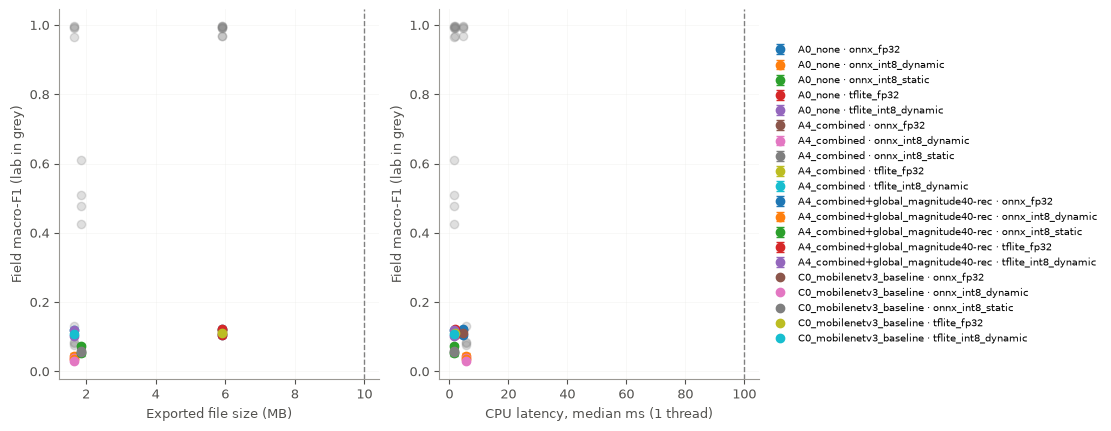

Saved /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq71_exports_arm64/rq71_pareto.png


In [62]:
# 7.7 Pareto figures
if "agg" not in globals() or agg.empty:
    print("Nothing to plot yet.")
else:
    import matplotlib.pyplot as plt

    BUDGET_MB, BUDGET_MS = 10.0, 100.0   # the group's mobile budget

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
    for ax, (x, xlab, budget) in zip(axes, [("file_mb", "Exported file size (MB)", BUDGET_MB),
                                            ("latency_ms", f"CPU latency, median ms ({THREADS} thread)", BUDGET_MS)]):
        for _, r in agg.iterrows():
            label = f"{r.condition} · {r.format}"
            ax.errorbar(r[x], r.field_f1, yerr=r.field_sd if pd.notna(r.field_sd) else None,
                        fmt="o", capsize=3, label=label)
            ax.scatter(r[x], r.lab_f1, marker="o", alpha=0.25, color="grey")
        ax.axvline(budget, ls="--", color="grey", lw=1)
        ax.set_xlabel(xlab); ax.set_ylabel("Field macro-F1 (lab in grey)")
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.savefig(OUT_ROOT / "rq71_pareto.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved", OUT_ROOT / "rq71_pareto.png")

## Part 8 · The inputs for RQ7.3

*Can the model reliably abstain on out-of-distribution inputs such as an unfamiliar crop or a non-plant photograph?*

| RQ7.3 needs | Why | Written here |
|---|---|---|
| **Logits**, not only probabilities | energy scores and temperature scaling work on logits | `logits/<model>.npz` |
| **lab_val** as well as the test sets | temperatures and thresholds must be fitted on validation data, never on a test set | `logits_lab_val` in each file |
| The same models RQ7.1 and RQ7.2 report | so §6 and §7 talk about one model | A0 and A4 (3 seeds each), both baselines, Part 6B's pruned A4 |
| Seed groups | a 3-seed ensemble is a free uncertainty score | `handoff.json["ensembles"]`, scored in the table |
| The exact preprocessing | OOD images must be scored like the in-distribution ones | `rq73_helpers.py`, checked in 8.3 |
| Which model ships | the abstention threshold is set for the deployed model | `handoff.json["deployment"]`, with its exported files |

Each logits file holds `logits_<split>`, `y_<split>` and `path_<split>` for `lab_val`, `lab_test` and
`field_test`, with columns in `class_order`; the baselines' outputs are already reordered. Every file is checked
against the scores Parts 3, 5 and 6 reported (`matches_reported`).

In [63]:
# 8.1 Settings for the RQ7.3 inputs
RQ73 = {
    "out_dir": "results/rq73_inputs",
    "arms": ["A0_none", "A4_combined"],      # Part 5 runs, every seed found: A0 = control, A4 = the arm that helped
    "baselines": True,                        # the two group baselines, outputs reordered to the shared class order
    "part_b": ["global_magnitude40-rec"],     # Part 6B pruned + recovered MobileNets, if present
    "deployment": ("global_magnitude40-rec", "A4_combined"),  # the recommended model; falls back to plain A4
    "splits": ["lab_val", "lab_test", "field_test"],
    "force": False,                           # True recomputes logits that already exist
}

In [64]:
# 8.2 Functions: which models, their logits on every split, the handoff file and the preprocessing helper
RQ73_HELPER = '''"""PJT07 / RQ7.3 helper, written by the pipeline notebook (Part 8). Loads the models listed in handoff.json and
scores any image with exactly the preprocessing RQ7.1 and RQ7.2 used, so out-of-distribution images (non-plant
photos, an unfamiliar crop, Cassava, corrupted inputs) are scored the same way as the in-distribution ones.

    import sys; sys.path.insert(0, "<root>/results/rq73_inputs")
    import rq73_helpers as h
    net = h.load_model(h.HANDOFF["deployment"]["keys"][0], root="<root>")
    logits = h.logits(net, list_of_image_paths)          # numpy, shape (n, 26), columns in h.CLASSES order
"""
import io
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as T
from PIL import Image

HERE = Path(__file__).resolve().parent
HANDOFF = json.loads((HERE / "handoff.json").read_text())
CLASSES = HANDOFF["class_order"]
_P = HANDOFF["preprocessing"]
_TF = T.Compose([T.Resize(tuple(_P["resize"])), T.ToTensor(), T.Normalize(_P["mean"], _P["std"])])


def load_image(path):
    """The pixels the models were trained and tested on. Small JPEGs (all of PlantVillage) are used as they are;
    anything larger than cache_max_side, or not a JPEG, is thumbnailed to it and re-saved as JPEG quality 95."""
    with Image.open(path) as im:
        fmt = im.format
        im.load()
        if max(im.size) <= _P["cache_max_side"] and fmt == "JPEG":
            return im.convert("RGB")
        im = im.convert("RGB")
        if max(im.size) > _P["cache_max_side"]:
            im.thumbnail((_P["cache_max_side"], _P["cache_max_side"]), Image.BILINEAR)
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=_P["jpeg_quality"])
        buf.seek(0)
        return Image.open(buf).convert("RGB")


def preprocess(path):
    return _TF(load_image(path))


def build_model(arch, n_classes=len(CLASSES)):
    m = getattr(torchvision.models, arch)(weights=None)
    m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, n_classes)
    return m


def load_model(key, root):
    """key: a "key" in HANDOFF["models"]; root: the shared drive root. Outputs are in CLASSES order."""
    spec = next(m for m in HANDOFF["models"] if m["key"] == key)
    sd = torch.load(Path(root) / spec["checkpoint"], map_location="cpu", weights_only=True)
    sd = sd.get("model_state_dict", sd)
    for pre in ("module.", "_orig_mod.", "model."):
        if all(k.startswith(pre) for k in sd):
            sd = {k[len(pre):]: v for k, v in sd.items()}
    net = build_model(spec["arch"])
    net.load_state_dict(sd)
    perm = spec.get("output_perm")
    if perm:   # the checkpoint's outputs are in another class order: reorder the head to CLASSES
        idx = torch.as_tensor(perm)
        head = net.classifier[-1]
        with torch.no_grad():
            head.weight.copy_(head.weight[idx].clone())
            head.bias.copy_(head.bias[idx].clone())
    return net.eval()


@torch.no_grad()
def logits(net, paths, batch_size=64, device="cpu"):
    net = net.to(device).eval()
    out = []
    for i in range(0, len(paths), batch_size):
        x = torch.stack([preprocess(p) for p in paths[i:i + batch_size]]).to(device)
        out.append(net(x).float().cpu())
    return torch.cat(out).numpy()


def load_logits(key, root):
    """The saved in-distribution logits: a dict with logits_<split>, y_<split> and path_<split> for each split."""
    spec = next(m for m in HANDOFF["models"] if m["key"] == key)
    z = np.load(Path(root) / spec["logits"], allow_pickle=True)
    return {k: z[k] for k in z.files}
'''


def _softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def _rq73_models(cfg, data) -> list[dict]:
    root = data["root"]
    out = []
    for arm in RQ73["arms"]:
        for d in sorted(results_root(cfg, data).glob(f"{arm}__seed*")):
            if (d / "metrics.json").exists() and (d / "best.pt").exists():
                out.append({"key": d.name, "kind": "rq72", "arch": cfg["backbone"], "arm": arm,
                            "seed": int(d.name.split("__seed")[1]), "recipe": "uncompressed",
                            "path": d / "best.pt", "check": d / "metrics.json", "perm": None})
    if RQ73["baselines"]:
        checks = {"mobilenet_v3_small": "B0_mobilenetv3__seed0", "efficientnet_b0": "B1_effnetb0__seed0"}
        for arch, rel in PIPELINE["baselines"].items():
            if (root / rel).exists():
                out.append({"key": f"baseline_{arch}", "kind": "baseline", "arch": arch, "arm": "group baseline",
                            "seed": 42, "recipe": "uncompressed", "path": root / rel,
                            "check": results_root(cfg, data) / checks.get(arch, "-") / "metrics.json",
                            "perm": head_order(cfg, data, comp_for(COMP, arch))})   # Part 6's class-order fix
    part_b = _comp_out(_aug_comp(COMP), data)
    for recipe in RQ73["part_b"]:
        for d in sorted(part_b.glob(f"{recipe}__*__seed*")):
            if (d / "metrics.json").exists() and (d / "best.pt").exists():
                _, arm, s = d.name.split("__")
                out.append({"key": d.name, "kind": "part_b", "arch": "mobilenet_v3_small", "arm": arm,
                            "seed": int(s[4:]), "recipe": recipe, "path": d / "best.pt",
                            "check": d / "metrics.json", "perm": None})
    return out


@torch.no_grad()
def _logits(model, sdf, cfg, device):
    model = model.to(device).eval()
    dl = make_loader(sdf, build_eval_transform(cfg["img_size"]), cfg, device)
    return torch.cat([model(x.to(device)).float().cpu() for x, _ in dl]).numpy()


def build_rq73_inputs(cfg, data) -> pd.DataFrame:
    root, df, n = data["root"], data["df"], len(data["classes"])
    out = root / RQ73["out_dir"]
    (out / "logits").mkdir(parents=True, exist_ok=True)
    device = get_device()
    splits = {s: df[df.role == s] for s in RQ73["splits"]}
    rows, specs = [], []
    for m in _rq73_models(cfg, data):
        f = out / "logits" / f"{m['key']}.npz"
        if RQ73["force"] or not f.exists():
            net = _load_fp32(m["path"], m["arch"], n, m["perm"])
            arrays = {"classes": np.array(data["classes"])}
            for s, sdf in splits.items():
                arrays[f"logits_{s}"] = _logits(net, sdf, cfg, device).astype(np.float32)
                arrays[f"y_{s}"] = sdf.y.to_numpy()
                arrays[f"path_{s}"] = sdf[cfg["path_col"]].astype(str).to_numpy()
            np.savez_compressed(f, **arrays)
            del net
            print(f"  logits saved: {m['key']}")
        z = np.load(f, allow_pickle=True)
        row = {k: m[k] for k in ("key", "kind", "arch", "arm", "seed", "recipe")}
        for s in splits:
            sc = score(_softmax(z[f"logits_{s}"]), z[f"y_{s}"], n, cfg["ece_bins"])
            row[f"{s}_macro_f1"], row[f"{s}_ece"] = round(sc["macro_f1"], 4), round(sc["ece"], 4)
        # the logits must reproduce the scores already reported for this model
        if m["check"] and Path(m["check"]).exists():
            j = json.loads(Path(m["check"]).read_text())
            diffs = [abs(row[f"{s}_macro_f1"] - j[s]["macro_f1"]) for s in ("lab_test", "field_test")
                     if s in j and f"{s}_macro_f1" in row]
            row["matches_reported"] = bool(diffs) and max(diffs) <= 0.005
        rows.append(row)
        specs.append({**row, "checkpoint": os.path.relpath(m["path"], root),
                      "logits": os.path.relpath(f, root), "output_perm": m["perm"]})
    table = pd.DataFrame(rows)
    if table.empty:
        raise FileNotFoundError("No models found: run Parts 3, 5 and 6B first.")

    # three-seed ensembles (mean of softmax over seeds): RQ7.3's free deep-ensemble score
    ens = {}
    for (kind, arm, recipe), g in table[table.kind != "baseline"].groupby(["kind", "arm", "recipe"]):
        if len(g) < 2:
            continue
        key = f"ensemble__{arm}" + ("" if recipe == "uncompressed" else f"__{recipe}")
        ens[key] = list(g.key)
        er = {"key": key, "kind": "ensemble", "arch": g.arch.iloc[0], "arm": arm, "seed": len(g), "recipe": recipe}
        for s in splits:
            zs = [np.load(out / "logits" / f"{k}.npz", allow_pickle=True) for k in g.key]
            p = np.mean([_softmax(z[f"logits_{s}"]) for z in zs], 0)
            sc = score(p, zs[0][f"y_{s}"], n, cfg["ece_bins"])
            er[f"{s}_macro_f1"], er[f"{s}_ece"] = round(sc["macro_f1"], 4), round(sc["ece"], 4)
        rows.append(er)
    table = pd.DataFrame(rows)

    # the deployment candidate: pruned + recovered A4 if Part 6B produced it, else the uncompressed A4 runs
    recipe, arm = RQ73["deployment"]
    dep = [s["key"] for s in specs if s["recipe"] == recipe and s["arm"] == arm]
    if dep:
        cond, why = f"{arm}+{recipe}", "the smallest model whose field gain from A4 survived compression (Part 6B)"
    else:
        dep = [s["key"] for s in specs if s["kind"] == "rq72" and s["arm"] == arm]
        recipe, cond, why = "uncompressed", arm, f"Part 6B's {recipe} models are missing, so uncompressed {arm}"
    exports = sorted(os.path.relpath(p, root) for p in (root / "results").glob("rq71_exports_*/*/model_*")
                     if p.parent.name.split("__seed")[0] == cond)

    handoff = {
        "created": datetime.now().isoformat(timespec="seconds"),
        "paths": "relative to the shared drive root",
        "class_order": list(data["classes"]),
        "preprocessing": {
            "cache_max_side": cfg["cache_max_side"], "jpeg_quality": 95,
            "rule": "small JPEGs used as they are; larger or non-JPEG images thumbnailed to cache_max_side "
                    "(bilinear) and re-saved as JPEG q95",
            "resize": [cfg["img_size"], cfg["img_size"]], "mean": list(MEAN), "std": list(STD),
            "helper": os.path.relpath(out / "rq73_helpers.py", root)},
        "splits": {s: {"n": int(len(sdf)), "source": "PlantDoc" if s.startswith("field") else "PlantVillage",
                       "use": ("FIT HERE: temperature, thresholds, score choices" if s == "lab_val" else
                               "REPORT ONLY: never used to choose anything")}
                   for s, sdf in splits.items()},
        "models": specs,
        "ensembles": ens,
        "deployment": {"keys": dep, "recipe": recipe, "arm": arm, "exported_files": exports, "why": why},
    }
    (out / "handoff.json").write_text(json.dumps(handoff, indent=2, default=str))
    (out / "rq73_helpers.py").write_text(RQ73_HELPER)
    table.to_csv(out / "in_distribution_scores.csv", index=False)
    print(f"\nWrote {out}: handoff.json, rq73_helpers.py, in_distribution_scores.csv and logits/ for "
          f"{len(specs)} models ({len(ens)} ensembles).")
    if "matches_reported" in table and not table.matches_reported.dropna().all():
        print("WARNING: some logits do not reproduce the reported scores; check before using them.")
    return table


def check_rq73_helper(cfg, data, k: int = 8) -> float:
    """The helper must give the same logits as the notebook, from the raw images, for lab and field images alike."""
    import importlib.util
    out = data["root"] / RQ73["out_dir"]
    spec = importlib.util.spec_from_file_location("rq73_helpers", out / "rq73_helpers.py")
    h = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(h)
    worst = 0.0
    for m in h.HANDOFF["models"][:2] + [m for m in h.HANDOFF["models"] if m.get("output_perm")][:1]:
        net, z = h.load_model(m["key"], data["root"]), h.load_logits(m["key"], data["root"])
        for s in ("lab_test", "field_test"):
            sdf = data["df"][data["df"].role == s].head(k)
            got = h.logits(net, list(sdf.src))
            worst = max(worst, float(np.abs(got - z[f"logits_{s}"][:k]).max()))
    print(f"rq73_helpers.py reproduces the saved logits from the raw images: max |difference| = {worst:.2e}")
    if worst > 1e-3:
        print("WARNING: larger than expected. Check the preprocessing before RQ7.3 scores any new images.")
    return worst

In [65]:
# 8.3 Build the RQ7.3 inputs, then check the helper reproduces them from the raw images
if not STAGES["rq73_inputs"]:
    print("Skipped: STAGES[\"rq73_inputs\"] is False (switch it on to write the RQ7.3 inputs).")
else:
    RQ73_TABLE = build_rq73_inputs(cfg, data)
    display(RQ73_TABLE)
    check_rq73_helper(cfg, data)

  logits saved: A0_none__seed42
  logits saved: A0_none__seed43
  logits saved: A0_none__seed44
  logits saved: A4_combined__seed42
  logits saved: A4_combined__seed43
  logits saved: A4_combined__seed44
  logits saved: baseline_mobilenet_v3_small
  logits saved: baseline_efficientnet_b0
  logits saved: global_magnitude40-rec__A0_none__seed42
  logits saved: global_magnitude40-rec__A0_none__seed43
  logits saved: global_magnitude40-rec__A0_none__seed44
  logits saved: global_magnitude40-rec__A4_combined__seed42
  logits saved: global_magnitude40-rec__A4_combined__seed43
  logits saved: global_magnitude40-rec__A4_combined__seed44

Wrote /Users/shreyabharat/Library/CloudStorage/GoogleDrive-u19031786@tuks.co.za/Shared drives/COS 801 Group 6/results/rq73_inputs: handoff.json, rq73_helpers.py, in_distribution_scores.csv and logits/ for 14 models (4 ensembles).


,key,kind,arch,arm,seed,recipe,lab_val_macro_f1,lab_val_ece,lab_test_macro_f1,lab_test_ece,field_test_macro_f1,field_test_ece,matches_reported
0,A0_none__seed42,rq72,mobilenet_v3_small,A0_none,42,uncompressed,0.9973,0.0018,0.9977,0.0011,0.1038,0.6881,True
1,A0_none__seed43,rq72,mobilenet_v3_small,A0_none,43,uncompressed,0.9960,0.0011,0.9961,0.0018,0.1008,0.6794,True
2,A0_none__seed44,rq72,mobilenet_v3_small,A0_none,44,uncompressed,0.9968,0.0018,0.9955,0.0017,0.1066,0.6831,True
3,A4_combined__seed42,rq72,mobilenet_v3_small,A4_combined,42,uncompressed,0.9944,0.0017,0.9949,0.0025,0.1179,0.6129,True
4,A4_combined__seed43,rq72,mobilenet_v3_small,A4_combined,43,uncompressed,0.9940,0.0025,0.9943,0.0017,0.1222,0.5949,True
5,A4_combined__seed44,rq72,mobilenet_v3_small,A4_combined,44,uncompressed,0.9950,0.0017,0.9923,0.0024,0.1149,0.6142,True
6,baseline_mobilenet_v3_small,baseline,mobilenet_v3_small,group baseline,42,uncompressed,0.9945,0.0023,0.9949,0.0015,0.0993,0.6937,True
7,baseline_efficientnet_b0,baseline,efficientnet_b0,group baseline,42,uncompressed,0.9623,0.0057,0.9592,0.0073,0.1087,0.4241,True
8,global_magnitude40-rec__A0_none__seed42,part_b,mobilenet_v3_small,A0_none,42,global_magnitude40-rec,0.9970,0.0015,0.9964,0.0008,0.1106,0.5962,True
9,global_magnitude40-rec__A0_none__seed43,part_b,mobilenet_v3_small,A0_none,43,global_magnitude40-rec,0.9965,0.0019,0.9970,0.0013,0.0992,0.6067,True


rq73_helpers.py reproduces the saved logits from the raw images: max |difference| = 3.05e-05
